# Algoritmos Genéticos para Otimização de Hiperparâmetros de Classificadores de Texto
## Aplicação ao Corpus das Mensagens Presidenciais ao Congresso Nacional — Mandato Lula III (2023–2026)

---

| | |
|---|---|
| **Disciplina** | Algoritmos Genéticos |
| **Professor** | Prof. Keiji Yamanaka |
| **Discente** | Ferdinand Rafols |
| **Programa** | PPGEELT/UFU · EL142A · 2026/1 |
| **Repositório** | [`ferdinandrafols/mestrado-llm-acgl`](https://github.com/ferdinandrafols/mestrado-llm-acgl) |

---

## Articulação com o Mestrado

Este notebook é o **terceiro vértice** de uma pesquisa que atravessa três disciplinas do PPGEELT:

| Disciplina | Contribuição para este notebook |
|---|---|
| **Aprendizado de Máquinas (EL142A)** | Corpus, léxico V1, pipeline TF-IDF + classificadores supervisionados |
| **Visualização da Informação** | Paleta de identidade, heatmaps, princípios de Ware & Munzner |
| **Algoritmos Genéticos (este)** | Otimização automática dos hiperparâmetros do pipeline de AM |

**Pergunta central deste notebook:**
> *É possível usar um Algoritmo Genético para encontrar automaticamente a melhor configuração do pipeline TF-IDF + classificador — superando a escolha manual de hiperparâmetros?*

---

## Estrutura do Notebook

| Fase | Conteúdo |
|---|---|
| **0** | Setup do ambiente |
| **1** | Extração do corpus dos PDFs (autocontido) |
| **2** | Léxico V1 — original da Etapa 1 de AM — rotulagem e diagnóstico |
| **3** | Diagnóstico crítico do V1 → motivação para o refinamento |
| **4** | Léxico V3 — refinado — comparação V1 → V3 |
| **5** | Fundamentos do Algoritmo Genético |
| **6** | AG em ação: otimização dos hiperparâmetros |
| **7** | Resultados, visualizações e análise evolutiva |
| **8** | Conclusões e próximos passos |


---

## Versão 10 (V10) — Atualização para a revisão do artigo (RITA)

A **Fase 7**, ao final do notebook, acrescenta três validações pedidas na revisão, **sem alterar as fases anteriores** (preservadas como registro do que foi rodado):

1. **Estimativa de generalização sem viés de seleção** — validação cruzada *aninhada* (seleção de hiperparâmetros no laço interno, avaliação no externo).
2. **Tabela 2 com dispersão e teste de Wilcoxon** entre os classificadores, com o **TF-IDF padronizado** entre os três (corrige a Seção 4.3 do artigo).
3. **Tamanhos de efeito** (rank-biserial) dos testes de Wilcoxon já reportados.

Terminologia padronizada para **«agenda governamental»**.

---

### Alterações da V11/V12 (agosto/2026)

- **Fase 1** — `normalize_text` passa a remontar palavras partidas pela hifenização
  tipográfica do PDF, antes do colapso de espaços. Compostos legítimos preservam o hífen.
- **Fase 1C** — nova auditoria que quantifica remontagens, resíduo e tamanho de vocabulário.
- **Fase 7.4 (V12)** — execução comparativa **automática** das duas condições,
  sem edição manual de flag nem reexecução do notebook.
- Flag `CORRIGIR_HIFENIZACAO` controla a condição. Nenhuma outra etapa do pipeline
  foi alterada, de modo que a comparação isola o efeito do artefato.

### V13 (correções de auditoria)
- 7.3: tamanhos de efeito sempre recomputados dos vetores (a V12 podia reportar
  o r antigo por fallback silencioso com nome de variável errado).
- Figuras/aninhada: fallback com o cromossomo pré-correção substituído por erro
  explícito, evitando figuras geradas com configuração desatualizada.


### V14 (execução de registro automatizada)
- **Fase 0R** (início): monta Drive, confere/ajusta versões contra o §5, arquiva
  checkpoints anteriores com carimbo de data.
- **Validação final** (fim): confere sentinelas contra a execução de referência
  de 13/08/2026, diffa os checkpoints novos contra os arquivados e grava
  certificado JSON no Drive. Uso: apenas *Executar tudo* e ler o veredito.


### V15.3 (19/10/2026) · correções da auditoria pré-revisão (RITA, revisão maior)
1. 6D/6E: LR e RF passam a usar o **TF-IDF do AG** (`params_finais`), o C ótimo do LR e o
   melhor RF da grade. A V15.2 fixava `max_features=2995`, `C=10` e `max_depth=30`.
2. 6B/6C: o número de **avaliações únicas do AG por semente** é registrado, e o Random
   Search recebe exatamente esse orçamento na mesma semente (a V15.2 fixava 38).
3. V15.2 (circularidade): vocabulário de referência da hifenização reconstruído antes de
   reconstruir os corpora; as 30 medidas por condição são persistidas (JSON e CSV).
4. 7.4: respeita `UNIDADE_ANALISE` e restaura o vocabulário de referência ao final.
5. Nova célula 6F-b: rotulados, resíduo e total por ano (denominadores da Tabela 7).
6. Sentinelas de **parágrafo** declaradas a partir da execução V15.1 de 19/08/2026;
   as grandezas que dependem do orçamento pareado do RS entram como registro novo.
7. Textos fixos substituídos por conclusões derivadas dos dados; Fig. 5 lê o baseline da
   execução; Fig. 6 escreve "n.s." em vez de "equiv.".
8. Resumo e contraste (cél. final) regenerados na mesma sessão.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# CONFIGURAÇÃO V15.1 — Persistência no Google Drive
# ============================================================
import os

# >>> AJUSTE para a sua pasta no Drive <<<
DRIVE_BASE = "/content/drive/MyDrive/Mestrado/Etapa4_RITA"

# ═════════════════════════════════════════════════════════════════════════════
#  ►►►  CHAVE ÚNICA DA V15  ◄◄◄
#  "pagina"    = comportamento da V14 (reproduz a execução de registro)
#  "paragrafo" = segmentação real por geometria de linha (correção V15)
#
#  Aperte "Executar tudo" uma vez com cada valor. Os diretórios são separados
#  por versão E por unidade, então uma execução NUNCA sobrescreve a outra.
# ═════════════════════════════════════════════════════════════════════════════
VERSAO          = "v15.3"   # (patch 15.3.1 só na célula 4: instalação de versões)
UNIDADE_ANALISE = "paragrafo"        # "pagina" | "paragrafo"
assert UNIDADE_ANALISE in ("pagina", "paragrafo")

RUN_DIR   = os.path.join(DRIVE_BASE, f"{VERSAO}_{UNIDADE_ANALISE}")
CKPT_DIR  = os.path.join(RUN_DIR, "checkpoints")
DIR_DADOS = os.path.join(RUN_DIR, "dados")
DIR_FIG   = os.path.join(RUN_DIR, "figuras")
for _d in (CKPT_DIR, DIR_DADOS, DIR_FIG):
    os.makedirs(_d, exist_ok=True)

# Checkpoints da V14 — LEITURA APENAS. Servem de referência para o diff da
# execução em modo "pagina". Nada nesta versão escreve neste diretório.
REFERENCIA_V14 = os.path.join(DRIVE_BASE, "checkpoints")
# V15.3 · referência da execução de parágrafo (V15.1, 19/08/2026) — LEITURA APENAS.
REFERENCIA_V151_PARAGRAFO = os.path.join(DRIVE_BASE, "v15.1_paragrafo", "checkpoints")

# Contraste pareado: fica FORA dos diretórios de unidade, para que as duas
# execuções depositem seus resumos no mesmo lugar.
DIR_CONTRASTE = os.path.join(DRIVE_BASE, f"{VERSAO}_contraste")
os.makedirs(DIR_CONTRASTE, exist_ok=True)

PDF_DIR_BASE = "/content"

print(f"{VERSAO} · unidade: {UNIDADE_ANALISE.upper()}")
print("Saídas desta execução :", RUN_DIR)
print("Referência V14 (r/o)  :", REFERENCIA_V14,
      "" if os.path.isdir(REFERENCIA_V14) else "  ⚠️ não encontrado")
print("Contraste             :", DIR_CONTRASTE)
print("PDFs lidos de         :", PDF_DIR_BASE)


v15.3 · unidade: PARAGRAFO
Saídas desta execução : /content/drive/MyDrive/Mestrado/Etapa4_RITA/v15.3_paragrafo
Referência V14 (r/o)  : /content/drive/MyDrive/Mestrado/Etapa4_RITA/checkpoints 
Contraste             : /content/drive/MyDrive/Mestrado/Etapa4_RITA/v15.3_contraste
PDFs lidos de         : /content


---
# Fase 0R (V14) — Execução de registro automatizada

Esta célula prepara a sessão para uma execução de registro **sem nenhum passo
manual**: monta o Drive se preciso, confere as versões de biblioteca contra as
publicadas no artigo (ajustando-as se divergirem), e arquiva os checkpoints da
execução anterior num diretório datado, para que a validação final possa
comparar as duas execuções.

**Se esta célula pedir reinício do runtime** (acontece só quando o Colab mudou
alguma versão), use *Ambiente de execução → Reiniciar sessão* e clique
*Executar tudo* de novo. Na segunda passada ela segue direto.

In [ ]:
# ── Fase 0R · V14 — preparação automática da execução de registro ────────────
EXECUCAO_DE_REGISTRO = True   # False = pula arquivamento e checagem de versões

import os, sys, shutil, subprocess
from datetime import datetime

# 1) Drive montado?
if EXECUCAO_DE_REGISTRO and not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

# 2) Versões — as mesmas do §5 do artigo
VERSOES_ESPERADAS = {"scikit-learn": "1.6.1", "scipy": "1.16.3",
                     "numpy": "2.0.2", "pandas": "2.2.2", "matplotlib": "3.10.0"}
import sklearn, scipy, numpy, pandas, matplotlib
_atuais = {"scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
           "numpy": numpy.__version__, "pandas": pandas.__version__,
           "matplotlib": matplotlib.__version__}
_div = {k: (_atuais[k], v) for k, v in VERSOES_ESPERADAS.items() if _atuais[k] != v}

# V15.3.1 · instalação VISÍVEL e verificada em interpretador novo. A versão anterior
# instalava com -q e check=False: uma falha do pip passava em silêncio e a célula
# pedia reinício sem ter mudado nada (foi o que aconteceu em 19/10/2026 no Colab,
# que veio com numpy 2.1.3 e pandas 2.2.3).
TOLERAR_VERSOES = True    # True = NÃO tenta instalar; segue com as versões atuais e as registra no certificado

def _versao_em_interpretador_novo(pacote):
    """Versão que um Python NOVO enxerga (o kernel atual segue com a versão já importada)."""
    r = subprocess.run([sys.executable, "-c",
                        f"import importlib.metadata as m; print(m.version('{pacote}'))"],
                       capture_output=True, text=True)
    return r.stdout.strip() or r.stderr.strip()[-200:]

if EXECUCAO_DE_REGISTRO and _div and TOLERAR_VERSOES:
    print("⚠️  Versões divergentes das publicadas, toleradas por decisão explícita (TOLERAR_VERSOES=True):")
    for k, (tem, quer) in _div.items():
        print(f"  {k}: atual {tem} | artigo {quer}")
    print("   Nenhuma instalação será tentada. O certificado registra as versões efetivas;")
    print("   sentinelas e diff dirão se a execução reproduz a referência.")
elif EXECUCAO_DE_REGISTRO and _div:
    print("Versões divergentes das publicadas:")
    for k, (tem, quer) in _div.items():
        print(f"  {k}: {tem} -> {quer}")
    pins = [f"{k}=={v}" for k, v in VERSOES_ESPERADAS.items() if k in _div]
    print("\nInstalando (saída do pip abaixo):")
    r = subprocess.run([sys.executable, "-m", "pip", "install", "--no-deps", "--force-reinstall"] + pins,
                       capture_output=True, text=True)
    print(r.stdout[-3000:]); print(r.stderr[-2000:])
    _instaladas = {k: _versao_em_interpretador_novo(k) for k in _div}
    print("\nVersões que o próximo interpretador vai carregar:", _instaladas)
    _ok = all(_instaladas[k] == VERSOES_ESPERADAS[k] for k in _div)
    if _ok:
        raise RuntimeError(
            "Versões instaladas com sucesso. Use 'Ambiente de execução → Reiniciar sessão' "
            "(NÃO 'Desconectar e excluir ambiente') e clique 'Executar tudo' de novo.")
    elif TOLERAR_VERSOES:
        print("\n⚠️  pip não conseguiu fixar as versões; seguindo com as atuais (TOLERAR_VERSOES=True).")
        print("    O certificado registra as versões efetivas; sentinelas e diff dirão se reproduz.")
    else:
        raise RuntimeError(
            "pip não conseguiu fixar as versões (veja a saída acima). Opções: (a) rodar numa célula "
            "nova `!pip install --no-deps --force-reinstall numpy==2.0.2 pandas==2.2.2`, reiniciar e "
            "executar tudo; (b) definir TOLERAR_VERSOES = True nesta célula para seguir com as versões "
            "atuais, registradas no certificado.")
print("Versões conferem com o §5 do artigo ✓" if not _div
      else "(seguindo com versões divergentes, registradas no certificado)")

# 3) Arquivar checkpoints/dados da execução anterior (uma vez por sessão)
ARQUIVO_ANTERIOR = None
if EXECUCAO_DE_REGISTRO and "_0R_JA_ARQUIVADO" not in globals():
    _stamp = datetime.now().strftime("%Y%m%dT%H%M")
    for _d in [d for d in (globals().get("CKPT_DIR"), globals().get("DIR_DADOS")) if d]:
        if os.path.isdir(_d) and os.listdir(_d):
            _dest = _d.rstrip("/") + f"_arquivado_{_stamp}"
            # Arquivos nativos do Google (.gsheet, .gdoc...) são ponteiros e não
            # podem ser copiados pelo filesystem montado — ignorados.
            _ign = shutil.ignore_patterns("*.gsheet", "*.gdoc", "*.gslides",
                                          "*.gdraw", "*.gform", "*.gtable", "*.gmap")
            try:
                shutil.copytree(_d, _dest, dirs_exist_ok=True, ignore=_ign)
            except shutil.Error as _e:
                _pulados = [os.path.basename(x[0]) for x in _e.args[0]]
                print(f"  (aviso: {len(_pulados)} arquivo(s) não copiável(is): {_pulados[:5]})")
            print(f"Arquivado: {_d} -> {_dest}")
            if "checkpoints" in _d:
                ARQUIVO_ANTERIOR = _dest
    _0R_JA_ARQUIVADO = True
if ARQUIVO_ANTERIOR is None and EXECUCAO_DE_REGISTRO:
    # tenta localizar o arquivo mais recente de sessoes anteriores
    _base = globals().get("CKPT_DIR", "")
    if _base:
        _pai = os.path.dirname(_base.rstrip("/"))
        _cands = sorted(d for d in os.listdir(_pai) if "checkpoints_arquivado_" in d) \
                 if os.path.isdir(_pai) else []
        if _cands:
            ARQUIVO_ANTERIOR = os.path.join(_pai, _cands[-1])
            print(f"Comparação final usará o arquivo mais recente: {ARQUIVO_ANTERIOR}")
# V15.1 · sem arquivo próprio ainda, o modo "pagina" compara com a V14
if ARQUIVO_ANTERIOR is None and EXECUCAO_DE_REGISTRO and UNIDADE_ANALISE == "pagina":
    if os.path.isdir(REFERENCIA_V14) and os.listdir(REFERENCIA_V14):
        ARQUIVO_ANTERIOR = REFERENCIA_V14
        print(f"Diff será contra os checkpoints da V14: {ARQUIVO_ANTERIOR}")
    else:
        print("⚠️  Checkpoints da V14 não encontrados — diff ficará 'não verificável'.")
if ARQUIVO_ANTERIOR is None and EXECUCAO_DE_REGISTRO and UNIDADE_ANALISE == "paragrafo":
    # V15.3 · a execução V15.1 de parágrafo (19/08/2026) passa a ser a referência
    if os.path.isdir(REFERENCIA_V151_PARAGRAFO) and os.listdir(REFERENCIA_V151_PARAGRAFO):
        ARQUIVO_ANTERIOR = REFERENCIA_V151_PARAGRAFO
        print(f"Diff será contra os checkpoints da V15.1 (parágrafo): {ARQUIVO_ANTERIOR}")
    else:
        print("⚠️  Checkpoints da V15.1 (parágrafo) não encontrados — diff ficará 'não verificável'.")

print("\nFase 0R concluída — pode seguir com a execução completa.")

⚠️  Versões divergentes das publicadas, toleradas por decisão explícita (TOLERAR_VERSOES=True):
  numpy: atual 2.1.3 | artigo 2.0.2
  pandas: atual 2.2.3 | artigo 2.2.2
   Nenhuma instalação será tentada. O certificado registra as versões efetivas;
   sentinelas e diff dirão se a execução reproduz a referência.
(seguindo com versões divergentes, registradas no certificado)
Diff será contra os checkpoints da V15.1 (parágrafo): /content/drive/MyDrive/Mestrado/Etapa4_RITA/v15.1_paragrafo/checkpoints

Fase 0R concluída — pode seguir com a execução completa.


---
# Fase 0 — Setup do Ambiente

Instalamos as bibliotecas necessárias e definimos a paleta de identidade visual do projeto
(compartilhada com os notebooks de AM e Visualização da Informação).


In [ ]:
# Instalação de dependências
!pip install -q pdfplumber scikit-learn pandas numpy matplotlib seaborn

print("✓ Dependências instaladas.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 100.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 101.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
✓ Dependências instaladas.


In [ ]:
import re
import gc
import json
import unicodedata
import random
import warnings
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pdfplumber

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

# ── Paleta de identidade do projeto (compartilhada entre os três notebooks) ──
PALETTE = {
    "navy":  "#0D1B2A",
    "amber": "#F59E0B",
    "2023":  "#059669",
    "2024":  "#10B981",
    "2025":  "#F59E0B",
    "2026":  "#DC2626",
    "muted": "#64748B",
    "light": "#F8FAFC",
    "green": "#16A34A",
    "red":   "#DC2626",
}

# ── Cores por classe temática (9 classes V3) ─────────────────────────────────
CORES_CLASSES = {
    "economia_desenvolvimento":       "#2563EB",
    "programas_sociais":              "#7C3AED",
    "saude":                          "#059669",
    "educacao_ciencia":               "#F59E0B",
    "reforma_agraria_agropecuaria":   "#92400E",
    "politica_externa":               "#0891B2",
    "infraestrutura_logistica":       "#EA580C",
    "meio_ambiente_energia":          "#16A34A",
    "governanca_institucional":       "#6B7280",
    "outros_institucional":           "#D1D5DB",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"]   = 110
plt.rcParams["savefig.dpi"]  = 150
plt.rcParams["font.family"]  = "DejaVu Sans"

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("✓ Setup concluído.")
print(f"  Paleta: {len(PALETTE)} cores de identidade")
print(f"  Classes: {len(CORES_CLASSES)} (9 temáticas + 1 residual)")


✓ Setup concluído.
  Paleta: 10 cores de identidade
  Classes: 10 (9 temáticas + 1 residual)


---
# Fase 1 — Extração do Corpus dos PDFs

## Corpus: Mensagens Presidenciais ao Congresso Nacional

O corpus é composto por **4 documentos oficiais** emitidos pelo presidente Luiz Inácio Lula da Silva
ao Congresso Nacional durante o terceiro mandato (2023–2026), conforme previsto no Art. 84 da
Constituição Federal.

| Ano | Páginas | Palavras | Arquivo |
|---|---|---|---|
| 2023 | 180 | 40.788 | `MensagemaoCongressoNacional2023.pdf` |
| 2024 | 333 | 109.205 | `mensagemaocongressonacional2024_vf.pdf` |
| 2025 | 668 | 220.982 | `MensagemCongressoNacional2025.pdf` |
| 2026 | 914 | 322.582 | `mensagem-ao-congresso-nacional-2026.pdf` |
| **Total** | **2.095** | **693.557** | — |

> **Nota metodológica:** o volume cresce dramaticamente ao longo do mandato (8× maior em 2026
> comparado a 2023). Por isso, todas as análises temáticas usam **proporções relativas**,
> não contagens absolutas.

## Estratégia de extração: processamento chunked

O PDF de 2026 tem 914 páginas (~11,5 MB). Carregar o arquivo inteiro de uma vez causa
estouro de memória no Colab. A solução é processar em **blocos de 120 páginas**,
fechando e reabrindo o arquivo a cada bloco para liberar RAM.

## Instruções

1. No menu lateral do Colab, clique em **Arquivos** (ícone de pasta)
2. Faça upload dos 4 PDFs na pasta raiz (`/content/`)
3. Execute as células abaixo em sequência


In [ ]:
# ── Catálogo do corpus ────────────────────────────────────────────────────────
MENSAGENS = [
    {"year": 2023, "filename": "MensagemaoCongressoNacional2023.pdf",
     "pages": 180,  "words_real": 40_788},
    {"year": 2024, "filename": "mensagemaocongressonacional2024_vf.pdf",
     "pages": 333,  "words_real": 109_205},
    {"year": 2025, "filename": "MensagemCongressoNacional2025.pdf",
     "pages": 668,  "words_real": 220_982},
    {"year": 2026, "filename": "mensagem-ao-congresso-nacional-2026.pdf",
     "pages": 914,  "words_real": 322_582},
]

PDF_DIR   = Path(PDF_DIR_BASE)        # definido na Configuração V9
CHUNK_SIZE = 120                       # páginas por bloco (evita OOM no 2026)

print("Corpus catalogado:")
df_meta = pd.DataFrame(MENSAGENS)
print(df_meta[["year","filename","pages","words_real"]].to_string(index=False))
print(f"\nTotal: {df_meta['pages'].sum():,} páginas / {df_meta['words_real'].sum():,} palavras")


Corpus catalogado:
 year                                filename  pages  words_real
 2023     MensagemaoCongressoNacional2023.pdf    180       40788
 2024  mensagemaocongressonacional2024_vf.pdf    333      109205
 2025       MensagemCongressoNacional2025.pdf    668      220982
 2026 mensagem-ao-congresso-nacional-2026.pdf    914      322582

Total: 2,095 páginas / 693,557 palavras


In [ ]:
# ── Funções de extração e normalização ───────────────────────────────────────
#
# V15 · CORREÇÃO DA UNIDADE DE ANÁLISE
# ─────────────────────────────────────────────────────────────────────────────
# Auditoria posterior (17/08/2026) identificou que a V14 NÃO segmentava
# parágrafos. Em extract_pdf_chunked, as páginas eram unidas por "\n\n" e
# segmentar_paragrafos dividia em "\n{2,}" — logo, o separador de PÁGINA era o
# separador de PARÁGRAFO. Como pdfplumber.extract_text() une linhas com "\n"
# simples, cada página virava exatamente uma unidade.
#
# Evidência: 2.095 páginas → 2.089 unidades; média de 332 palavras por unidade;
# e 2025 produziu 676 unidades para 668 páginas (excesso gerado pela remoção de
# linhas só-numéricas em normalize_text, que criava "\n\n" DENTRO da página).
#
# A V15 mantém intacto o caminho de página (para reproduzir a V14 bit a bit) e
# acrescenta um caminho de parágrafo baseado na GEOMETRIA das linhas.
# A unidade é escolhida por UNIDADE_ANALISE, definido na célula seguinte.
# ─────────────────────────────────────────────────────────────────────────────

# ── V11 · Correção de hifenização de fim de linha (INALTERADA) ────────────────
CORRIGIR_HIFENIZACAO = True
AUDITORIA_HIFEN = {"ocorrencias": 0, "amostras": []}
RAW_PDF_TEXT  = {}     # texto bruto por ano (páginas unidas por "\n\n")
RAW_PDF_LINES = {}     # V15: linhas com geometria, por ano -> lista de páginas

ENCLITICOS = ("se", "lo", "la", "los", "las", "me", "te", "nos", "vos",
              "lhe", "lhes")

_RE_HIFEN_QUEBRA = re.compile(r"([A-Za-zÀ-ÿ]{2,})-\n([a-zà-ÿ]{2,})")
_RE_PALAVRA_REF  = re.compile(r"[^\W\d_]+", re.UNICODE)
_RE_HIFEN_ATEST  = re.compile(r"[a-zà-ÿ]{2,}-[a-zà-ÿ]{2,}")

VOCAB_REF     = set()
VOCAB_HIF_REF = set()


def construir_vocabulario_referencia(textos):
    """Vocabulário a partir do texto com os trechos ambíguos REMOVIDOS."""
    VOCAB_REF.clear(); VOCAB_HIF_REF.clear()
    for t in textos:
        t_limpo = _RE_HIFEN_QUEBRA.sub(" ", t)
        VOCAB_REF.update(w.lower() for w in _RE_PALAVRA_REF.findall(t_limpo))
        VOCAB_HIF_REF.update(m.lower() for m in _RE_HIFEN_ATEST.findall(t_limpo))
    return len(VOCAB_REF), len(VOCAB_HIF_REF)


def _decidir_juncao(esq: str, dir_: str) -> str:
    e, d = esq.lower(), dir_.lower()
    if (e + d) in VOCAB_REF:           return "fusao"
    if (e + "-" + d) in VOCAB_HIF_REF: return "hifen"
    if d in ENCLITICOS:                return "hifen"
    return "fusao"


def _juntar_hifen(m):
    esq, dir_ = m.group(1), m.group(2)
    dec = _decidir_juncao(esq, dir_)
    AUDITORIA_HIFEN["ocorrencias"] += 1
    AUDITORIA_HIFEN[dec] = AUDITORIA_HIFEN.get(dec, 0) + 1
    if len(AUDITORIA_HIFEN["amostras"]) < 60:
        AUDITORIA_HIFEN["amostras"].append(f"{esq}-{dir_} -> {dec}")
    return f"{esq}-{dir_}" if dec == "hifen" else esq + dir_


def corrigir_hifenizacao(text: str) -> str:
    """Remonta palavras partidas pela quebra de linha do PDF."""
    return _RE_HIFEN_QUEBRA.sub(_juntar_hifen, text)


def normalize_text(text: str) -> str:
    """Normalização leve (INALTERADA em relação à V14 — caminho de página)."""
    text = unicodedata.normalize("NFKC", text)
    if CORRIGIR_HIFENIZACAO:
        text = corrigir_hifenizacao(text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    text = re.sub(r"^.*Página \d+.*$", "", text, flags=re.MULTILINE)
    text = re.sub(r"^\d+\s*$",         "", text, flags=re.MULTILINE)
    return text.strip()


# ═════════════════════════════════════════════════════════════════════════════
# V15 · SEGMENTAÇÃO DE PARÁGRAFO POR GEOMETRIA
# ═════════════════════════════════════════════════════════════════════════════
from collections import Counter as _Counter
from statistics import median as _median

MIN_WORDS = 10      # mesmos filtros declarados na V14
MIN_CHARS = 60

# Parâmetros do segmentador (exponha-os: são objeto de análise de sensibilidade)
TOL_GAP          = 1.35   # múltiplo da entrelinha mediana que caracteriza salto
TOL_INDENT       = 4.0    # pontos de recuo que caracterizam 1ª linha de parágrafo
FRAC_LINHA_CURTA = 0.85   # linha que termina antes disso da largura = fim de par.
MESCLAR_QUEBRA_PAGINA = True   # remonta parágrafo partido entre páginas

_RE_BULLET    = re.compile(r"^\s*([\u2022\u25aa\u25cf\u2013\u2014\-\u2212]|\d{1,2}[.)]|[a-z][.)])\s+")
_RE_FIM_FRASE = re.compile(r"[.!?:;][\"'\u201d\u2019)\]]?\s*$")
_RE_LINHA_LIXO = re.compile(r"^\s*(\d+|Página\s*\d+.*)\s*$", re.IGNORECASE)

AUDITORIA_SEG = {"gap": 0, "recuo": 0, "marcador": 0, "linha_curta": 0,
                 "merges_pagina": 0, "linhas_descartadas": 0}


def _perfil_pagina(linhas):
    """Entrelinha mediana, margem esquerda do corpo e borda direita do corpo."""
    tops = [l["top"] for l in linhas]
    saltos = [b - a for a, b in zip(tops, tops[1:]) if 0 < (b - a) < 100]
    entrelinha = _median(saltos) if saltos else 12.0
    x0s = _Counter(round(l["x0"]) for l in linhas)
    body_x0 = float(x0s.most_common(1)[0][0]) if x0s else 0.0
    x1s = sorted(l["x1"] for l in linhas)
    body_x1 = float(x1s[int(0.9 * (len(x1s) - 1))]) if x1s else 0.0
    return entrelinha, body_x0, body_x1


def segmentar_por_geometria(linhas, auditoria=AUDITORIA_SEG):
    """Agrupa as linhas de UMA página em parágrafos.

    Quatro regras de quebra, todas auditadas:
      gap         — salto vertical acima de TOL_GAP × entrelinha mediana
      recuo       — 1ª linha recuada em relação à margem do corpo
      marcador    — linha inicia por bullet ou enumerador
      linha_curta — linha anterior termina antes de FRAC_LINHA_CURTA da largura
                    E termina em pontuação final (caso do texto justificado sem
                    salto nem recuo — o sinal mais universal)
    """
    linhas = [l for l in linhas if l.get("text", "").strip()]
    if not linhas:
        return []
    if len(linhas) == 1:
        return [linhas]

    entrelinha, body_x0, body_x1 = _perfil_pagina(linhas)
    largura = max(body_x1 - body_x0, 1.0)
    limite_curta = body_x0 + FRAC_LINHA_CURTA * largura

    grupos, atual = [], [linhas[0]]
    for ant, cur in zip(linhas, linhas[1:]):
        motivo = None
        if (cur["top"] - ant["top"]) > entrelinha * TOL_GAP:
            motivo = "gap"
        elif (cur["x0"] - body_x0) > TOL_INDENT and (ant["x0"] - body_x0) <= TOL_INDENT:
            motivo = "recuo"
        elif _RE_BULLET.match(cur["text"]):
            motivo = "marcador"
        elif ant["x1"] < limite_curta and _RE_FIM_FRASE.search(ant["text"]):
            motivo = "linha_curta"
        if motivo:
            if auditoria is not None:
                auditoria[motivo] = auditoria.get(motivo, 0) + 1
            grupos.append(atual); atual = [cur]
        else:
            atual.append(cur)
    grupos.append(atual)
    return grupos


def _normalizar_paragrafo(raw: str) -> str:
    """NFKC + remontagem de hifenização + colapso de espaços.

    O texto do parágrafo chega com as linhas unidas por "\n" — condição
    necessária para que _RE_HIFEN_QUEBRA ("-\n") ainda case.
    """
    t = unicodedata.normalize("NFKC", raw)
    if CORRIGIR_HIFENIZACAO:
        t = corrigir_hifenizacao(t)
    return re.sub(r"\s+", " ", t).strip()


def segmentar_paragrafos_geom(paginas_de_linhas, year: int) -> list[dict]:
    """Converte as páginas de UM ano em parágrafos.

    paginas_de_linhas: lista (por página) de listas de dicts de linha.
    """
    brutos = []          # lista de strings, cada uma um parágrafo (linhas com \n)
    for linhas in paginas_de_linhas:
        uteis = []
        for l in linhas:
            if _RE_LINHA_LIXO.match(l["text"]):
                AUDITORIA_SEG["linhas_descartadas"] += 1
                continue
            uteis.append(l)
        grupos = ["\n".join(l["text"] for l in g)
                  for g in segmentar_por_geometria(uteis)]

        # Remonta parágrafo partido na virada de página. A comparação tem de
        # ser feita ANTES de inserir o resto da página: o par de fronteira é
        # (último parágrafo da página anterior, primeiro parágrafo desta).
        if MESCLAR_QUEBRA_PAGINA and brutos and grupos:
            ant, cur = brutos[-1], grupos[0]
            corta = (not _RE_FIM_FRASE.search(ant.strip())
                     and cur.strip()[:1].islower()
                     and not _RE_BULLET.match(cur.strip()))
            if corta:
                brutos[-1] = ant + "\n" + cur
                grupos = grupos[1:]
                AUDITORIA_SEG["merges_pagina"] += 1

        brutos.extend(grupos)

    paras = []
    for b in brutos:
        p = _normalizar_paragrafo(b)
        if len(p) < MIN_CHARS:
            continue
        words = p.split()
        if len(words) < MIN_WORDS:
            continue
        if re.match(r"^[\d\s\W]{1,30}$", p):
            continue
        paras.append({"text": p, "year": year, "n_words": len(words)})
    return paras


# ── Segmentador V14 (caminho de PÁGINA — preservado sem alteração) ────────────
def segmentar_paragrafos(text: str, year: int,
                          min_words: int = MIN_WORDS,
                          min_chars: int = MIN_CHARS) -> list[dict]:
    """ATENÇÃO: apesar do nome herdado da V14, esta função segmenta em PÁGINAS,
    porque o único "\n\n" do texto é a emenda entre páginas. Mantida intacta
    para permitir a reprodução bit a bit da execução de registro V14."""
    raw = re.split(r"\n{2,}", text)
    paras = []
    for p in raw:
        p = re.sub(r"\s+", " ", p).strip()
        if len(p) < min_chars:
            continue
        words = p.split()
        if len(words) < min_words:
            continue
        if re.match(r"^[\d\s\W]{1,30}$", p):
            continue
        paras.append({"text": p, "year": year, "n_words": len(words)})
    return paras


def extract_pdf_chunked(path: Path, year: int,
                         chunk_size: int = CHUNK_SIZE) -> str:
    """Extrai texto do PDF em blocos de `chunk_size` páginas.

    V15: além do texto de página (extract_text — idêntico à V14), captura as
    LINHAS com geometria (extract_text_lines). As duas chamadas são feitas na
    mesma abertura do arquivo. O caminho de página não é alterado, de modo que
    UNIDADE_ANALISE="pagina" reproduz a V14 exatamente.
    """
    total_pages = next(m["pages"] for m in MENSAGENS if m["year"] == year)
    page_texts, page_lines = [], []

    for start in range(0, total_pages, chunk_size):
        end = min(start + chunk_size, total_pages)
        print(f"  [{year}] páginas {start+1}–{end} / {total_pages}", flush=True)
        with pdfplumber.open(path) as pdf:
            for i in range(start, end):
                if i >= len(pdf.pages):
                    break
                pg = pdf.pages[i]
                t = pg.extract_text()
                if t:
                    page_texts.append(t)
                try:
                    linhas = pg.extract_text_lines()
                except Exception:
                    linhas = []
                # descarta 'chars' imediatamente: retê-lo estoura a RAM
                page_lines.append([{"text": l["text"], "x0": float(l["x0"]),
                                    "x1": float(l["x1"]), "top": float(l["top"])}
                                   for l in linhas])
        gc.collect()

    bruto = "\n\n".join(page_texts)
    RAW_PDF_TEXT[year]  = bruto
    RAW_PDF_LINES[year] = page_lines
    return normalize_text(bruto)


print("✓ Funções de extração definidas (V15).")
print(f"  V11 · correção de hifenização: {'ATIVA' if CORRIGIR_HIFENIZACAO else 'DESATIVADA'}")
print("  V15 · segmentador de parágrafo por geometria: disponível")


✓ Funções de extração definidas (V15).
  V11 · correção de hifenização: ATIVA
  V15 · segmentador de parágrafo por geometria: disponível


In [ ]:
# ── Extração efetiva dos 4 PDFs ───────────────────────────────────────────────
# Esta célula leva ~5–8 minutos no Colab (a captura de linhas soma ~30%).

# A unidade de análise é definida na CÉLULA 2 (configuração).
print(f"UNIDADE DE ANÁLISE: {UNIDADE_ANALISE.upper()}\n")

all_paragraphs = []

for m in MENSAGENS:
    year = m["year"]
    path = PDF_DIR / m["filename"]

    if not path.exists():
        print(f"⚠️  PDF não encontrado: {path}")
        print(f"   Faça upload do arquivo e reexecute esta célula.")
        continue

    print(f"\nExtraindo {year}...")
    text  = extract_pdf_chunked(path, year)
    if UNIDADE_ANALISE == "pagina":
        paras = segmentar_paragrafos(text, year)
        all_paragraphs.extend(paras)
        print(f"  → {len(paras)} unidades (páginas) extraídas")
    else:
        print(f"  → {sum(len(p) for p in RAW_PDF_LINES[year]):,} linhas capturadas")

# ── V12 · Vocabulário de referência e reprocessamento ─────────────────────────
if CORRIGIR_HIFENIZACAO and RAW_PDF_TEXT:
    _nv, _nh = construir_vocabulario_referencia(RAW_PDF_TEXT.values())
    print(f"\n[V12] Vocabulário de referência: {_nv:,} formas simples | "
          f"{_nh:,} formas hifenizadas atestadas")

    AUDITORIA_HIFEN = {"ocorrencias": 0, "amostras": []}
    all_paragraphs = []

    if UNIDADE_ANALISE == "pagina":
        # passe 2 idêntico à V14
        for m in MENSAGENS:
            _y = m["year"]
            if _y not in RAW_PDF_TEXT:
                continue
            all_paragraphs.extend(
                segmentar_paragrafos(normalize_text(RAW_PDF_TEXT[_y]), _y))
    else:
        # V15 · passe único de segmentação, já com o vocabulário pronto
        for k in AUDITORIA_SEG: AUDITORIA_SEG[k] = 0
        for m in MENSAGENS:
            _y = m["year"]
            if _y not in RAW_PDF_LINES:
                continue
            all_paragraphs.extend(
                segmentar_paragrafos_geom(RAW_PDF_LINES[_y], _y))

    print(f"[V12] Reprocessado com vocabulário: "
          f"{AUDITORIA_HIFEN['ocorrencias']:,} remontagens "
          f"(fusão={AUDITORIA_HIFEN.get('fusao',0):,}, "
          f"hífen={AUDITORIA_HIFEN.get('hifen',0):,})")

df_corpus = pd.DataFrame(all_paragraphs)
print(f"\n{'='*50}")
print(f"Total extraído: {len(df_corpus):,} unidades ({UNIDADE_ANALISE})")
print(f"Por ano:")
print(df_corpus.groupby('year').size().to_string())


UNIDADE DE ANÁLISE: PARAGRAFO


Extraindo 2023...
  [2023] páginas 1–120 / 180
  [2023] páginas 121–180 / 180
  → 4,863 linhas capturadas

Extraindo 2024...
  [2024] páginas 1–120 / 333
  [2024] páginas 121–240 / 333
  [2024] páginas 241–333 / 333
  → 9,076 linhas capturadas

Extraindo 2025...
  [2025] páginas 1–120 / 668
  [2025] páginas 121–240 / 668
  [2025] páginas 241–360 / 668
  [2025] páginas 361–480 / 668
  [2025] páginas 481–600 / 668
  [2025] páginas 601–668 / 668
  → 18,073 linhas capturadas

Extraindo 2026...
  [2026] páginas 1–120 / 914
  [2026] páginas 121–240 / 914
  [2026] páginas 241–360 / 914
  [2026] páginas 361–480 / 914
  [2026] páginas 481–600 / 914
  [2026] páginas 601–720 / 914
  [2026] páginas 721–840 / 914
  [2026] páginas 841–914 / 914
  → 25,018 linhas capturadas

[V12] Vocabulário de referência: 21,543 formas simples | 775 formas hifenizadas atestadas
[V12] Reprocessado com vocabulário: 2,679 remontagens (fusão=2,607, hífen=72)

Total extraído: 11,005 unida

---
### V15 · Auditoria da unidade de análise

In [ ]:
# ── V15 · AUDITORIA DA UNIDADE DE ANÁLISE ────────────────────────────────────
# Esta célula é o teste que a V14 não tinha. Ela responde: a unidade que o
# pipeline produziu é a unidade que o artigo diz medir?

print("=" * 74)
print(f"AUDITORIA DA UNIDADE DE ANÁLISE — modo: {UNIDADE_ANALISE.upper()}")
print("=" * 74)

_pg = {m["year"]: m["pages"] for m in MENSAGENS}
_pw = {m["year"]: m["words_real"] for m in MENSAGENS}
_cmp = (df_corpus.groupby("year")
        .agg(unidades=("text", "size"), palavras=("n_words", "sum"),
             media=("n_words", "mean"), mediana=("n_words", "median"))
        .reset_index())
_cmp["paginas"]      = _cmp["year"].map(_pg)
_cmp["unid_por_pag"] = (_cmp["unidades"] / _cmp["paginas"]).round(2)
print(_cmp[["year", "paginas", "unidades", "unid_por_pag",
            "media", "mediana"]].round(1).to_string(index=False))

_med  = float(df_corpus["n_words"].median())
_razao = len(df_corpus) / sum(_pg.values())
print(f"\nMediana de palavras por unidade : {_med:.0f}")
print(f"Unidades por página (global)    : {_razao:.2f}")

# Veredito automático
if _razao < 1.4:
    print("\n⚠️  ALERTA: ~1 unidade por página. A unidade é a PÁGINA, não o parágrafo.")
    print("    Todo texto que a descrever como 'parágrafo' está incorreto.")
else:
    print(f"\n✓ Segmentação ativa: {_razao:.1f} unidades por página.")

_picos = []
if UNIDADE_ANALISE == "paragrafo":
    print("\nRegras de quebra acionadas:")
    for k in ("gap", "recuo", "marcador", "linha_curta"):
        print(f"  {k:<14}: {AUDITORIA_SEG.get(k, 0):>7,}")
    print(f"  {'merges_pagina':<14}: {AUDITORIA_SEG.get('merges_pagina', 0):>7,}"
          "   (parágrafos remontados na virada de página)")
    print(f"  {'linhas_lixo':<14}: {AUDITORIA_SEG.get('linhas_descartadas', 0):>7,}"
          "   (números de página e afins)")

    # Diagnóstico de layout: duas colunas quebram a extração por linha
    _x0 = [round(l["x0"] / 10) * 10 for ano in RAW_PDF_LINES
           for pg in RAW_PDF_LINES[ano] for l in pg]
    if _x0:
        from collections import Counter as _C
        _top = _C(_x0).most_common(4)
        print(f"\nMargens esquerdas mais frequentes: {_top}")
        _picos[:] = [v for v, n in _top if n > 0.15 * len(_x0)]
        if len(_picos) >= 2 and (max(_picos) - min(_picos)) > 120:
            print("  ⚠️  Possível layout de DUAS COLUNAS. Verifique manualmente:")
            print("      extract_text_lines pode fundir linhas de colunas vizinhas.")
            print("      Se confirmado, use page.crop() por coluna antes de segmentar.")
        else:
            print("  ✓ Compatível com coluna única.")

# Inspeção humana — o passo que encontrou os dois defeitos anteriores
print("\n" + "-" * 74)
print("AMOSTRA PARA INSPEÇÃO (leia de verdade; foi assim que a hifenização caiu)")
print("-" * 74)
for _, r in df_corpus.sample(4, random_state=42).iterrows():
    print(f"\n[{r['year']} · {r['n_words']} palavras]")
    print(f"  {r['text'][:300]}{'…' if len(r['text']) > 300 else ''}")

AUDITORIA_V15 = {
    "unidade": UNIDADE_ANALISE,
    "n_unidades": int(len(df_corpus)),
    "paginas_totais": int(sum(_pg.values())),
    "unidades_por_pagina": round(_razao, 3),
    "palavras_por_unidade_media": round(float(df_corpus["n_words"].mean()), 1),
    "palavras_por_unidade_mediana": _med,
    "regras_quebra": dict(AUDITORIA_SEG),
}
print("\n✓ Auditoria registrada em AUDITORIA_V15.")

# ── PORTÃO AUTOMÁTICO ────────────────────────────────────────────────────────
# Interrompe o "Executar tudo" ANTES de gastar ~40 min de AG sobre um corpus
# mal segmentado. Desligue com TRAVAR_SE_SUSPEITO = False se quiser seguir
# mesmo assim (e registre por que, no caderno).
TRAVAR_SE_SUSPEITO = True

_problemas = []
if UNIDADE_ANALISE == "paragrafo":
    if _razao < 3.0:
        _problemas.append(
            f"segmentação fraca: {_razao:.2f} unidades/página (esperado 4–8). "
            "Veja as regras de quebra acima: se 'gap' e 'recuo' vierem ~0, o "
            "perfil de página não está sendo lido. Se as linhas capturadas na "
            "célula 11 vieram 0, extract_text_lines não existe nesta versão "
            "do pdfplumber.")
    elif _razao > 9.0:
        _problemas.append(
            f"fragmentação excessiva: {_razao:.2f} unidades/página. "
            "Suspeite de layout multicoluna ou de TOL_GAP baixo demais.")
    if len(_picos) >= 2 and (max(_picos) - min(_picos)) > 120:
        _problemas.append(
            "layout de duas colunas provável — extract_text_lines funde linhas "
            "de colunas vizinhas. Use page.crop() por coluna antes de segmentar.")
    if _med < 20:
        _problemas.append(f"mediana de {_med:.0f} palavras/unidade é baixa demais "
                          "para parágrafo de prosa administrativa.")
elif _razao > 1.4:
    _problemas.append(f"modo 'pagina' deveria dar ~1,0 unidade/página, deu {_razao:.2f}.")

if _problemas:
    print("\n" + "!" * 74)
    for _p in _problemas:
        print("!  " + _p)
    print("!" * 74)
    if TRAVAR_SE_SUSPEITO:
        raise RuntimeError(
            "V15 · auditoria da unidade reprovada — execução interrompida de "
            "propósito, antes das fases caras. Leia os avisos acima. Para "
            "seguir mesmo assim, defina TRAVAR_SE_SUSPEITO = False nesta célula.")
else:
    print("\n✓ Portão da unidade: APROVADO — pode seguir para as fases seguintes.")


AUDITORIA DA UNIDADE DE ANÁLISE — modo: PARAGRAFO
 year  paginas  unidades  unid_por_pag  media  mediana
 2023      180       740           4.1   53.7     46.0
 2024      333      1565           4.7   67.6     61.0
 2025      668      3847           5.8   55.6     51.0
 2026      914      4853           5.3   64.7     61.0

Mediana de palavras por unidade : 56
Unidades por página (global)    : 5.25

✓ Segmentação ativa: 5.3 unidades por página.

Regras de quebra acionadas:
  gap           :  12,733
  recuo         :     362
  marcador      :     267
  linha_curta   :     182
  merges_pagina :       4   (parágrafos remontados na virada de página)
  linhas_lixo   :   2,096   (números de página e afins)

Margens esquerdas mais frequentes: [(100, 42852), (230, 3390), (140, 2419), (110, 1793)]
  ✓ Compatível com coluna única.

--------------------------------------------------------------------------
AMOSTRA PARA INSPEÇÃO (leia de verdade; foi assim que a hifenização caiu)
-----------------

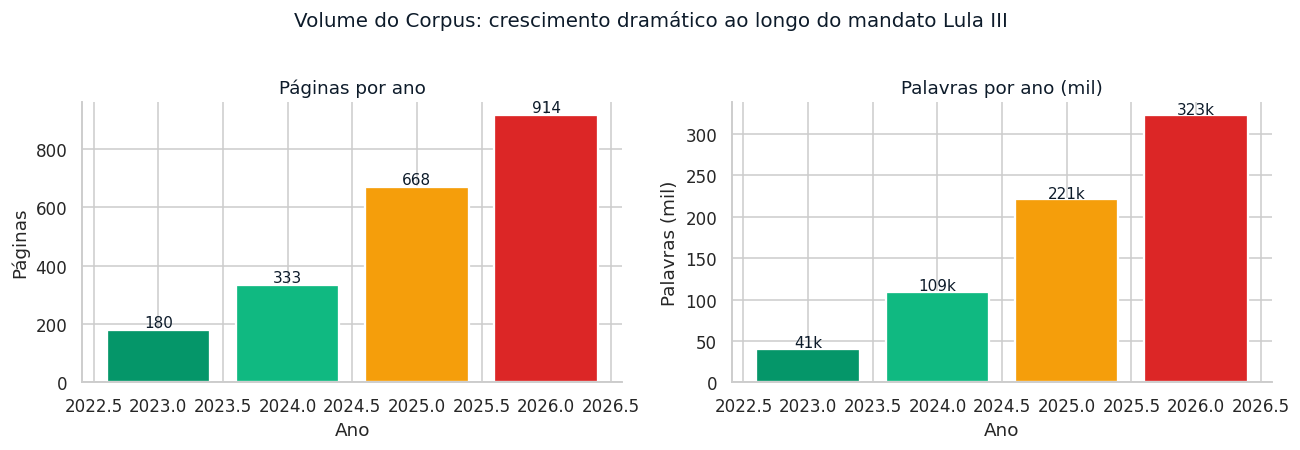

Nota: volume 8× maior em 2026 vs 2023 → análises usam proporções relativas.


In [ ]:
# ── Visualização: volume por ano ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

anos   = [m["year"]   for m in MENSAGENS]
paginas= [m["pages"]  for m in MENSAGENS]
words  = [m["words_real"] for m in MENSAGENS]
cores  = [PALETTE[str(a)] for a in anos]

# Páginas
axes[0].bar(anos, paginas, color=cores, edgecolor="white", linewidth=1.5)
for ax, val in zip(axes[0].patches, paginas):
    axes[0].text(ax.get_x()+ax.get_width()/2, ax.get_height()+10,
                 str(val), ha="center", fontsize=10, color=PALETTE["navy"])
axes[0].set_title("Páginas por ano", fontsize=12, color=PALETTE["navy"])
axes[0].set_xlabel("Ano"); axes[0].set_ylabel("Páginas")

# Palavras
axes[1].bar(anos, [w/1000 for w in words], color=cores, edgecolor="white", linewidth=1.5)
for ax, val in zip(axes[1].patches, words):
    axes[1].text(ax.get_x()+ax.get_width()/2, val/1000+2,
                 f"{val/1000:.0f}k", ha="center", fontsize=10, color=PALETTE["navy"])
axes[1].set_title("Palavras por ano (mil)", fontsize=12, color=PALETTE["navy"])
axes[1].set_xlabel("Ano"); axes[1].set_ylabel("Palavras (mil)")

sns.despine()
plt.suptitle("Volume do Corpus: crescimento dramático ao longo do mandato Lula III",
             fontsize=13, color=PALETTE["navy"], y=1.02)
plt.tight_layout()
plt.show()
print("Nota: volume 8× maior em 2026 vs 2023 → análises usam proporções relativas.")


---
# Fase 1B — Limpeza Estrutural do Corpus

## Por que esta fase existe

Uma auditoria de qualidade dos dados revelou que a extração dos PDFs deixou passar
dois tipos de contaminação que não pertencem ao conteúdo legítimo da agenda governamental:

**1. Cabeçalho/rodapé de página infiltrado.** A string *"Mensagem ao Congresso
Nacional [ano]"* é concatenada ao texto real pela extração; sua remoção é higiene
metodológica (o TF-IDF já a tratava como ruído de fundo, por ser uniforme).

**2. Elementos editoriais não-discursivos.** Sumários (linhas com pontilhados),
títulos de seção em maiúsculas, legendas de gráficos/tabelas, blocos densos de
números (tabelas extraídas como texto), página de catalogação (CDU/ISBN) e listas
de autoridades (ministros). Muitos desses elementos eram títulos-gabarito, triviais
de classificar, que inflavam a métrica; o corpus limpo mede o conteúdo efetivo da agenda.

> **Nota V15.3:** os números desta fase dependem da unidade de análise e são os
> impressos pela célula seguinte. Os valores da V14 (1.851 parágrafos com cabeçalho,
> 146 editoriais, F1 de ~0,814 para ~0,785) referem-se ao corpus de PÁGINA e não valem
> para a execução em parágrafo.


In [ ]:
# ── Limpeza estrutural do corpus ─────────────────────────────────────────────
# Aplica-se ao df_corpus produzido na Fase 1, ANTES da rotulagem (Fases 2 e 4).

import re as _re

def limpar_cabecalho(texto):
    """Remove o cabeçalho/rodapé 'Mensagem ao Congresso Nacional AAAA' que a
    extração concatenou ao texto. Essa string nunca é conteúdo discursivo."""
    texto = _re.sub(r"\s*Mensagem ao Congresso Nacional \d{4}\s*", " ", texto)
    return _re.sub(r"\s+", " ", texto).strip()

def _frac_maiusculas(t):
    letras = [c for c in t if c.isalpha()]
    return sum(1 for c in letras if c.isupper()) / len(letras) if letras else 0

def _densidade_numerica(t):
    tokens = t.split()
    if not tokens:
        return 0
    return sum(1 for x in tokens if _re.match(r"^[\d.,%-]+$", x)) / len(tokens)

def eh_elemento_editorial(texto):
    """Identifica parágrafos que são estrutura editorial, não discurso.
    Retorna (True, motivo) ou (False, '')."""
    if _re.search(r"\.{4,}", texto):
        return True, "sumario_pontilhado"
    if _frac_maiusculas(texto) > 0.5:
        return True, "titulo_maiusculas"
    if _re.match(r"^(Gráfico|Figura|Tabela|Fonte:|Quadro)\s", texto):
        return True, "legenda_figura"
    if _densidade_numerica(texto) > 0.25:
        return True, "tabela_numerica"
    if _re.search(r"Copyright|CDU|CIP|reprodução sem fins", texto):
        return True, "catalogacao"
    if len(_re.findall(r"Ministr[oa] de Estado", texto)) >= 3:
        return True, "lista_autoridades"
    return False, ""

# ── Aplicar limpeza ───────────────────────────────────────────────────────────
n_inicial = len(df_corpus)

# Passo 1: remover cabeçalho de todos os parágrafos
df_corpus["text"] = df_corpus["text"].apply(limpar_cabecalho)

# Passo 2: marcar e remover elementos editoriais
diag = df_corpus["text"].apply(eh_elemento_editorial)
df_corpus["_eh_editorial"] = [d[0] for d in diag]
df_corpus["_motivo_remocao"] = [d[1] for d in diag]

# Relatório de remoção por categoria
print("RELATÓRIO DE LIMPEZA ESTRUTURAL")
print("=" * 55)
print(f"Cabeçalho 'Mensagem ao Congresso Nacional AAAA' removido de todos os parágrafos.")
print(f"\nElementos editoriais removidos por categoria:")
motivos = df_corpus[df_corpus["_eh_editorial"]]["_motivo_remocao"].value_counts()
for motivo, n in motivos.items():
    print(f"  {motivo:22s}: {n:3d}")

# Passo 3: remover editoriais e parágrafos que ficaram curtos demais
df_corpus = df_corpus[~df_corpus["_eh_editorial"]].copy()
df_corpus = df_corpus[df_corpus["text"].str.len() >= 60].reset_index(drop=True)
df_corpus = df_corpus.drop(columns=["_eh_editorial", "_motivo_remocao"])

n_final = len(df_corpus)
print(f"\nParágrafos: {n_inicial} → {n_final} (removidos {n_inicial - n_final})")
print(f"\n✓ Corpus limpo. As Fases 2 e 4 (rotulagem) operam sobre este corpus.")


RELATÓRIO DE LIMPEZA ESTRUTURAL
Cabeçalho 'Mensagem ao Congresso Nacional AAAA' removido de todos os parágrafos.

Elementos editoriais removidos por categoria:
  legenda_figura        : 102
  sumario_pontilhado    :  54
  tabela_numerica       :  40
  titulo_maiusculas     :  36
  catalogacao           :   8
  lista_autoridades     :   3

Parágrafos: 11005 → 10757 (removidos 248)

✓ Corpus limpo. As Fases 2 e 4 (rotulagem) operam sobre este corpus.


---
# Fase 1C (V11) — Auditoria da hifenização de fim de linha

## O que foi encontrado

A auditoria de qualidade da Fase 1B tratou cabeçalho de página e elementos
editoriais. Uma verificação posterior identificou um terceiro artefato de extração,
de natureza distinta: a **hifenização tipográfica** do PDF.

Quando uma palavra é quebrada no fim da linha (`presiden-` / `ciais`), a extração
preserva o hífen. Como `normalize_text` colapsava a quebra de linha em espaço, o
resultado era `presiden- ciais` — **dois fragmentos espúrios** onde deveria haver
uma palavra.

## Por que importa para o TF-IDF

O volume é pequeno em tokens (menos de 0,5% das ocorrências), mas o efeito sobre o
**vocabulário** é desproporcional: fragmentos como `mentos`, `dades`, `verno`,
`políti` são raros por construção, recebem IDF alto e pesam mais por ocorrência
do que sua frequência sugere.

Há ainda um risco de validade: a densidade de hifenização **varia por ano**
(a tipografia de cada PDF é distinta), e o corpus é desbalanceado por ano. Isso
abre um canal em que o classificador poderia captar diagramação como proxy de
tema.

## Decisão metodológica

A correção é aplicada em `normalize_text`, **antes** do colapso de espaços.
Compostos legítimos do português (`sócio-econômico`, `pós-graduação`) preservam o
hífen; apenas a quebra de linha é removida.

A flag `CORRIGIR_HIFENIZACAO` permite executar o pipeline nas duas condições, de
modo que o efeito sobre o F1-macro seja **medido e reportado**, não presumido.

In [ ]:
# ── Fase 1C · V11 — Auditoria da hifenização ─────────────────────────────────
# Roda APÓS a Fase 1B. Reporta o que a correção removeu e verifica resíduo.

import re as _re

print("AUDITORIA DE HIFENIZAÇÃO (V11)")
print("=" * 55)
print(f"Correção ativa           : {CORRIGIR_HIFENIZACAO}")
print(f"Remontagens na extração  : {AUDITORIA_HIFEN['ocorrencias']:,}")

if AUDITORIA_HIFEN["amostras"]:
    print("\nAmostra do que foi remontado (inspecione por falso positivo):")
    for s in AUDITORIA_HIFEN["amostras"][:20]:
        print("   ", s)

# Resíduo: padrão 'palavra- palavra' que tenha sobrevivido ao pipeline
_res = _re.compile(r"[a-zà-ÿ]+-\s+[a-zà-ÿ]+")
_n_res = sum(len(_res.findall(t)) for t in df_corpus["text"])
_docs_res = sum(1 for t in df_corpus["text"] if _res.search(t))
print(f"\nResíduo no corpus limpo  : {_n_res:,} ocorrências em {_docs_res} documentos")
if _n_res:
    print("  exemplos:", [m for t in df_corpus['text'][:200] for m in _res.findall(t)][:10])

# Densidade por ano — evidência do canal tipografia → ano
df_corpus["_n_hifen_residual"] = df_corpus["text"].apply(lambda t: len(_res.findall(t)))
print("\nResíduo por ano (média por parágrafo):")
print(df_corpus.groupby("year")["_n_hifen_residual"].mean().round(3).to_string())
df_corpus.drop(columns=["_n_hifen_residual"], inplace=True)

# Tamanho do vocabulário — comparável entre execuções com/sem correção
_RE_PAL = _re.compile(r"[^\W\d_]+", _re.UNICODE)
_vocab = set()
for t in df_corpus["text"]:
    _vocab.update(w.lower() for w in _RE_PAL.findall(t))
print(f"\nVocabulário (tipos únicos): {len(_vocab):,}")
print("  → anote este número nas duas execuções; a diferença é o artefato removido.")

AUDITORIA_V11 = {
    "correcao_ativa": bool(CORRIGIR_HIFENIZACAO),
    "remontagens": AUDITORIA_HIFEN["ocorrencias"],
    "residuo_ocorrencias": int(_n_res),
    "residuo_documentos": int(_docs_res),
    "vocabulario_tipos": len(_vocab),
    "n_paragrafos": int(len(df_corpus)),
}
print("\n✓ Auditoria registrada em AUDITORIA_V11.")

AUDITORIA DE HIFENIZAÇÃO (V11)
Correção ativa           : True
Remontagens na extração  : 2,679

Amostra do que foi remontado (inspecione por falso positivo):
    presiden-ciais -> fusao
    indepen-dência -> fusao
    fun-damentalmente -> fusao
    insti-tuições -> fusao
    qua-tro -> fusao
    auto-ritária -> fusao
    res-pondendo -> fusao
    Orça-mento -> fusao
    repro-duz -> fusao
    incan-sável -> fusao
    gra-vidade -> fusao
    fo-ram -> fusao
    aban-donadas -> fusao
    despropo-sitado -> fusao
    pro-movida -> fusao
    des-tinação -> fusao
    bioeco-nomia -> fusao
    iní-cio -> fusao
    recupe-ração -> fusao
    Encontra-mos -> fusao

Resíduo no corpus limpo  : 3 ocorrências em 3 documentos
  exemplos: []

Resíduo por ano (média por parágrafo):
year
2023    0.001
2024    0.000
2025    0.000
2026    0.000

Vocabulário (tipos únicos): 21,358
  → anote este número nas duas execuções; a diferença é o artefato removido.

✓ Auditoria registrada em AUDITORIA_V11.


---
# Fase 2 — Léxico V1: Rotulagem Fraca (Etapa 1 de AM)

## O que é rotulagem fraca?

Em NLP supervisionado, precisamos de rótulos (classes) para cada exemplo de treinamento.
Rotular manualmente todo o corpus seria inviável. A solução é a **rotulagem fraca
por léxico**: definimos listas de palavras-âncora por tema e atribuímos automaticamente
um rótulo a cada parágrafo pela contagem de termos encontrados.

**Regra de decisão:**
1. Para cada classe, conta quantas palavras do léxico aparecem no parágrafo
2. A classe com maior contagem ganha o rótulo
3. Em caso de **empate** → rótulo `outros_institucional` (residual)
4. Se **nenhuma palavra** do léxico aparece → também residual

Esta é exatamente a função implementada no **notebook AED da Etapa 1 de AM**,
reproduzida aqui para garantir consistência entre os três projetos de mestrado.

## Léxico V1 — 7 classes temáticas + 1 residual

O léxico V1 foi desenvolvido para o contexto institucional brasileiro das
Mensagens Presidenciais. As 7 classes temáticas refletem as grandes áreas
de política pública do governo federal.


In [ ]:
# ── LÉXICO V1 — Reprodução fiel do AED (Etapa 1 de AM) ───────────────────────
# Fonte: Etapa1_RafolsFerdinand_AED_CORRIGIDO.ipynb
# Qualquer alteração aqui deve ser documentada e refletida nos outros notebooks.

LEXICON_V1 = {
    "economia_desenvolvimento": {
        "economia", "econômico", "econômica", "pib", "inflação", "fiscal", "tributação",
        "tributo", "imposto", "tributária", "investimento", "investimentos", "crescimento",
        "indústria", "industrial", "inovação", "produtividade", "competitividade", "mercado",
        "emprego", "empregos", "renda", "salário", "trabalhador", "trabalhadores",
        "déficit", "dívida", "monetária", "câmbio", "exportações"
    },
    "programas_sociais": {
        "bolsa", "família", "bolsa-família", "miséria", "pobreza", "fome", "transferência",
        "assistência", "assistencial", "vulnerabilidade", "vulneráveis", "social",
        "inclusão", "cras", "creas", "auxílio", "benefício", "benefícios", "pé-de-meia",
        "previdência", "previdenciária", "aposentadoria"
    },
    "saude": {
        "saúde", "sus", "hospital", "hospitais", "médico", "médicos", "atenção",
        "básica", "ubs", "vacina", "vacinação", "vacinas", "farmácia", "popular",
        "medicamento", "medicamentos", "epidemia", "pandemia", "covid", "doença", "doenças",
        "tratamento", "paciente", "pacientes"
    },
    "educacao_ciencia": {
        "educação", "educacional", "escola", "escolas", "ensino", "fundamental", "médio",
        "universidade", "universidades", "fundeb", "prouni", "fies", "professor", "professores",
        "aluno", "alunos", "estudante", "estudantes", "ciência", "científico", "pesquisa",
        "tecnologia", "tecnológico", "cnpq", "capes", "ifet", "ifets"
    },
    "reforma_agraria_agropecuaria": {
        "agricultura", "agrícola", "agronegócio", "agrário", "agrária", "incra", "reforma",
        "assentamento", "assentamentos", "assentado", "assentados", "rural", "pronaf",
        "agricultor", "agricultores", "produtor", "produção", "pecuária", "pecuarista",
        "fazenda", "campo", "embrapa"
    },
    "politica_externa": {
        "exterior", "externa", "internacional", "internacionais", "mercosul", "brics",
        "onu", "diplomacia", "diplomático", "comércio", "integração", "regional", "sul-sul",
        "acordo", "tratado", "aliança", "embaixada", "embaixador", "itamaraty"
    },
    # NOTA: esta classe funde dois domínios distintos (infraestrutura física e
    # política ambiental). A fusão foi herdada do léxico original do AED.
    # A Fase 3 documenta por que isso é problemático e a Fase 4 apresenta a solução.
    "infraestrutura_meio_ambiente": {
        "infraestrutura", "pac", "energia", "energético", "elétrica", "petróleo", "gás",
        "renovável", "solar", "eólica", "transição", "ambiental", "ambiente", "amazônia",
        "desmatamento", "clima", "climática", "carbono", "saneamento", "transporte",
        "transportes", "rodovia", "rodovias", "ferrovia", "porto", "portos", "aeroporto"
    },
}

RESIDUAL_V1 = "outros_institucional"

total_termos_v1 = sum(len(v) for v in LEXICON_V1.values())
print(f"Léxico V1: {len(LEXICON_V1)} classes temáticas + 1 residual = 8 classes no total")
print(f"Total de termos-âncora: {total_termos_v1}")
print()
for cls, terms in LEXICON_V1.items():
    print(f"  {cls:<35}: {len(terms):2d} termos")


Léxico V1: 7 classes temáticas + 1 residual = 8 classes no total
Total de termos-âncora: 171

  economia_desenvolvimento           : 30 termos
  programas_sociais                  : 22 termos
  saude                              : 24 termos
  educacao_ciencia                   : 27 termos
  reforma_agraria_agropecuaria       : 22 termos
  politica_externa                   : 19 termos
  infraestrutura_meio_ambiente       : 27 termos


In [ ]:
# ── Função de rotulagem (idêntica à do AED) ──────────────────────────────────

def label_by_lexicon(text: str, lexicon: dict, residual: str) -> str:
    """
    Rotula um parágrafo por contagem de termos-âncora.

    Parâmetros
    ----------
    text     : texto do parágrafo
    lexicon  : dicionário {classe: set(termos)}
    residual : rótulo atribuído em caso de empate ou zero hits

    Retorno
    -------
    Rótulo da classe vencedora, ou `residual` se empate/zero.

    Decisão de design (herdada do AED):
    - Tokenização por regex \b[a-záàâãéêíóôõúçü]+\b (apenas letras, sem pontuação)
    - Intersecção de conjuntos → eficiente para vocabulários grandes
    - Empate deliberadamente enviado para residual: melhor não rotular
      do que rotular errado em contexto de aprendizado supervisionado
    """
    tokens    = set(re.findall(r"\b[a-záàâãéêíóôõúçü]+\b", text.lower()))
    scores    = {cls: len(tokens & terms) for cls, terms in lexicon.items()}
    max_score = max(scores.values())

    if max_score == 0:
        return residual                          # nenhuma âncora encontrada

    top = [cls for cls, s in scores.items() if s == max_score]
    if len(top) > 1:
        return residual                          # empate → não decidir

    return top[0]


print("✓ Função de rotulagem definida.")
print("  Algoritmo: tokenização regex → intersecção de conjuntos → máximo único")


✓ Função de rotulagem definida.
  Algoritmo: tokenização regex → intersecção de conjuntos → máximo único


In [ ]:
# ── Aplicar léxico V1 ao corpus ──────────────────────────────────────────────
df_corpus["label_v1"] = df_corpus["text"].apply(
    lambda t: label_by_lexicon(t, LEXICON_V1, RESIDUAL_V1)
)

counts_v1   = df_corpus["label_v1"].value_counts()
residual_n  = counts_v1.get(RESIDUAL_V1, 0)
residual_pct= residual_n / len(df_corpus) * 100

print("Distribuição de rótulos — Léxico V1:")
print(counts_v1.to_string())
print(f"\nResidual: {residual_n} parágrafos ({residual_pct:.1f}%)")
print(f"Rotulados: {len(df_corpus)-residual_n} parágrafos ({100-residual_pct:.1f}%)")


Distribuição de rótulos — Léxico V1:
label_v1
outros_institucional            4609
economia_desenvolvimento        1323
infraestrutura_meio_ambiente    1290
educacao_ciencia                 964
programas_sociais                895
politica_externa                 659
saude                            589
reforma_agraria_agropecuaria     428

Residual: 4609 parágrafos (42.8%)
Rotulados: 6148 parágrafos (57.2%)


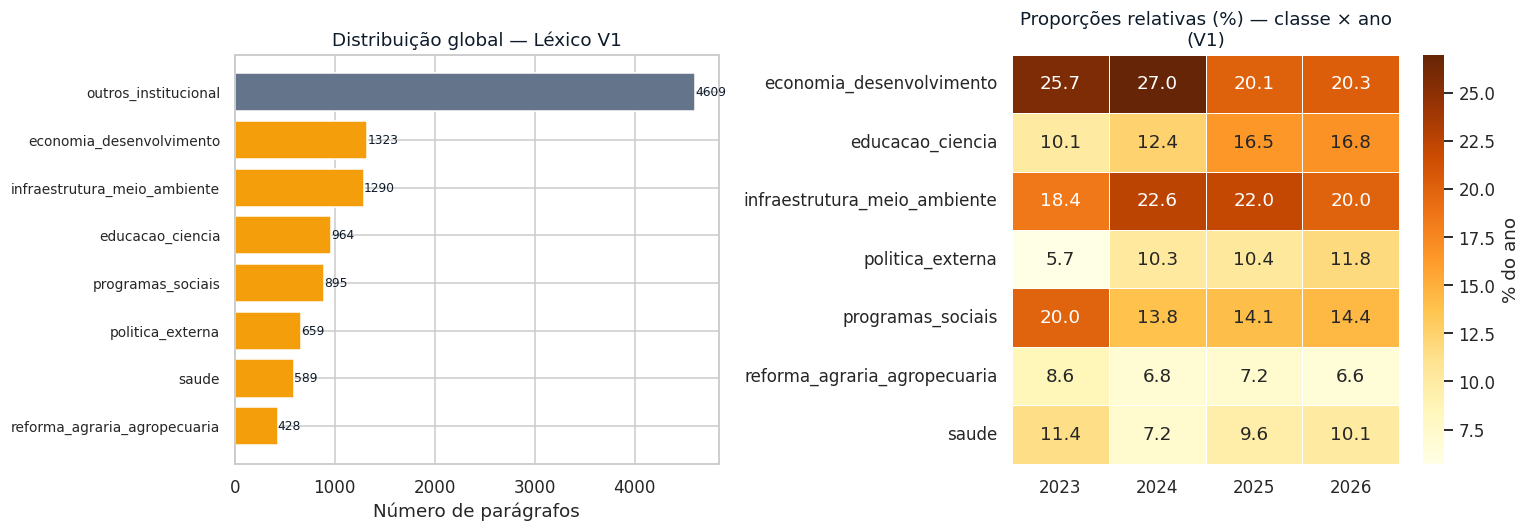

In [ ]:
# ── Visualização: distribuição V1 ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras horizontais — distribuição global
ordered_v1 = counts_v1.sort_values(ascending=True)
cores_bar  = [PALETTE["muted"] if idx == RESIDUAL_V1 else PALETTE["amber"]
              for idx in ordered_v1.index]

axes[0].barh(range(len(ordered_v1)), ordered_v1.values,
             color=cores_bar, edgecolor="white", linewidth=1)
axes[0].set_yticks(range(len(ordered_v1)))
axes[0].set_yticklabels(ordered_v1.index, fontsize=9)
axes[0].set_xlabel("Número de parágrafos")
axes[0].set_title("Distribuição global — Léxico V1", color=PALETTE["navy"])
for i, v in enumerate(ordered_v1.values):
    axes[0].text(v + 3, i, str(v), va="center", fontsize=8, color=PALETTE["navy"])

# Heatmap classe × ano
df_nores_v1 = df_corpus[df_corpus["label_v1"] != RESIDUAL_V1]
crosstab_v1 = pd.crosstab(df_nores_v1["label_v1"], df_nores_v1["year"])
crosstab_pct_v1 = crosstab_v1.div(crosstab_v1.sum(axis=0), axis=1) * 100

sns.heatmap(crosstab_pct_v1, annot=True, fmt=".1f", cmap="YlOrBr",
            linewidths=0.5, cbar_kws={"label": "% do ano"}, ax=axes[1])
axes[1].set_title("Proporções relativas (%) — classe × ano\n(V1)", color=PALETTE["navy"])
axes[1].set_xlabel(""); axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


---
# Fase 3 — Diagnóstico Crítico do Léxico V1

Antes de treinar qualquer classificador, precisamos validar a qualidade dos rótulos.
Rótulos ruins produzem classificadores ruins — independentemente do algoritmo usado.

Realizamos três diagnósticos:

1. **Termos ambíguos** — palavras que poderiam pertencer a múltiplas classes
2. **Coerência interna da classe `infraestrutura_meio_ambiente`** — a fusão faz sentido?
3. **Causa do resíduo de 23%** — por que tantos parágrafos não são rotulados?


In [ ]:
# ── Diagnóstico 1: termos ambíguos ───────────────────────────────────────────
print("TERMOS POTENCIALMENTE AMBÍGUOS NO LÉXICO V1")
print("=" * 55)

ambiguos = {
    "atenção":       ("saude", "educacao_ciencia"),
    "básica":        ("saude ← atenção básica", "educacao_ciencia ← ensino básico"),
    "social":        ("programas_sociais", "economia_desenvolvimento"),
    "transferência": ("programas_sociais ← renda", "economia_desenvolvimento ← fiscal"),
    "integração":    ("politica_externa ← regional", "infraestrutura_meio_ambiente ← logística"),
    "regional":      ("politica_externa", "infraestrutura_meio_ambiente"),
    "acordo":        ("politica_externa ← diplomático", "economia_desenvolvimento ← comercial"),
    "reforma":       ("reforma_agraria_agropecuaria", "economia_desenvolvimento ← fiscal"),
    "produção":      ("reforma_agraria_agropecuaria ← rural", "economia_desenvolvimento ← industrial"),
    "comércio":      ("politica_externa ← exterior", "economia_desenvolvimento ← interno"),
    "popular":       ("saude ← farmácia popular", "programas_sociais ← movimento popular"),
    "ambiente":      ("infraestrutura_meio_ambiente", "programas_sociais ← ambiente social"),
    "transição":     ("infraestrutura_meio_ambiente ← energética", "outro ← governo"),
}

for termo, (c1, c2) in ambiguos.items():
    print(f"  '{termo}': [{c1}]  vs  [{c2}]")

print(f"\nTotal de termos com ambiguidade semântica identificada: {len(ambiguos)}")
print("→ Ambiguidade causa empates → parágrafo vai para residual mesmo tendo conteúdo claro")


TERMOS POTENCIALMENTE AMBÍGUOS NO LÉXICO V1
  'atenção': [saude]  vs  [educacao_ciencia]
  'básica': [saude ← atenção básica]  vs  [educacao_ciencia ← ensino básico]
  'social': [programas_sociais]  vs  [economia_desenvolvimento]
  'transferência': [programas_sociais ← renda]  vs  [economia_desenvolvimento ← fiscal]
  'integração': [politica_externa ← regional]  vs  [infraestrutura_meio_ambiente ← logística]
  'regional': [politica_externa]  vs  [infraestrutura_meio_ambiente]
  'acordo': [politica_externa ← diplomático]  vs  [economia_desenvolvimento ← comercial]
  'reforma': [reforma_agraria_agropecuaria]  vs  [economia_desenvolvimento ← fiscal]
  'produção': [reforma_agraria_agropecuaria ← rural]  vs  [economia_desenvolvimento ← industrial]
  'comércio': [politica_externa ← exterior]  vs  [economia_desenvolvimento ← interno]
  'popular': [saude ← farmácia popular]  vs  [programas_sociais ← movimento popular]
  'ambiente': [infraestrutura_meio_ambiente]  vs  [programas_sociais ← ambie

In [ ]:
# V15.3 · conclusão calculada dos números impressos (antes era texto fixo da V14).
# ── Diagnóstico 2: infraestrutura_meio_ambiente — duas classes numa? ─────────
print("DIAGNÓSTICO: infraestrutura_meio_ambiente")
print("=" * 55)

# Subconjuntos do léxico de infraestrutura_meio_ambiente
INFRA_TERMS = {"infraestrutura","pac","saneamento","transporte","transportes",
               "rodovia","rodovias","ferrovia","porto","portos","aeroporto"}
AMB_TERMS   = {"ambiental","ambiente","amazônia","desmatamento","clima","climática",
               "carbono","renovável","solar","eólica","transição"}
# "energia","energético","petróleo","gás","elétrica" são compartilhados → não discriminam

mask_ia = df_corpus["label_v1"] == "infraestrutura_meio_ambiente"
sub_ia  = df_corpus[mask_ia].copy()

def score_sub(text, terms):
    tokens = set(re.findall(r"\b[a-záàâãéêíóôõúçü]+\b", text.lower()))
    return len(tokens & terms)

sub_ia["s_infra"] = sub_ia["text"].apply(lambda t: score_sub(t, INFRA_TERMS))
sub_ia["s_amb"]   = sub_ia["text"].apply(lambda t: score_sub(t, AMB_TERMS))

def subgrupo(row):
    if   row["s_infra"] > row["s_amb"] > 0: return "infra_pura"
    elif row["s_amb"]   > row["s_infra"]> 0: return "amb_pura"
    elif row["s_infra"] > 0 and row["s_amb"] == 0: return "infra_pura"
    elif row["s_amb"]   > 0 and row["s_infra"]== 0: return "amb_pura"
    else: return "energia_ou_misto"

sub_ia["subgrupo"] = sub_ia.apply(subgrupo, axis=1)
sg_counts = sub_ia["subgrupo"].value_counts()

print(f"Total parágrafos na classe 'infraestrutura_meio_ambiente': {len(sub_ia)}")
print(f"\nComposição interna:")
for sg, n in sg_counts.items():
    print(f"  {sg:<25}: {n:3d} ({n/len(sub_ia)*100:.0f}%)")
genuino_misto = ((sub_ia["s_infra"]>0) & (sub_ia["s_amb"]>0)).sum()
print(f"\nGenuinamente mistos (ambos sinais > 0): {genuino_misto} ({genuino_misto/len(sub_ia)*100:.0f}%)")
_pa = 100 * sg_counts.get("amb_pura", 0) / len(sub_ia)
_pi = 100 * sg_counts.get("infra_pura", 0) / len(sub_ia)
print(f"\n→ CONCLUSÃO (derivada): {_pa:.0f}% puramente ambiente, {_pi:.0f}% puramente infraestrutura.")
print("  A fusão não reflete coerência semântica — é uma limitação do léxico V1.")


DIAGNÓSTICO: infraestrutura_meio_ambiente
Total parágrafos na classe 'infraestrutura_meio_ambiente': 1290

Composição interna:
  amb_pura                 : 637 (49%)
  infra_pura               : 471 (37%)
  energia_ou_misto         : 182 (14%)

Genuinamente mistos (ambos sinais > 0): 159 (12%)

→ CONCLUSÃO (derivada): 49% puramente ambiente, 37% puramente infraestrutura.
  A fusão não reflete coerência semântica — é uma limitação do léxico V1.


In [ ]:
# V15.3 · conclusão calculada dos números impressos (antes era texto fixo da V14).
# ── Diagnóstico 3: por que tanto vai para residual? ────────────────────────────
_res_pct = 100 * (df_corpus["label_v1"] == RESIDUAL_V1).mean()
print(f"DIAGNÓSTICO: causa do resíduo de {_res_pct:.1f}%")
print("=" * 55)

def motivo_residual(text, lexicon, residual):
    tokens  = set(re.findall(r"\b[a-záàâãéêíóôõúçü]+\b", text.lower()))
    scores  = {cls: len(tokens & terms) for cls, terms in lexicon.items()}
    max_s   = max(scores.values())
    if max_s == 0:
        return "zero_hits"
    top = [c for c, s in scores.items() if s == max_s]
    return "empate" if len(top) > 1 else "rotulado"

res_mask = df_corpus["label_v1"] == RESIDUAL_V1
res_sub  = df_corpus[res_mask].copy()
res_sub["motivo"] = res_sub["text"].apply(
    lambda t: motivo_residual(t, LEXICON_V1, RESIDUAL_V1)
)
motivos = res_sub["motivo"].value_counts()
print(f"Total residual: {len(res_sub)} parágrafos")
print(f"\nCausa do resíduo:")
for m, n in motivos.items():
    print(f"  {m:<15}: {n:3d} ({n/len(res_sub)*100:.0f}%)")

# Top tokens nos parágrafos de zero_hits — revelam tema ausente do léxico
print("\nTop 25 tokens nos parágrafos sem nenhuma âncora (zero_hits):")
zero_texts = res_sub[res_sub["motivo"]=="zero_hits"]["text"].tolist()
stopwords  = {"de","da","do","das","dos","e","a","o","as","os","em","para","com",
              "por","que","se","ao","na","no","nas","nos","um","uma","é","são",
              "ou","mais","como","também","esta","este","sua","seu","já","não",
              "pelo","pela","entre","sobre","desde","após","até","foram","será"}
tok_count = Counter()
for t in zero_texts:
    toks = re.findall(r"\b[a-záàâãéêíóôõúçü]{4,}\b", t.lower())
    tok_count.update(tk for tk in toks if tk not in stopwords)
for tok, cnt in tok_count.most_common(25):
    print(f"  {tok}: {cnt}")
_pe = 100 * motivos.get("empate", 0) / len(res_sub)
_pz = 100 * motivos.get("zero_hits", 0) / len(res_sub)
print(f"\n→ CONCLUSÃO (derivada): {_pe:.0f}% do resíduo vem de EMPATE e {_pz:.0f}% de AUSÊNCIA de âncora.")
print("  Os tokens mais frequentes nos zero_hits indicam o tema ausente do V1 (ver lista acima);")
print("  a Fase 4 responde a isso com a classe governanca_institucional.")


DIAGNÓSTICO: causa do resíduo de 42.8%
Total residual: 4609 parágrafos

Causa do resíduo:
  zero_hits      : 2594 (56%)
  empate         : 2015 (44%)

Top 25 tokens nos parágrafos sem nenhuma âncora (zero_hits):
  nacional: 598
  governo: 564
  federal: 537
  ações: 392
  brasil: 348
  programa: 326
  políticas: 294
  além: 290
  milhões: 287
  país: 249
  segurança: 244
  meio: 230
  pública: 218
  públicas: 211
  estado: 207
  sistema: 203
  política: 202
  direitos: 200
  gestão: 200
  pessoas: 195
  recursos: 185
  mulheres: 183
  estados: 183
  municípios: 180
  indígenas: 170

→ CONCLUSÃO (derivada): 44% do resíduo vem de EMPATE e 56% de AUSÊNCIA de âncora.
  Os tokens mais frequentes nos zero_hits indicam o tema ausente do V1 (ver lista acima);
  a Fase 4 responde a isso com a classe governanca_institucional.


---
# Fase 4 — Léxico V3: Refinamento Motivado pelo Diagnóstico

O diagnóstico da Fase 3 identificou **três problemas estruturais** no léxico V1:

| Problema | Impacto | Solução no V3 |
|---|---|---|
| `infraestrutura_meio_ambiente` são domínios distintos | Classe internamente incoerente; classificador recebe sinal ambíguo | **Separar** em `infraestrutura_logistica` e `meio_ambiente_energia` |
| Parte substancial do resíduo é empate (proporção impressa na Fase 3), e não ausência de conteúdo | Parágrafos temáticos desperdiçados como residual | **Adicionar** `governanca_institucional` para absorver o tema ausente |
| Termos genéricos na governança (lei, decreto, direito) | Captura indevida de parágrafos de outras classes | Léxico de governança com **termos específicos** do campo administrativo |

> **Nota de transparência:** o léxico V3 **não altera** as 6 classes originais que funcionavam bem
> (`economia_desenvolvimento`, `programas_sociais`, `saude`, `educacao_ciencia`,
> `reforma_agraria_agropecuaria`, `politica_externa`). Apenas refina e expande o restante.


In [ ]:
# ── LÉXICO V3 — Refinado (usado como base deste notebook) ────────────────────
#
# Mudanças em relação ao V1:
# [1] "infraestrutura_meio_ambiente" SEPARADA em duas classes distintas
# [2] "governanca_institucional" ADICIONADA (nova — absorve tema ausente do V1)
# [3] Termos de energia distribuídos para "meio_ambiente_energia" (mais coerente)
# [4] Termos de governança: apenas específicos do campo administrativo-jurídico
#     (sem "lei", "decreto", "direito", "proteção", "segurança" — muito genéricos)

LEXICON_V3 = {
    # ── 6 classes originais — mantidas sem alteração ──────────────────────────
    "economia_desenvolvimento": {
        "economia", "econômico", "econômica", "pib", "inflação", "fiscal", "tributação",
        "tributo", "imposto", "tributária", "investimento", "investimentos", "crescimento",
        "indústria", "industrial", "inovação", "produtividade", "competitividade", "mercado",
        "emprego", "empregos", "renda", "salário", "trabalhador", "trabalhadores",
        "déficit", "dívida", "monetária", "câmbio", "exportações"
    },
    "programas_sociais": {
        "bolsa", "família", "bolsa-família", "miséria", "pobreza", "fome", "transferência",
        "assistência", "assistencial", "vulnerabilidade", "vulneráveis", "social",
        "inclusão", "cras", "creas", "auxílio", "benefício", "benefícios", "pé-de-meia",
        "previdência", "previdenciária", "aposentadoria"
    },
    "saude": {
        "saúde", "sus", "hospital", "hospitais", "médico", "médicos", "atenção",
        "básica", "ubs", "vacina", "vacinação", "vacinas", "farmácia", "popular",
        "medicamento", "medicamentos", "epidemia", "pandemia", "covid", "doença", "doenças",
        "tratamento", "paciente", "pacientes"
    },
    "educacao_ciencia": {
        "educação", "educacional", "escola", "escolas", "ensino", "fundamental", "médio",
        "universidade", "universidades", "fundeb", "prouni", "fies", "professor", "professores",
        "aluno", "alunos", "estudante", "estudantes", "ciência", "científico", "pesquisa",
        "tecnologia", "tecnológico", "cnpq", "capes", "ifet", "ifets"
    },
    "reforma_agraria_agropecuaria": {
        "agricultura", "agrícola", "agronegócio", "agrário", "agrária", "incra", "reforma",
        "assentamento", "assentamentos", "assentado", "assentados", "rural", "pronaf",
        "agricultor", "agricultores", "produtor", "produção", "pecuária", "pecuarista",
        "fazenda", "campo", "embrapa"
    },
    "politica_externa": {
        "exterior", "externa", "internacional", "internacionais", "mercosul", "brics",
        "onu", "diplomacia", "diplomático", "comércio", "integração", "regional", "sul-sul",
        "acordo", "tratado", "aliança", "embaixada", "embaixador", "itamaraty"
    },
    # ── [1] SEPARAÇÃO: infraestrutura física ─────────────────────────────────
    # Foco: obras, modais de transporte, saneamento, concessões de infraestrutura
    "infraestrutura_logistica": {
        "infraestrutura", "pac", "saneamento", "transporte", "transportes",
        "rodovia", "rodovias", "ferrovia", "ferroviário", "porto", "portos",
        "aeroporto", "aeroportos", "mobilidade", "logística", "hidrovia",
        "viaduto", "concessão", "concessões", "ponte", "pontes", "metrô"
    },
    # ── [1] SEPARAÇÃO: meio ambiente e política energética ───────────────────
    # Foco: clima, florestas, energia (inclui petróleo como política energética)
    "meio_ambiente_energia": {
        "ambiental", "ambiente", "amazônia", "desmatamento", "clima", "climática",
        "carbono", "renovável", "solar", "eólica", "transição", "energética",
        "biodiversidade", "floresta", "florestas", "sustentável", "sustentabilidade",
        "emissões", "petróleo", "pré-sal", "gás", "energia", "elétrica", "energético",
        "hidreletric", "resíduo", "resíduos", "reciclagem", "bioma", "pantanal"
    },
    # ── [2] NOVA: governança e institucionalidade ────────────────────────────
    # Foco: mecanismos de controle, participação, direitos específicos de grupos
    # [4] Apenas termos específicos — "lei","decreto","direito" excluídos (genéricos)
    "governanca_institucional": {
        "transparência", "fiscalização", "auditoria", "compliance", "controladoria",
        "constitucional", "democracia", "democrático", "democratização",
        "indígenas", "quilombola", "quilombolas", "lgbtqia", "feminicídio",
        "ministério", "autarquia", "judiciário", "legislativo", "federativo",
        "ouvidoria", "cgu", "tcu", "mpf",
        "desinformação", "corrupção", "anticorrupção", "lavagem",
        "gestão pública", "servidor", "servidores",
        "concurso", "eficiência", "governança"
    },
}

RESIDUAL_V3 = "outros_institucional"

total_termos_v3 = sum(len(v) for v in LEXICON_V3.values())
print(f"Léxico V3: {len(LEXICON_V3)} classes temáticas + 1 residual = {len(LEXICON_V3)+1} classes")
print(f"Total de termos-âncora: {total_termos_v3} (V1 tinha {sum(len(v) for v in LEXICON_V1.values())})")
print()
for cls, terms in LEXICON_V3.items():
    tag = "  [nova]" if cls in ("infraestrutura_logistica","meio_ambiente_energia","governanca_institucional") else ""
    print(f"  {cls:<40}: {len(terms):2d} termos{tag}")


Léxico V3: 9 classes temáticas + 1 residual = 10 classes
Total de termos-âncora: 229 (V1 tinha 171)

  economia_desenvolvimento                : 30 termos
  programas_sociais                       : 22 termos
  saude                                   : 24 termos
  educacao_ciencia                        : 27 termos
  reforma_agraria_agropecuaria            : 22 termos
  politica_externa                        : 19 termos
  infraestrutura_logistica                : 22 termos  [nova]
  meio_ambiente_energia                   : 30 termos  [nova]
  governanca_institucional                : 33 termos  [nova]


In [ ]:
# ── Aplicar V3 e comparar com V1 ─────────────────────────────────────────────
df_corpus["label_v3"] = df_corpus["text"].apply(
    lambda t: label_by_lexicon(t, LEXICON_V3, RESIDUAL_V3)
)

counts_v3    = df_corpus["label_v3"].value_counts()
res_v1 = (df_corpus["label_v1"] == RESIDUAL_V1).sum()
res_v3 = (df_corpus["label_v3"] == RESIDUAL_V3).sum()

print("COMPARAÇÃO V1 → V3")
print("=" * 55)
print(f"Parágrafos totais       : {len(df_corpus):,}")
print(f"Residual V1             : {res_v1} ({res_v1/len(df_corpus)*100:.1f}%)")
print(f"Residual V3             : {res_v3} ({res_v3/len(df_corpus)*100:.1f}%)")
print(f"Recuperados pelo V3     : {res_v1 - res_v3}")

# Desbalanceamento
df_nores_v3  = df_corpus[df_corpus["label_v3"] != RESIDUAL_V3]
counts_nores = df_nores_v3["label_v3"].value_counts()
razao_v3     = counts_nores.max() / counts_nores.min()
df_nores_v1  = df_corpus[df_corpus["label_v1"] != RESIDUAL_V1]
counts_nores_v1 = df_nores_v1["label_v1"].value_counts()
razao_v1     = counts_nores_v1.max() / counts_nores_v1.min()

print(f"\nDesbalanceamento V1     : {razao_v1:.1f}× (maior/menor classe)")
print(f"Desbalanceamento V3     : {razao_v3:.1f}× (maior/menor classe)")
print(f"\nDistribuição V3 (sem residual):")
print(counts_nores.to_string())


COMPARAÇÃO V1 → V3
Parágrafos totais       : 10,757
Residual V1             : 4609 (42.8%)
Residual V3             : 4387 (40.8%)
Recuperados pelo V3     : 222

Desbalanceamento V1     : 3.1× (maior/menor classe)
Desbalanceamento V3     : 3.2× (maior/menor classe)

Distribuição V3 (sem residual):
label_v3
economia_desenvolvimento        1117
meio_ambiente_energia           1016
educacao_ciencia                 853
governanca_institucional         720
programas_sociais                720
infraestrutura_logistica         552
saude                            526
politica_externa                 522
reforma_agraria_agropecuaria     344


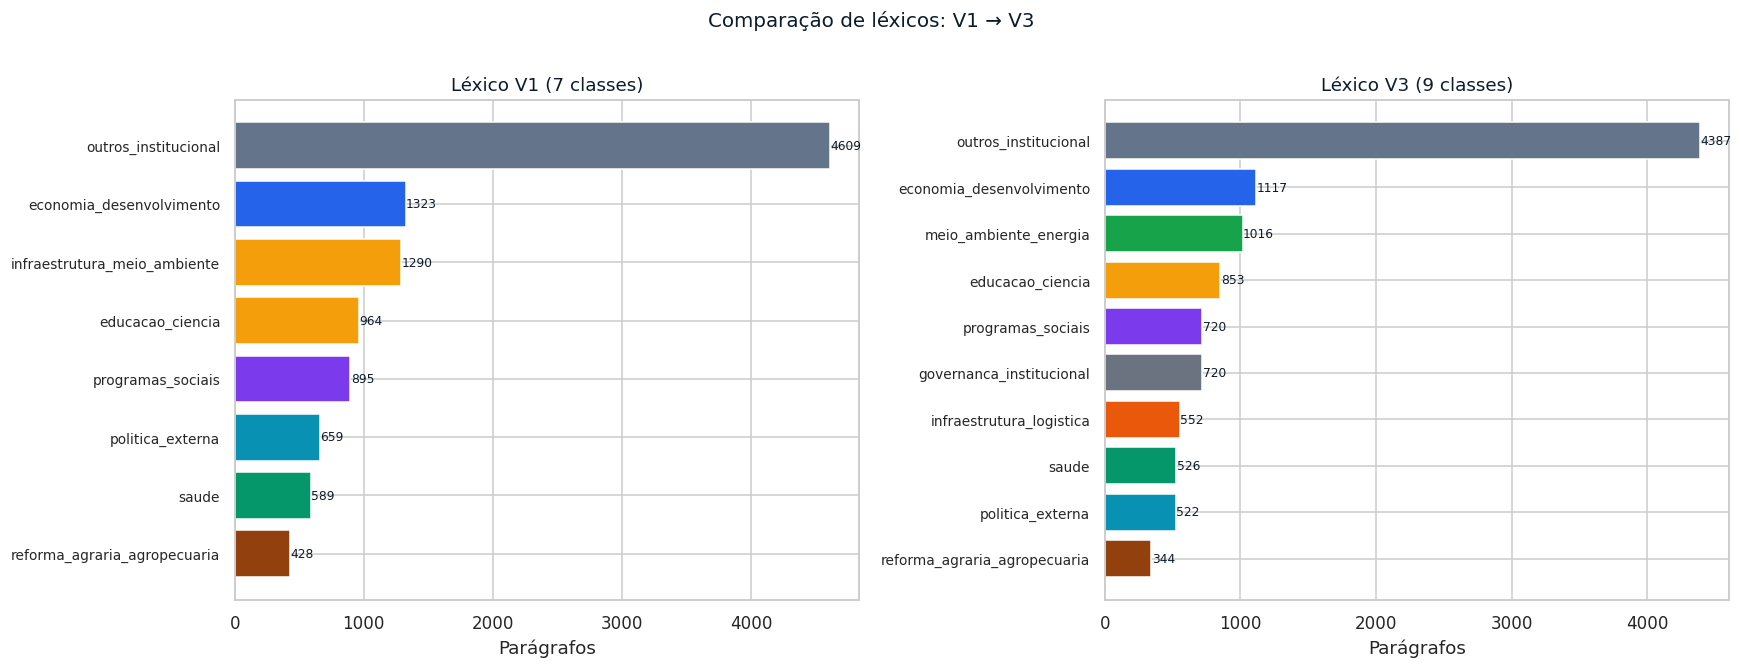

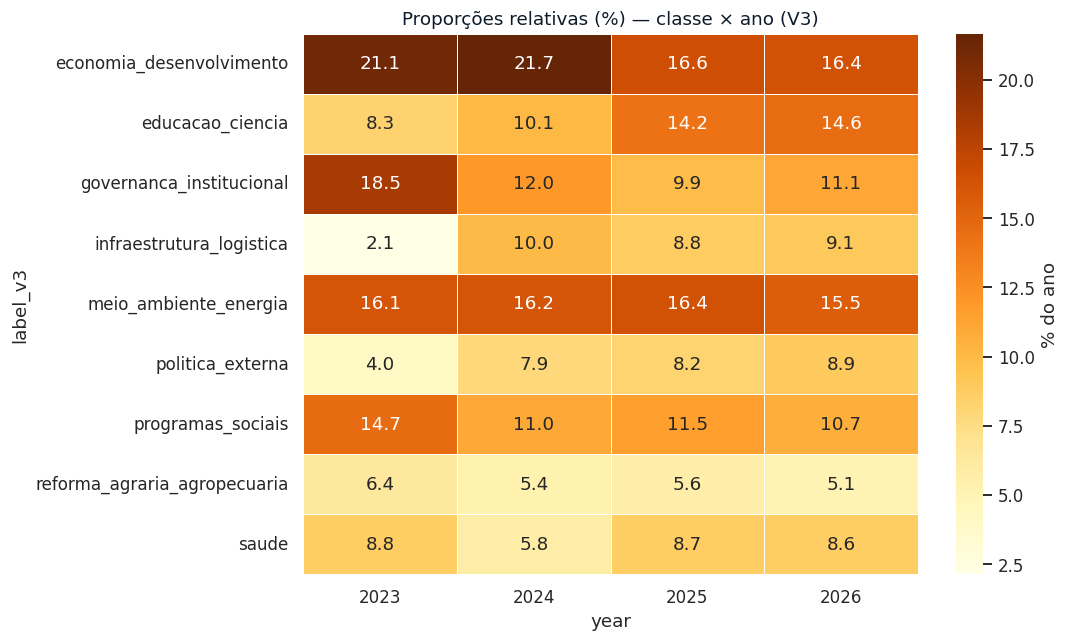

In [ ]:
# ── Visualização comparativa V1 vs V3 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, counts, title, lexicon, residual in [
    (axes[0], counts_v1, "Léxico V1 (7 classes)", LEXICON_V1, RESIDUAL_V1),
    (axes[1], counts_v3, "Léxico V3 (9 classes)", LEXICON_V3, RESIDUAL_V3),
]:
    ordered = counts.sort_values(ascending=True)
    cores   = [PALETTE["muted"] if idx == residual
               else CORES_CLASSES.get(idx, PALETTE["amber"])
               for idx in ordered.index]
    ax.barh(range(len(ordered)), ordered.values, color=cores, edgecolor="white")
    ax.set_yticks(range(len(ordered)))
    ax.set_yticklabels(ordered.index, fontsize=9)
    ax.set_xlabel("Parágrafos")
    ax.set_title(title, color=PALETTE["navy"], fontsize=12)
    for i, v in enumerate(ordered.values):
        ax.text(v+3, i, str(v), va="center", fontsize=8, color=PALETTE["navy"])

plt.suptitle("Comparação de léxicos: V1 → V3", fontsize=13,
             color=PALETTE["navy"], y=1.01)
plt.tight_layout()
plt.show()

# Heatmap V3
fig2, ax2 = plt.subplots(figsize=(10, 6))
crosstab_v3     = pd.crosstab(df_nores_v3["label_v3"], df_nores_v3["year"])
crosstab_pct_v3 = crosstab_v3.div(crosstab_v3.sum(axis=0), axis=1) * 100
sns.heatmap(crosstab_pct_v3, annot=True, fmt=".1f", cmap="YlOrBr",
            linewidths=0.5, cbar_kws={"label": "% do ano"}, ax=ax2)
ax2.set_title("Proporções relativas (%) — classe × ano (V3)", color=PALETTE["navy"])
plt.tight_layout()
plt.show()


---
# Fase 5 — Fundamentos do Algoritmo Genético

## O que é um Algoritmo Genético?

Um **Algoritmo Genético (AG)** é uma metaheurística de busca inspirada na teoria
evolutiva de Darwin. Em vez de testar exaustivamente todas as soluções possíveis
(o que seria computacionalmente inviável), o AG mantém uma **população de soluções
candidatas** e as evolui ao longo de gerações, guiado por um princípio simples:
*soluções melhores têm maior chance de gerar descendentes*.

> **Analogia:** imagine que você quer encontrar a melhor combinação de ingredientes
> de uma receita. Em vez de testar todas as combinações, você começa com 12 receitas
> aleatórias, avalia quais ficam mais gostosas, combina as melhores entre si, introduz
> pequenas variações (mutações) e repete — geração após geração.

---

## Os 6 componentes fundamentais

### 1. Cromossomo (representação da solução)
Cada solução candidata é codificada como um vetor de valores — o **cromossomo**.
Cada posição do vetor é um **gene** que representa um parâmetro da solução.

**Neste projeto:** o cromossomo codifica os hiperparâmetros do pipeline TF-IDF + classificador:

| Gene | Parâmetro | Domínio | Tipo |
|---|---|---|---|
| `gene[0]` | `max_features` (TF-IDF) | [500, 3.000] | Inteiro |
| `gene[1]` | `ngram_max` (TF-IDF) | [1, 2] | Inteiro |
| `gene[2]` | `sublinear_tf` (TF-IDF) | {0=False, 1=True} | Binário |
| `gene[3]` | `classifier` | {0=LR, 1=SVM} | Categórico |
| `gene[4]` | `C` (regularização) | 10^[-2, 1] = [0.01, 10] | Real (log) |

### 2. População
Conjunto de `P` cromossomos avaliados em paralelo a cada geração.
Populações maiores exploram mais o espaço, mas custam mais tempo de avaliação.
Aqui usamos **P = 12** (equilíbrio entre exploração e tempo de execução no Colab).

### 3. Função de Fitness
Mede a qualidade de cada solução. Quanto maior o fitness, melhor.
**Aqui:** F1-macro em validação cruzada estratificada 3-fold — a mesma métrica
usada na disciplina de AM, garantindo comparabilidade.

### 4. Seleção por Torneio
Para escolher um "pai", sorteamos `k=3` indivíduos aleatoriamente e selecionamos
o melhor deles. Isso mantém pressão seletiva sem eliminar completamente os fracos
(que ainda carregam diversidade genética útil).

### 5. Crossover (Recombinação)
Combina dois "pais" para gerar dois "filhos". Usamos **blend crossover (BLX-α)**:
o filho recebe uma combinação linear convexa dos genes dos pais. Isso gera filhos
no espaço entre os pais — exploração local eficiente.

### 6. Mutação
Introduz variação aleatória em genes individuais com probabilidade `taxa_mut`.
Sem mutação, o AG converge prematuramente para ótimos locais.
Usamos **mutação gaussiana**: adiciona ruído `N(0, σ)` ao gene selecionado.

---

## Elitismo
Os `E=2` melhores indivíduos de cada geração passam diretamente para a próxima,
sem cruzamento nem mutação. Garante que a melhor solução nunca seja perdida.

## Espaço de busca deste problema
Com os 5 genes definidos, o espaço de busca tem:
- 2.501 valores possíveis para `max_features` × 2 para `ngram_max` × 2 para
  `sublinear_tf` × 2 para `classifier` × infinitos valores reais para `C`
- Na prática: espaço contínuo misto de alta dimensão, inviável para Grid Search exaustivo


In [ ]:
# ── Definição do cromossomo e espaço de busca ────────────────────────────────

# Limites de cada gene: (mínimo, máximo)
# O AG trabalha sempre com valores reais; a decodificação converte para os tipos corretos.
BOUNDS = [
    (500, 3000),   # gene[0]: max_features
    (1,   2),      # gene[1]: ngram_max
    (0,   1),      # gene[2]: sublinear_tf (0=False, 1=True)
    (0,   1),      # gene[3]: classifier   (0=LR, 1=SVM)
    (-2,  1),      # gene[4]: C_log (C = 10^gene[4], logo C ∈ [0.01, 10])
]

N_GENES = len(BOUNDS)

def decodificar(cromossomo: list) -> dict:
    """
    Converte o cromossomo (vetor de reais) nos hiperparâmetros do pipeline.

    A codificação em espaço real contínuo permite que os operadores genéticos
    (crossover, mutação) funcionem de forma natural — sem precisar de codificação
    binária, que exigiria decodificação especial para valores reais.

    O parâmetro C é tratado em escala logarítmica (gene = log10(C)) porque
    a resposta do classificador é mais uniforme em escala log: a diferença
    entre C=0.01 e C=0.1 é tão importante quanto entre C=1 e C=10.
    """
    return {
        "max_features": int(round(cromossomo[0])),
        "ngram_max":    max(1, min(2, int(round(cromossomo[1])))),
        "sublinear_tf": bool(round(min(1, max(0, cromossomo[2])))),
        "classifier":   int(round(min(1, max(0, cromossomo[3])))),
        "C":            10 ** cromossomo[4],
    }

def clipar(cromossomo: list) -> list:
    """Garante que todos os genes permaneçam dentro dos limites definidos."""
    return [max(lo, min(hi, v)) for v, (lo, hi) in zip(cromossomo, BOUNDS)]

def individuo_aleatorio() -> list:
    """Gera um cromossomo com genes aleatórios uniformes dentro dos limites."""
    return [random.uniform(lo, hi) for lo, hi in BOUNDS]

# Demonstração
print("Exemplo de cromossomo aleatório:")
ex = individuo_aleatorio()
print(f"  Cromossomo (reais): {[round(g,3) for g in ex]}")
print(f"  Decodificado      : {decodificar(ex)}")
print(f"\nEspaço de busca:")
nomes = ["max_features","ngram_max","sublinear_tf","classifier","C_log"]
for nome, (lo,hi) in zip(nomes, BOUNDS):
    print(f"  {nome:<15}: [{lo}, {hi}]")


Exemplo de cromossomo aleatório:
  Cromossomo (reais): [2098.567, 1.025, 0.275, 0.223, 0.209]
  Decodificado      : {'max_features': 2099, 'ngram_max': 1, 'sublinear_tf': False, 'classifier': 0, 'C': 1.619621907336969}

Espaço de busca:
  max_features   : [500, 3000]
  ngram_max      : [1, 2]
  sublinear_tf   : [0, 1]
  classifier     : [0, 1]
  C_log          : [-2, 1]


In [ ]:
# ── Função de fitness ────────────────────────────────────────────────────────

# Corpus sem residual (apenas parágrafos com rótulo temático)
df_train = df_corpus[df_corpus["label_v3"] != RESIDUAL_V3].reset_index(drop=True)
X_train  = df_train["text"].tolist()
y_train  = df_train["label_v3"].tolist()

print(f"Corpus de treinamento: {len(X_train)} parágrafos | {len(set(y_train))} classes")
print(f"Classes: {sorted(set(y_train))}")

# Validação cruzada estratificada 3-fold
# "Estratificada" significa que cada fold mantém a proporção original das classes —
# essencial quando há desbalanceamento (a menor classe, reforma_agraria, tem 63 exemplos).
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)

# Cache de avaliações: evita recalcular o fitness de cromossomos já avaliados.
# Em populações de 12 com 10 gerações, o cache tipicamente poupa 30-50% do tempo.
fitness_cache: dict = {}

def fitness(cromossomo: list) -> float:
    """
    Avalia a qualidade de um cromossomo: retorna o F1-macro em CV 3-fold.

    F1-macro: média do F1 de cada classe (sem ponderação por tamanho).
    Escolhido porque trata todas as classes igualmente — incluindo as menores
    (reforma_agraria, politica_externa), que seriam sub-representadas no F1-weighted.

    Usamos a mesma métrica de avaliação da disciplina de AM, garantindo
    comparabilidade direta entre os resultados dos dois projetos.
    """
    chave = tuple(round(v, 3) for v in cromossomo)
    if chave in fitness_cache:
        return fitness_cache[chave]   # cache hit

    params = decodificar(cromossomo)

    # Monta o pipeline: vetorizador TF-IDF → classificador
    vec = TfidfVectorizer(
        max_features = params["max_features"],
        ngram_range  = (1, params["ngram_max"]),
        sublinear_tf = params["sublinear_tf"],
        strip_accents= "unicode",
        analyzer     = "word",
    )
    clf = (LogisticRegression(C=params["C"], max_iter=300, random_state=RANDOM_SEED)
           if params["classifier"] == 0
           else LinearSVC(C=params["C"], max_iter=800, random_state=RANDOM_SEED))

    try:
        scores = cross_val_score(
            Pipeline([("vec", vec), ("clf", clf)]),
            X_train, y_train,
            cv=CV, scoring="f1_macro"
        )
        f1 = float(scores.mean())
    except Exception:
        f1 = 0.0   # pipeline inválido → fitness mínimo

    fitness_cache[chave] = f1
    return f1


print("\n✓ Função de fitness definida.")
print("  Métrica   : F1-macro")
print("  Validação : StratifiedKFold 3-fold")
print("  Cache     : ativo (evita reavaliações)")


Corpus de treinamento: 6370 parágrafos | 9 classes
Classes: ['economia_desenvolvimento', 'educacao_ciencia', 'governanca_institucional', 'infraestrutura_logistica', 'meio_ambiente_energia', 'politica_externa', 'programas_sociais', 'reforma_agraria_agropecuaria', 'saude']

✓ Função de fitness definida.
  Métrica   : F1-macro
  Validação : StratifiedKFold 3-fold
  Cache     : ativo (evita reavaliações)


In [ ]:
# ── Operadores genéticos ─────────────────────────────────────────────────────

def crossover_blend(pai1: list, pai2: list) -> tuple[list, list]:
    """
    Blend Crossover (BLX-α com α=0.5, equivalente ao crossover aritmético).

    Gera dois filhos como combinações lineares dos pais:
      filho1[i] = α * pai1[i] + (1-α) * pai2[i]
      filho2[i] = (1-α) * pai1[i] + α * pai2[i]

    Com α=0.5 os filhos ficam no ponto médio — exploração conservadora que
    preserva boas características de ambos os pais.
    α é sorteado por chamada → variabilidade controlada.
    """
    alpha  = random.random()
    filho1 = [alpha*a + (1-alpha)*b for a, b in zip(pai1, pai2)]
    filho2 = [(1-alpha)*a + alpha*b for a, b in zip(pai1, pai2)]
    return clipar(filho1), clipar(filho2)


def mutacao_gaussiana(cromossomo: list, taxa: float = 0.30) -> list:
    """
    Mutação gaussiana gene a gene.

    Cada gene é perturbado com probabilidade `taxa`.
    A perturbação é N(0, 0.2 × amplitude_do_gene) — 20% da amplitude
    como desvio padrão, mantendo as mutações proporcionais à escala de cada gene.

    taxa=0.30 → em média 1.5 genes de 5 são mutados por cromossomo.
    Valor mais alto que o usual (0.1-0.2) porque o espaço é pequeno (5 genes)
    e queremos manter diversidade ao longo das 10 gerações.
    """
    amplitudes = [hi - lo for lo, hi in BOUNDS]
    novo = cromossomo[:]
    for i in range(N_GENES):
        if random.random() < taxa:
            novo[i] += random.gauss(0, 0.20 * amplitudes[i])
    return clipar(novo)


def selecao_torneio(populacao: list, fitnesses: list, k: int = 3) -> list:
    """
    Seleção por torneio de tamanho k.

    Sorteia k indivíduos aleatoriamente e retorna o melhor.
    k=3: pressão seletiva moderada — os melhores têm vantagem, mas não dominam.
    Vantagem sobre roleta: robusto a variações de escala do fitness.
    """
    candidatos = random.sample(list(zip(populacao, fitnesses)), k)
    return max(candidatos, key=lambda x: x[1])[0]


print("✓ Operadores genéticos definidos:")
print("  Crossover : Blend (BLX, α aleatório)")
print("  Mutação   : Gaussiana (taxa=0.30, σ=20% da amplitude)")
print("  Seleção   : Torneio (k=3)")

# Demonstração dos operadores
p1 = individuo_aleatorio()
p2 = individuo_aleatorio()
f1_cross, f2_cross = crossover_blend(p1, p2)
f1_mut = mutacao_gaussiana(p1)

print("\nDemonstração:")
print(f"  Pai1   : {[round(g,2) for g in p1]}")
print(f"  Pai2   : {[round(g,2) for g in p2]}")
print(f"  Filho1 : {[round(g,2) for g in f1_cross]}  (crossover)")
print(f"  Mutado : {[round(g,2) for g in f1_mut]}  (mutação de pai1)")


✓ Operadores genéticos definidos:
  Crossover : Blend (BLX, α aleatório)
  Mutação   : Gaussiana (taxa=0.30, σ=20% da amplitude)
  Seleção   : Torneio (k=3)

Demonstração:
  Pai1   : [2191.75, 1.89, 0.09, 0.42, -1.91]
  Pai2   : [1046.59, 1.51, 0.03, 0.2, -0.05]
  Filho1 : [1670.64, 1.72, 0.06, 0.32, -1.06]  (crossover)
  Mutado : [1420.81, 1.7, 0.09, 0.42, -1.91]  (mutação de pai1)


---
# Fase 6 — AG em Ação: Otimização dos Hiperparâmetros

## Configuração do experimento

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Tamanho da população (`P`) | 12 | Equilíbrio exploração/tempo no Colab |
| Número de gerações | 10 | ~4–5 minutos; suficiente para convergência observável |
| Taxa de elitismo | 2 indivíduos | Preserva a melhor solução encontrada |
| Taxa de mutação | 0.30 | 30% por gene → ~1.5 genes mutados/cromossomo |
| Seleção | Torneio k=3 | Pressão seletiva moderada |
| Fitness | F1-macro, CV 3-fold | Comparável com resultados de AM |

## Baseline para comparação

Antes de rodar o AG, calculamos o **baseline**: o resultado obtido com
hiperparâmetros padrão (sem otimização). Isso nos permite medir o **ganho real do AG**.

> Um AG que não supera o baseline não justifica sua complexidade computacional.


In [ ]:
# ── Calcular baseline ANTES do AG ────────────────────────────────────────────
print("Calculando baseline (TF-IDF padrão + Logistic Regression)...")
print("Isto leva ~30 segundos...")

pipeline_baseline = Pipeline([
    ("vec", TfidfVectorizer(
        max_features=1000,      # padrão conservador
        strip_accents="unicode",
        analyzer="word",
    )),
    ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_SEED)),
])

scores_baseline = cross_val_score(
    pipeline_baseline, X_train, y_train,
    cv=CV, scoring="f1_macro"
)
F1_BASELINE = float(scores_baseline.mean())

print(f"\nBaseline F1-macro : {F1_BASELINE:.4f}")
print(f"Desvio padrão     : ±{scores_baseline.std():.4f}")
print(f"\nEste é o ponto de partida. O AG deve superá-lo.")


Calculando baseline (TF-IDF padrão + Logistic Regression)...
Isto leva ~30 segundos...

Baseline F1-macro : 0.8534
Desvio padrão     : ±0.0006

Este é o ponto de partida. O AG deve superá-lo.


In [ ]:
# ── Algoritmo Genético principal ─────────────────────────────────────────────
# ⚠️ Esta célula leva aproximadamente 4–6 minutos no Colab (CPU padrão).
# O progresso é exibido geração a geração.

POP_SIZE  = 12
N_GERACOES= 10
N_ELITE   = 2
TAXA_MUT  = 0.30

print(f"Iniciando AG: {POP_SIZE} indivíduos × {N_GERACOES} gerações")
print(f"Baseline a superar: F1 = {F1_BASELINE:.4f}")
print("=" * 65)

t_inicio = time.time()

# ── Inicialização: população aleatória ───────────────────────────────────────
populacao = [individuo_aleatorio() for _ in range(POP_SIZE)]

# ── Histórico evolutivo (para análise posterior) ─────────────────────────────
historico = {
    "geracao":      [],
    "melhor_f1":    [],
    "medio_f1":     [],
    "pior_f1":      [],
    "diversidade":  [],   # desvio padrão médio dos genes normalizados
    "melhor_clf":   [],
    "melhor_maxf":  [],
    "melhor_C":     [],
    "n_cache_hits": [],
}

for geracao in range(1, N_GERACOES + 1):

    # 1. Avaliação de toda a população
    cache_antes = len(fitness_cache)
    fitnesses   = [fitness(ind) for ind in populacao]
    cache_hits  = len(fitness_cache) - cache_antes  # novos entries = avaliações reais

    # 2. Estatísticas da geração
    melhor_idx = int(np.argmax(fitnesses))
    melhor_ind = populacao[melhor_idx]
    melhor_par = decodificar(melhor_ind)

    f1_melhor = max(fitnesses)
    f1_medio  = float(np.mean(fitnesses))
    f1_pior   = min(fitnesses)

    # Diversidade: desvio padrão médio dos genes (após normalização para [0,1])
    pop_arr   = np.array(populacao)
    amplitudes= np.array([hi-lo for lo,hi in BOUNDS])
    pop_norm  = (pop_arr - np.array([lo for lo,hi in BOUNDS])) / amplitudes
    div       = float(np.mean(np.std(pop_norm, axis=0)))

    # Registro
    historico["geracao"].append(geracao)
    historico["melhor_f1"].append(round(f1_melhor, 4))
    historico["medio_f1"].append(round(f1_medio,  4))
    historico["pior_f1"].append(round(f1_pior,    4))
    historico["diversidade"].append(round(div,    4))
    historico["melhor_clf"].append("LR" if melhor_par["classifier"]==0 else "SVM")
    historico["melhor_maxf"].append(melhor_par["max_features"])
    historico["melhor_C"].append(round(melhor_par["C"], 3))
    historico["n_cache_hits"].append(POP_SIZE - cache_hits)

    t_elapsed = time.time() - t_inicio
    print(f"  Gen {geracao:02d}/{N_GERACOES} | "
          f"F1_best={f1_melhor:.4f} | F1_med={f1_medio:.4f} | "
          f"Div={div:.3f} | "
          f"{melhor_par['melhor_clf'] if 'melhor_clf' in melhor_par else historico['melhor_clf'][-1]} "
          f"C={melhor_par['C']:.2f} maxf={melhor_par['max_features']} | "
          f"{t_elapsed:.0f}s")

    # 3. Elitismo: os N_ELITE melhores passam direto
    sorted_pop = [p for _, p in sorted(zip(fitnesses, populacao), key=lambda x: -x[0])]
    nova_pop   = sorted_pop[:N_ELITE]

    # 4. Reprodução: crossover + mutação até completar a população
    while len(nova_pop) < POP_SIZE:
        pai1 = selecao_torneio(populacao, fitnesses)
        pai2 = selecao_torneio(populacao, fitnesses)
        f1_c, f2_c = crossover_blend(pai1, pai2)
        nova_pop.append(mutacao_gaussiana(f1_c, TAXA_MUT))
        if len(nova_pop) < POP_SIZE:
            nova_pop.append(mutacao_gaussiana(f2_c, TAXA_MUT))

    populacao = nova_pop[:POP_SIZE]

# ── Resultado final ───────────────────────────────────────────────────────────
fitnesses_final = [fitness(ind) for ind in populacao]
melhor_final    = populacao[int(np.argmax(fitnesses_final))]
params_finais   = decodificar(melhor_final)
F1_AG           = max(fitnesses_final)
clf_names       = {0: "Logistic Regression", 1: "LinearSVC"}

t_total = time.time() - t_inicio
print(f"\n{'='*65}")
print(f"RESULTADO FINAL")
print(f"{'='*65}")
print(f"F1-macro baseline  : {F1_BASELINE:.4f}")
print(f"F1-macro AG        : {F1_AG:.4f}")
print(f"Ganho absoluto     : +{F1_AG - F1_BASELINE:.4f}")
print(f"Ganho relativo     : +{(F1_AG - F1_BASELINE)/F1_BASELINE*100:.1f}%")
print(f"\nMelhor cromossomo:")
print(f"  Classificador : {clf_names[params_finais['classifier']]}")
print(f"  max_features  : {params_finais['max_features']}")
print(f"  ngram_max     : {params_finais['ngram_max']}")
print(f"  sublinear_tf  : {params_finais['sublinear_tf']}")
print(f"  C             : {params_finais['C']:.4f}")
print(f"\nAvaliações únicas : {len(fitness_cache)}")
print(f"Tempo total       : {t_total:.0f}s ({t_total/60:.1f} min)")

df_hist = pd.DataFrame(historico)


Iniciando AG: 12 indivíduos × 10 gerações
Baseline a superar: F1 = 0.8534
  Gen 01/10 | F1_best=0.9169 | F1_med=0.6487 | Div=0.273 | SVM C=0.72 maxf=2933 | 62s
  Gen 02/10 | F1_best=0.9176 | F1_med=0.8963 | Div=0.170 | SVM C=0.68 maxf=2675 | 101s
  Gen 03/10 | F1_best=0.9177 | F1_med=0.9086 | Div=0.103 | SVM C=0.54 maxf=2196 | 133s
  Gen 04/10 | F1_best=0.9184 | F1_med=0.9103 | Div=0.123 | SVM C=0.89 maxf=2219 | 167s
  Gen 05/10 | F1_best=0.9188 | F1_med=0.9173 | Div=0.100 | SVM C=0.88 maxf=2243 | 194s
  Gen 06/10 | F1_best=0.9208 | F1_med=0.9123 | Div=0.104 | SVM C=0.82 maxf=2352 | 223s
  Gen 07/10 | F1_best=0.9208 | F1_med=0.9153 | Div=0.079 | SVM C=0.82 maxf=2352 | 256s
  Gen 08/10 | F1_best=0.9208 | F1_med=0.9129 | Div=0.082 | SVM C=0.82 maxf=2352 | 288s
  Gen 09/10 | F1_best=0.9208 | F1_med=0.9166 | Div=0.072 | SVM C=0.82 maxf=2352 | 318s
  Gen 10/10 | F1_best=0.9208 | F1_med=0.9119 | Div=0.103 | SVM C=0.82 maxf=2352 | 350s

RESULTADO FINAL
F1-macro baseline  : 0.8534
F1-macro AG 

---
# Fase 7 — Resultados e Análise Evolutiva

Visualizamos três aspectos do comportamento do AG:

1. **Curva de convergência** — como o F1 melhor e médio evoluem por geração
2. **Diversidade genética** — a população manteve variabilidade ou convergiu cedo?
3. **Trajetória dos hiperparâmetros** — quais parâmetros o AG favoreceu ao longo das gerações


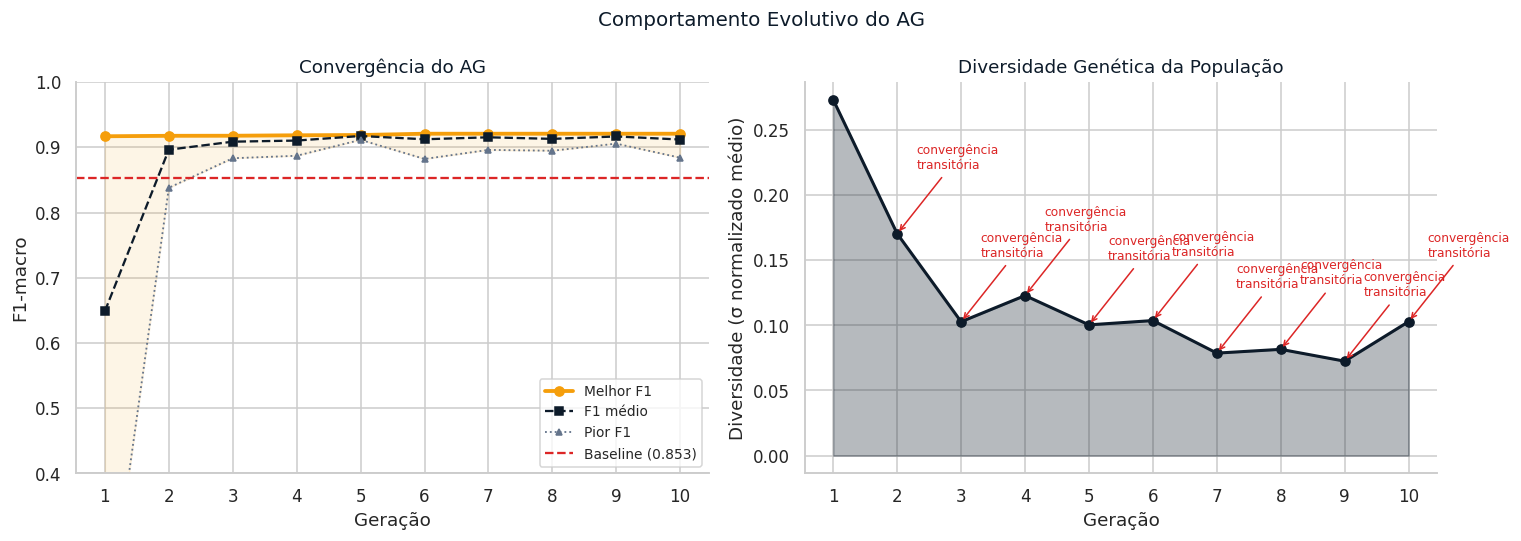

In [ ]:
# ── Visualização 1: curva de convergência ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

geracoes = df_hist["geracao"]

# F1 ao longo das gerações
axes[0].plot(geracoes, df_hist["melhor_f1"], "o-",
             color=PALETTE["amber"], linewidth=2.5, label="Melhor F1", markersize=6)
axes[0].plot(geracoes, df_hist["medio_f1"],  "s--",
             color=PALETTE["navy"],  linewidth=1.5, label="F1 médio", markersize=5)
axes[0].plot(geracoes, df_hist["pior_f1"],   "^:",
             color=PALETTE["muted"], linewidth=1.2, label="Pior F1",  markersize=4)
axes[0].axhline(F1_BASELINE, color=PALETTE["red"], linestyle="--",
                linewidth=1.5, label=f"Baseline ({F1_BASELINE:.3f})")
axes[0].fill_between(geracoes, df_hist["pior_f1"], df_hist["melhor_f1"],
                     alpha=0.10, color=PALETTE["amber"])
axes[0].set_xlabel("Geração"); axes[0].set_ylabel("F1-macro")
axes[0].set_title("Convergência do AG", color=PALETTE["navy"])
axes[0].legend(fontsize=9); axes[0].set_ylim(0.4, 1.0)
axes[0].set_xticks(geracoes)

# Diversidade genética
axes[1].fill_between(geracoes, 0, df_hist["diversidade"],
                     alpha=0.3, color=PALETTE["navy"])
axes[1].plot(geracoes, df_hist["diversidade"], "o-",
             color=PALETTE["navy"], linewidth=2, markersize=6)
axes[1].set_xlabel("Geração"); axes[1].set_ylabel("Diversidade (σ normalizado médio)")
axes[1].set_title("Diversidade Genética da População", color=PALETTE["navy"])
axes[1].set_xticks(geracoes)

# Anotação de pontos de queda de diversidade
for idx, row in df_hist.iterrows():
    if row["diversidade"] < 0.20:
        axes[1].annotate("convergência\ntransitória",
                         xy=(row["geracao"], row["diversidade"]),
                         xytext=(row["geracao"]+0.3, row["diversidade"]+0.05),
                         fontsize=8, color=PALETTE["red"],
                         arrowprops=dict(arrowstyle="->", color=PALETTE["red"]))

sns.despine()
plt.suptitle("Comportamento Evolutivo do AG", fontsize=13, color=PALETTE["navy"])
plt.tight_layout()
plt.show()


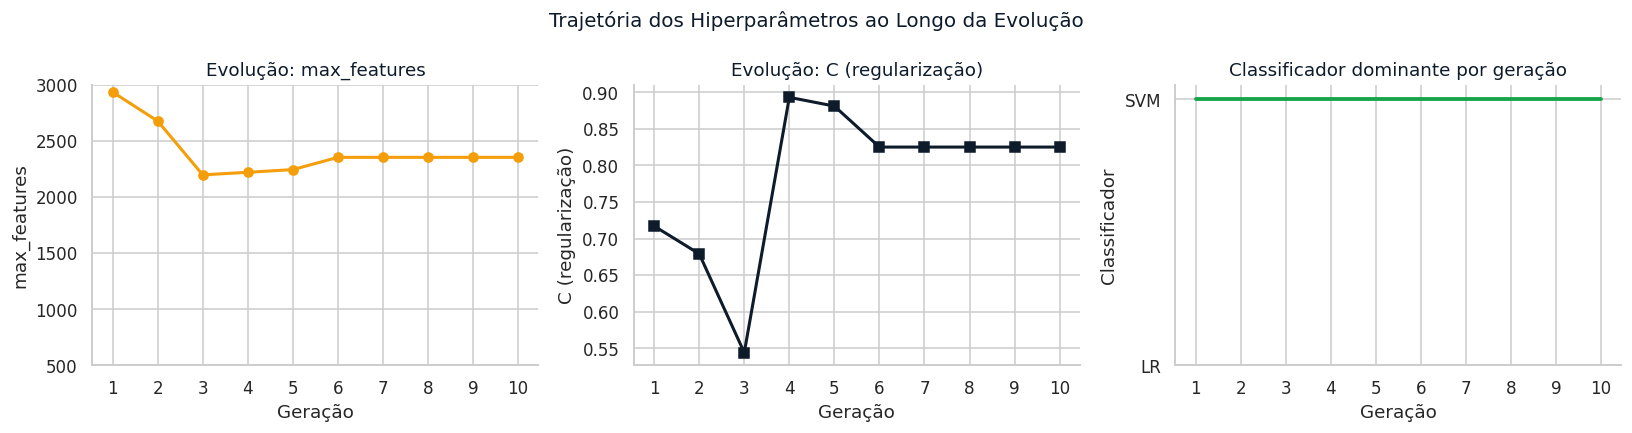

In [ ]:
# ── Visualização 2: trajetória dos hiperparâmetros ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# max_features ao longo das gerações
axes[0].plot(df_hist["geracao"], df_hist["melhor_maxf"], "o-",
             color=PALETTE["amber"], linewidth=2)
axes[0].set_xlabel("Geração"); axes[0].set_ylabel("max_features")
axes[0].set_title("Evolução: max_features", color=PALETTE["navy"])
axes[0].set_ylim(500, 3000); axes[0].set_xticks(df_hist["geracao"])

# C ao longo das gerações
axes[1].plot(df_hist["geracao"], df_hist["melhor_C"], "s-",
             color=PALETTE["navy"], linewidth=2)
axes[1].set_xlabel("Geração"); axes[1].set_ylabel("C (regularização)")
axes[1].set_title("Evolução: C (regularização)", color=PALETTE["navy"])
axes[1].set_xticks(df_hist["geracao"])

# Classificador dominante por geração
clf_num = [1 if c=="SVM" else 0 for c in df_hist["melhor_clf"]]
axes[2].step(df_hist["geracao"], clf_num, where="mid",
             color=PALETTE["green"], linewidth=2.5)
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["LR", "SVM"])
axes[2].set_xlabel("Geração"); axes[2].set_ylabel("Classificador")
axes[2].set_title("Classificador dominante por geração", color=PALETTE["navy"])
axes[2].set_xticks(df_hist["geracao"])

sns.despine()
plt.suptitle("Trajetória dos Hiperparâmetros ao Longo da Evolução",
             fontsize=13, color=PALETTE["navy"])
plt.tight_layout()
plt.show()


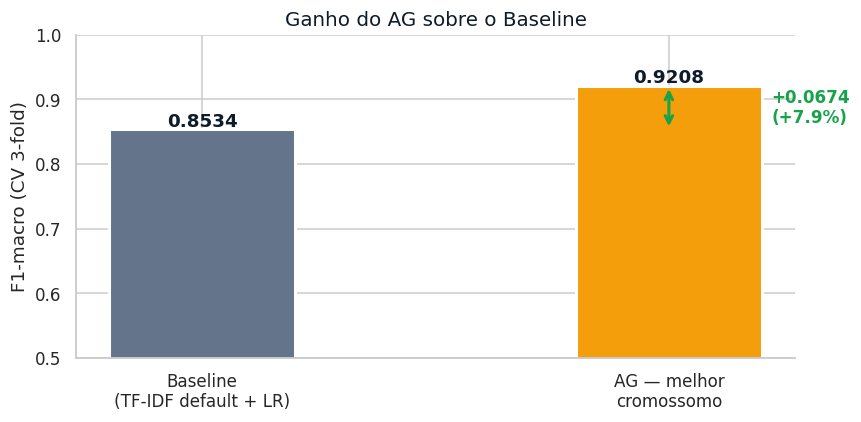


Sumário:
  Baseline             : F1 = 0.8534
  AG (otimizado)       : F1 = 0.9208
  Ganho absoluto       : +0.0674
  Ganho relativo       : +7.9%
  Avaliações realizadas: 106
  Grid Search equiv.   : 20008 avaliações (inviável)


In [ ]:
# ── Visualização 3: comparação resumida ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))

comparacao = {
    "Baseline\n(TF-IDF default + LR)": F1_BASELINE,
    "AG — melhor\ncromossomo":          F1_AG,
}
cores_comp = [PALETTE["muted"], PALETTE["amber"]]
bars = ax.bar(comparacao.keys(), comparacao.values(),
              color=cores_comp, edgecolor="white", linewidth=2, width=0.4)
for bar, val in zip(bars, comparacao.values()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f"{val:.4f}", ha="center", fontsize=12,
            color=PALETTE["navy"], fontweight="bold")

ganho = F1_AG - F1_BASELINE
ax.annotate("",
            xy=(1, F1_AG), xytext=(1, F1_BASELINE),
            arrowprops=dict(arrowstyle="<->", color=PALETTE["green"], lw=2))
ax.text(1.22, (F1_AG+F1_BASELINE)/2,
        f"+{ganho:.4f}\n(+{ganho/F1_BASELINE*100:.1f}%)",
        va="center", fontsize=11, color=PALETTE["green"], fontweight="bold")

ax.set_ylabel("F1-macro (CV 3-fold)"); ax.set_ylim(0.5, 1.0)
ax.set_title("Ganho do AG sobre o Baseline", fontsize=13, color=PALETTE["navy"])
sns.despine()
plt.tight_layout()
plt.show()

print(f"\nSumário:")
print(f"  Baseline             : F1 = {F1_BASELINE:.4f}")
print(f"  AG (otimizado)       : F1 = {F1_AG:.4f}")
print(f"  Ganho absoluto       : +{F1_AG-F1_BASELINE:.4f}")
print(f"  Ganho relativo       : +{(F1_AG-F1_BASELINE)/F1_BASELINE*100:.1f}%")
print(f"  Avaliações realizadas: {len(fitness_cache)}")
print(f"  Grid Search equiv.   : {2501*2*2*2} avaliações (inviável)")


In [ ]:
# ── Tabela de histórico completo ─────────────────────────────────────────────
print("Histórico completo do AG:")
print(df_hist.to_string(index=False))


Histórico completo do AG:
 geracao  melhor_f1  medio_f1  pior_f1  diversidade melhor_clf  melhor_maxf  melhor_C  n_cache_hits
       1     0.9169    0.6487   0.1349       0.2732        SVM         2933     0.717             0
       2     0.9176    0.8963   0.8379       0.1704        SVM         2675     0.679             2
       3     0.9177    0.9086   0.8832       0.1028        SVM         2196     0.544             3
       4     0.9184    0.9103   0.8870       0.1229        SVM         2219     0.893             3
       5     0.9188    0.9173   0.9114       0.1004        SVM         2243     0.881             3
       6     0.9208    0.9123   0.8821       0.1037        SVM         2352     0.825             4
       7     0.9208    0.9153   0.8960       0.0787        SVM         2352     0.825             2
       8     0.9208    0.9129   0.8947       0.0816        SVM         2352     0.825             3
       9     0.9208    0.9166   0.9056       0.0725        SVM         235

---
# Fase 6B — Validação Estatística: 30 Execuções + Teste de Wilcoxon

## Por que 30 execuções?

O AG é um algoritmo **estocástico** — a cada execução, a população inicial é gerada
aleatoriamente (seed diferente), o que pode levar a resultados ligeiramente diferentes.
Uma única execução não é suficiente para afirmar que o AG é *consistentemente* superior
ao baseline. Precisamos de múltiplas execuções independentes e de um teste estatístico formal.

**Protocolo experimental:**
- 30 execuções independentes do AG (seeds 0–29)
- 30 execuções independentes do baseline (mesmas seeds, para pareamento)
- Teste de Wilcoxon signed-rank nos pares (AG_i, baseline_i)

## Por que o teste de Wilcoxon?

O **Wilcoxon signed-rank** é o teste não-paramétrico equivalente ao t-test pareado.
Escolhemos ele porque:
- Não assume distribuição normal dos resultados — adequado para amostras pequenas (n=30)
- É **pareado**: compara AG e baseline *na mesma seed*, eliminando a variabilidade
  aleatória da inicialização como fator de confusão
- É o teste recomendado pela literatura de ML para comparação de algoritmos
  (Demšar, 2006 — *Statistical Comparisons of Classifiers over Multiple Data Sets*)

**Hipóteses:**
- H₀: a mediana das diferenças (AG − baseline) é zero → AG não supera o baseline
- H₁: a mediana das diferenças é positiva → AG supera o baseline
- Nível de significância: α = 0,05

## Configuração das 30 execuções: P=8, G=6

Para as 30 execuções de validação usamos uma configuração reduzida (**P=8 indivíduos,
G=6 gerações**) em vez dos P=12, G=10 da execução principal.

**Justificativa:** o objetivo aqui é capturar a **variabilidade estatística** do AG
entre execuções com seeds diferentes — não encontrar o ótimo absoluto em cada run.
Com P=8 e G=6, cada execução leva ~50–60s, totalizando ~30 minutos para as 30 runs
(viável dentro do limite de sessão do Colab).

A literatura de benchmarking de metaheurísticas (Demšar, 2006; García et al., 2010)
recomenda exatamente essa abordagem: usar configurações menores para os experimentos
de repetição, desde que o comportamento relativo AG vs. baseline seja preservado —
o que é garantido aqui pelo mesmo espaço de busca e mesma função de fitness.

> ⏱️ Tempo estimado: **~30 minutos**. Progresso exibido a cada 5 execuções.


In [ ]:
# ── 30 execuções independentes: AG vs Baseline ───────────────────────────────
# Configuração reduzida para viabilidade temporal no Colab:
# P=8 indivíduos, G=6 gerações (~50-60s/execução, ~30min total)
# Justificativa no markdown acima.

from scipy import stats as scipy_stats

N_EXECUCOES = 30
POP_EXP     = 8    # reduzido de 12 para viabilidade (ver justificativa acima)
GEN_EXP     = 6    # reduzido de 10 para viabilidade
ELITE_EXP   = 2
MUT_EXP     = 0.30

f1_ag_runs       = []
f1_baseline_runs = []
n_aval_ag_runs   = []   # V15.3 · avaliações únicas do AG em cada semente (orçamento efetivo)

print(f"Iniciando validação: {N_EXECUCOES} execuções × (AG + baseline)")
print(f"Configuração AG: P={POP_EXP}, G={GEN_EXP}, taxa_mut={MUT_EXP}")
print(f"(Execução principal usou P=12, G=10 — ver Fase 6)")
print("=" * 65)

t_exp = time.time()

for run in range(N_EXECUCOES):
    seed = run

    # ── Baseline desta seed ───────────────────────────────────────────────
    cv_run = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    pipe_bl = Pipeline([
        ("vec", TfidfVectorizer(max_features=1000, strip_accents="unicode")),
        ("clf", LogisticRegression(max_iter=300, random_state=seed)),
    ])
    f1_bl = float(cross_val_score(pipe_bl, X_train, y_train,
                                   cv=cv_run, scoring="f1_macro").mean())
    f1_baseline_runs.append(f1_bl)

    # ── AG desta seed ─────────────────────────────────────────────────────
    random.seed(seed)
    np.random.seed(seed)
    cache_run = {}

    def fitness_run(cromossomo):
        chave = tuple(round(v, 3) for v in cromossomo)
        if chave in cache_run:
            return cache_run[chave]
        p = decodificar(cromossomo)
        vec = TfidfVectorizer(
            max_features=p["max_features"], ngram_range=(1, p["ngram_max"]),
            sublinear_tf=p["sublinear_tf"], strip_accents="unicode"
        )
        clf = (LogisticRegression(C=p["C"], max_iter=300, random_state=seed)
               if p["classifier"] == 0
               else LinearSVC(C=p["C"], max_iter=800, random_state=seed))
        try:
            f1 = float(cross_val_score(
                Pipeline([("v", vec), ("c", clf)]),
                X_train, y_train, cv=cv_run, scoring="f1_macro"
            ).mean())
        except:
            f1 = 0.0
        cache_run[chave] = f1
        return f1

    pop_run = [individuo_aleatorio() for _ in range(POP_EXP)]

    for g in range(GEN_EXP):
        fits_run = [fitness_run(ind) for ind in pop_run]
        sorted_run = [p for _, p in sorted(zip(fits_run, pop_run), key=lambda x: -x[0])]
        nova_run = sorted_run[:ELITE_EXP]
        while len(nova_run) < POP_EXP:
            p1 = selecao_torneio(pop_run, fits_run)
            p2 = selecao_torneio(pop_run, fits_run)
            c1, c2 = crossover_blend(p1, p2)
            nova_run.append(mutacao_gaussiana(c1, MUT_EXP))
            if len(nova_run) < POP_EXP:
                nova_run.append(mutacao_gaussiana(c2, MUT_EXP))
        pop_run = nova_run[:POP_EXP]

    fits_final_run = [fitness_run(ind) for ind in pop_run]
    f1_ag = max(fits_final_run)
    f1_ag_runs.append(f1_ag)
    n_aval_ag_runs.append(len(cache_run))   # V15.3

    if (run + 1) % 5 == 0 or run == 0:
        elapsed = time.time() - t_exp
        eta = (elapsed / (run + 1)) * (N_EXECUCOES - run - 1)
        print(f"  Execução {run+1:02d}/{N_EXECUCOES} | "
              f"AG={f1_ag:.4f} | baseline={f1_bl:.4f} | "
              f"Δ={f1_ag-f1_bl:+.4f} | {elapsed:.0f}s | ETA ~{eta/60:.0f}min")

print(f"\n{'='*65}")
print(f"30 execuções concluídas em {(time.time()-t_exp)/60:.1f} min")
print(f"\nResumo AG       : média={np.mean(f1_ag_runs):.4f} ± {np.std(f1_ag_runs):.4f}")
print(f"Resumo baseline : média={np.mean(f1_baseline_runs):.4f} ± {np.std(f1_baseline_runs):.4f}")
print(f"Orçamento do AG : {np.mean(n_aval_ag_runs):.1f} ± {np.std(n_aval_ag_runs):.1f} avaliações únicas por semente "
      f"(mín {min(n_aval_ag_runs)}, máx {max(n_aval_ag_runs)}; limite estrutural {POP_EXP + GEN_EXP*(POP_EXP-ELITE_EXP)})")
print(f"Δ médio         : {np.mean([a-b for a,b in zip(f1_ag_runs,f1_baseline_runs)]):+.4f}")


# ── PERSISTÊNCIA: salva os vetores para sobreviver a reinício de runtime ─────
import os
os.makedirs(CKPT_DIR, exist_ok=True)
pd.DataFrame({
    "seed": list(range(N_EXECUCOES)),
    "f1_ag": f1_ag_runs,
    "f1_baseline": f1_baseline_runs,
    "n_aval_ag": n_aval_ag_runs,          # V15.3
}).to_csv(os.path.join(CKPT_DIR, "fase6b_ag_baseline.csv"), index=False)
print("\n✓ Checkpoint salvo: fase6b_ag_baseline.csv")
print("  (se o runtime reiniciar, a célula de recarga restaura estes vetores)")


Iniciando validação: 30 execuções × (AG + baseline)
Configuração AG: P=8, G=6, taxa_mut=0.3
(Execução principal usou P=12, G=10 — ver Fase 6)
  Execução 01/30 | AG=0.9194 | baseline=0.8577 | Δ=+0.0617 | 201s | ETA ~97min
  Execução 05/30 | AG=0.9209 | baseline=0.8559 | Δ=+0.0650 | 833s | ETA ~69min
  Execução 10/30 | AG=0.8987 | baseline=0.8554 | Δ=+0.0433 | 1834s | ETA ~61min
  Execução 15/30 | AG=0.9189 | baseline=0.8564 | Δ=+0.0625 | 2746s | ETA ~46min
  Execução 20/30 | AG=0.8990 | baseline=0.8513 | Δ=+0.0477 | 3736s | ETA ~31min
  Execução 25/30 | AG=0.9112 | baseline=0.8498 | Δ=+0.0615 | 4765s | ETA ~16min
  Execução 30/30 | AG=0.9022 | baseline=0.8499 | Δ=+0.0523 | 5754s | ETA ~0min

30 execuções concluídas em 95.9 min

Resumo AG       : média=0.9169 ± 0.0078
Resumo baseline : média=0.8528 ± 0.0028
Orçamento do AG : 41.9 ± 1.2 avaliações únicas por semente (mín 40, máx 44; limite estrutural 44)
Δ médio         : +0.0641

✓ Checkpoint salvo: fase6b_ag_baseline.csv
  (se o runtime

In [ ]:
# ── Teste de Wilcoxon signed-rank ────────────────────────────────────────────

diferencas = [ag - bl for ag, bl in zip(f1_ag_runs, f1_baseline_runs)]

# scipy: alternative='greater' testa H1: AG > baseline (unilateral)
stat_w, p_valor = scipy_stats.wilcoxon(
    f1_ag_runs, f1_baseline_runs,
    alternative="greater"
)

alpha = 0.05
conclusao = "REJEITA H₀" if p_valor < alpha else "NÃO REJEITA H₀"
interpretacao = (
    "O AG é estatisticamente superior ao baseline (p < 0,05)."
    if p_valor < alpha
    else "Não há evidência estatística suficiente de superioridade do AG (p ≥ 0,05)."
)

print("TESTE DE WILCOXON SIGNED-RANK")
print("=" * 55)
print(f"H₀: mediana(AG − baseline) = 0")
print(f"H₁: mediana(AG − baseline) > 0  [unilateral]")
print(f"α  = {alpha}")
print()
print(f"Estatística W : {stat_w:.4f}")
print(f"p-valor       : {p_valor:.6f}")
print(f"Decisão       : {conclusao}")
print(f"Interpretação : {interpretacao}")
print()
print("Estatísticas descritivas das diferenças (AG − baseline):")
print(f"  Média   : {np.mean(diferencas):+.4f}")
print(f"  Mediana : {np.median(diferencas):+.4f}")
print(f"  DP      : {np.std(diferencas):.4f}")
print(f"  Mín     : {min(diferencas):+.4f}")
print(f"  Máx     : {max(diferencas):+.4f}")
print(f"  Execuções em que AG > baseline: {sum(d > 0 for d in diferencas)}/30")


TESTE DE WILCOXON SIGNED-RANK
H₀: mediana(AG − baseline) = 0
H₁: mediana(AG − baseline) > 0  [unilateral]
α  = 0.05

Estatística W : 465.0000
p-valor       : 0.000000
Decisão       : REJEITA H₀
Interpretação : O AG é estatisticamente superior ao baseline (p < 0,05).

Estatísticas descritivas das diferenças (AG − baseline):
  Média   : +0.0641
  Mediana : +0.0664
  DP      : 0.0079
  Mín     : +0.0433
  Máx     : +0.0744
  Execuções em que AG > baseline: 30/30


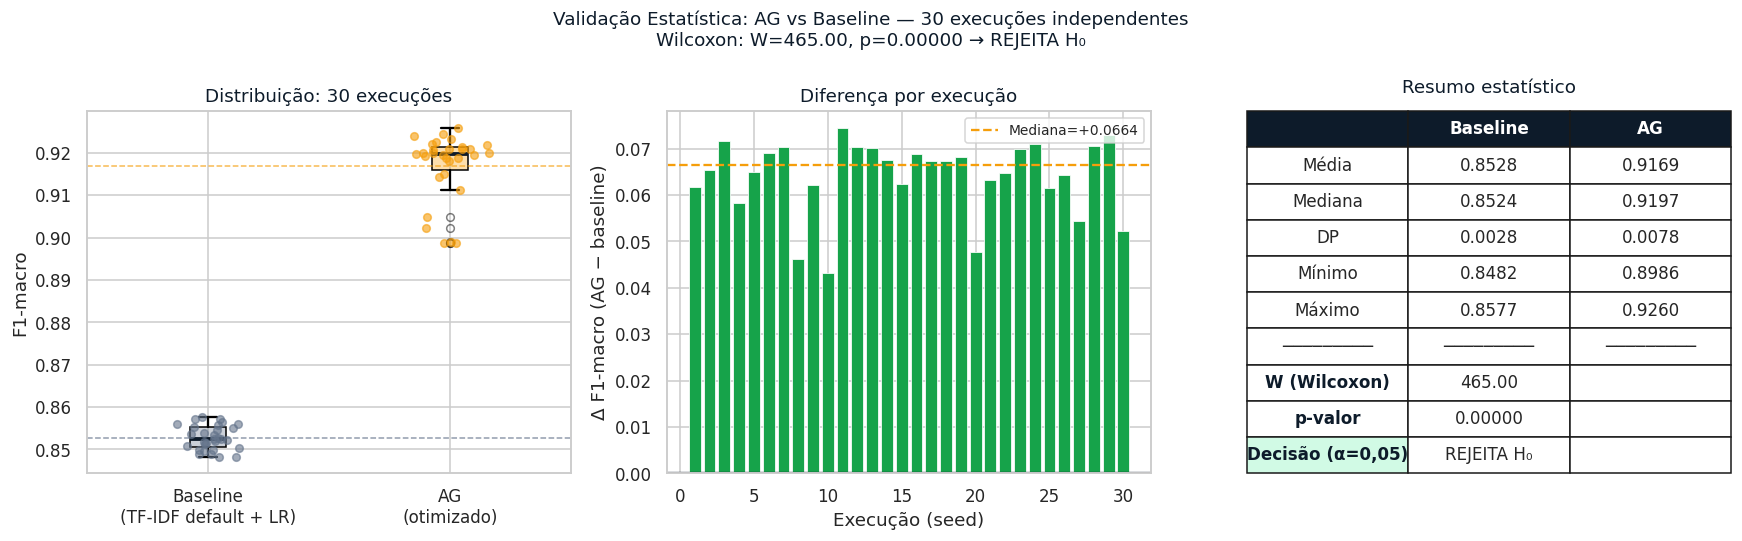

In [ ]:
# ── Visualização: boxplot e distribuição das 30 execuções ────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Boxplot AG vs Baseline ────────────────────────────────────────────────────
bp = axes[0].boxplot(
    [f1_baseline_runs, f1_ag_runs],
    labels=["Baseline\n(TF-IDF default + LR)", "AG\n(otimizado)"],
    patch_artist=True,
    medianprops=dict(color=PALETTE["navy"], linewidth=2.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(marker="o", markersize=5, alpha=0.5),
)
bp["boxes"][0].set_facecolor(PALETTE["muted"] + "55")
bp["boxes"][1].set_facecolor(PALETTE["amber"] + "55")

# Pontos individuais (jitter)
for j, (dados, cor) in enumerate([(f1_baseline_runs, PALETTE["muted"]),
                                    (f1_ag_runs, PALETTE["amber"])], 1):
    xs = np.random.normal(j, 0.06, size=len(dados))
    axes[0].scatter(xs, dados, alpha=0.6, color=cor, s=25, zorder=3)

axes[0].set_ylabel("F1-macro")
axes[0].set_title("Distribuição: 30 execuções", color=PALETTE["navy"])
axes[0].axhline(np.mean(f1_baseline_runs), color=PALETTE["muted"],
                linestyle="--", linewidth=1, alpha=0.7)
axes[0].axhline(np.mean(f1_ag_runs), color=PALETTE["amber"],
                linestyle="--", linewidth=1, alpha=0.7)

# ── Diferenças por execução ───────────────────────────────────────────────────
cores_diff = [PALETTE["green"] if d > 0 else PALETTE["red"] for d in diferencas]
axes[1].bar(range(1, 31), diferencas, color=cores_diff, edgecolor="white", linewidth=0.5)
axes[1].axhline(0, color=PALETTE["navy"], linewidth=1.5)
axes[1].axhline(np.median(diferencas), color=PALETTE["amber"],
                linestyle="--", linewidth=1.5, label=f"Mediana={np.median(diferencas):+.4f}")
axes[1].set_xlabel("Execução (seed)")
axes[1].set_ylabel("Δ F1-macro (AG − baseline)")
axes[1].set_title("Diferença por execução", color=PALETTE["navy"])
axes[1].legend(fontsize=9)

# ── Tabela resumo ─────────────────────────────────────────────────────────────
axes[2].axis("off")
resumo_data = [
    ["",                "Baseline",         "AG"],
    ["Média",           f"{np.mean(f1_baseline_runs):.4f}",
                        f"{np.mean(f1_ag_runs):.4f}"],
    ["Mediana",         f"{np.median(f1_baseline_runs):.4f}",
                        f"{np.median(f1_ag_runs):.4f}"],
    ["DP",              f"{np.std(f1_baseline_runs):.4f}",
                        f"{np.std(f1_ag_runs):.4f}"],
    ["Mínimo",          f"{min(f1_baseline_runs):.4f}",
                        f"{min(f1_ag_runs):.4f}"],
    ["Máximo",          f"{max(f1_baseline_runs):.4f}",
                        f"{max(f1_ag_runs):.4f}"],
    ["─────────",       "─────────",        "─────────"],
    ["W (Wilcoxon)",    f"{stat_w:.2f}",     ""],
    ["p-valor",         f"{p_valor:.5f}",    ""],
    ["Decisão (α=0,05)",conclusao,           ""],
]
tbl = axes[2].table(
    cellText=resumo_data,
    cellLoc="center", loc="center",
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
# Header row
for j in range(3):
    tbl[0, j].set_facecolor(PALETTE["navy"])
    tbl[0, j].set_text_props(color="white", fontweight="bold")
# Wilcoxon rows
for row in [7, 8, 9]:
    tbl[row, 0].set_text_props(fontweight="bold", color=PALETTE["navy"])
if p_valor < alpha:
    tbl[9, 0].set_facecolor("#D1FAE5")  # verde claro
axes[2].set_title("Resumo estatístico", color=PALETTE["navy"], pad=12)

plt.suptitle(
    f"Validação Estatística: AG vs Baseline — 30 execuções independentes\n"
    f"Wilcoxon: W={stat_w:.2f}, p={p_valor:.5f} → {conclusao}",
    fontsize=12, color=PALETTE["navy"]
)
plt.tight_layout()
plt.show()


---
# Fase 6C — Teste de Suficiência: AG vs. Random Search (mesmo orçamento)

## A pergunta que esta fase responde

As fases anteriores mostraram que o AG supera o baseline. Mas resta uma dúvida
legítima: **as avaliações de fitness que o AG gasta são suficientes, ou o AG teve sorte?**

Para responder, comparamos o AG contra um **Random Search** com exatamente o
mesmo orçamento de avaliações. O Random Search amostra configurações
aleatórias do mesmo espaço de busca, sem qualquer inteligência evolutiva —
sem seleção, sem crossover, sem elitismo.

## Por que Random Search é o teste certo

A literatura de otimização de hiperparâmetros estabelece o Random Search como
um **baseline surpreendentemente forte** (BERGSTRA; BENGIO, 2012). Em espaços
de alta dimensão, ele frequentemente iguala ou supera o Grid Search, porque
não desperdiça avaliações em uma grade rígida. Isso o torna o competidor mais
exigente para avaliar se a inteligência do AG realmente agrega valor.

**Dois desfechos possíveis, ambos informativos:**
- Se o **AG vence** o Random Search → a inteligência evolutiva (seleção,
  crossover, elitismo) usou as mesmas avaliações melhor do que a amostragem
  aleatória. O esforço do AG é justificado.
- Se **empatam** → o espaço de busca é suficientemente simples para que
  qualquer amostragem de mesmo tamanho encontre a região ótima. O AG não está
  errado, mas seria over-engineering para este problema — uma conclusão honesta.

## Protocolo

- Orçamento idêntico e **medido**: em cada semente, o Random Search recebe exatamente o
  número de avaliações únicas que o AG daquela semente consumiu (registrado na Fase 6B).
  A V15.2 fixava 38; o limite estrutural de P=8, G=6 com 2 elites é 44, e o valor típico
  fica entre 40 e 44, de modo que o valor fixo subestimava o orçamento do AG.
- 30 execuções pareadas por seed (0–29), espelhando a Fase 6B
- Teste de Wilcoxon signed-rank entre AG e Random Search
- Hipóteses: H₀: mediana(AG − RS) = 0; H₁: mediana(AG − RS) > 0; α = 0,05

> ⏱️ Tempo estimado: **~15 minutos** (Random Search é mais rápido que o AG —
> sem operadores genéticos, apenas avaliação de fitness).


In [ ]:
# ── Fase 6C · Random Search (mesmo orçamento do AG) ──────────────────────────
# O Random Search RECOMPUTA (não há checkpoint). Precisa de X_train/y_train na memória.
import time, random, os
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# GUARDA: falha de forma CLARA se o runtime perdeu o estado (em vez de devolver zeros)
_faltando = [v for v in ("X_train", "y_train", "individuo_aleatorio", "decodificar", "n_aval_ag_runs")
             if v not in globals()]
if _faltando:
    raise RuntimeError(
        "Faltam variáveis na memória: " + ", ".join(_faltando) +
        ".\n→ Rode do TOPO até o baseline (reconstrói X_train/y_train) e a "
        "Configuração V9 (CKPT_DIR) ANTES desta célula. O Random Search recomputa; "
        "não há checkpoint para ele."
    )

N_EXECUCOES = 30
# V15.3 · orçamento PAREADO: o RS da semente i recebe o número de avaliações únicas do AG da semente i
ORCAMENTOS_RS = [int(v) for v in n_aval_ag_runs]
ORCAMENTO_RS  = float(np.mean(ORCAMENTOS_RS))      # só para rótulos de figura
f1_rs_runs = []
orcamento_rs_runs = []

print(f"Random Search: {N_EXECUCOES} execuções × orçamento pareado ao AG "
      f"(média {ORCAMENTO_RS:.1f}, mín {min(ORCAMENTOS_RS)}, máx {max(ORCAMENTOS_RS)})")
print("=" * 65)
t_rs = time.time()

for run in range(N_EXECUCOES):
    seed = run
    random.seed(seed + 1000); np.random.seed(seed + 1000)
    cv_run = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    cache_rs = {}

    def fitness_rs(cromossomo):
        chave = tuple(round(v, 3) for v in cromossomo)
        if chave in cache_rs:
            return cache_rs[chave]
        p = decodificar(cromossomo)
        vec = TfidfVectorizer(max_features=p["max_features"], ngram_range=(1, p["ngram_max"]),
                              sublinear_tf=p["sublinear_tf"], strip_accents="unicode")
        clf = (LogisticRegression(C=p["C"], max_iter=300, random_state=seed)
               if p["classifier"] == 0
               else LinearSVC(C=p["C"], max_iter=800, random_state=seed))
        try:
            f1 = float(cross_val_score(Pipeline([("v", vec), ("c", clf)]),
                                       X_train, y_train, cv=cv_run, scoring="f1_macro").mean())
        except Exception:
            f1 = 0.0
        cache_rs[chave] = f1
        return f1

    _orc = ORCAMENTOS_RS[run]
    melhor_rs = -1.0
    while len(cache_rs) < _orc:               # conta avaliações ÚNICAS, como no AG
        melhor_rs = max(melhor_rs, fitness_rs(individuo_aleatorio()))
    f1_rs_runs.append(melhor_rs)
    orcamento_rs_runs.append(len(cache_rs))
    if (run + 1) % 5 == 0 or run == 0:
        el = time.time() - t_rs
        ag = f1_ag_runs[run] if "f1_ag_runs" in globals() and len(f1_ag_runs) > run else float("nan")
        print(f"  Execução {run+1:02d}/30 | RS={melhor_rs:.4f} | AG={ag:.4f} | {el:.0f}s")

print(f"\nRandom Search concluído em {(time.time()-t_rs)/60:.1f} min")
print(f"Resumo Random Search : média={np.mean(f1_rs_runs):.4f} ± {np.std(f1_rs_runs):.4f}")

# Sanidade: recusa salvar resultado degenerado (tudo ~zero)
if np.mean(f1_rs_runs) < 0.1:
    print("\n⚠️ ALERTA: média ≈ 0 → X_train/y_train vazios. NÃO use; rode o pipeline antes.")
elif "CKPT_DIR" in globals():
    os.makedirs(CKPT_DIR, exist_ok=True)
    pd.DataFrame({"seed": list(range(N_EXECUCOES)), "f1_rs": f1_rs_runs,
                  "orcamento": orcamento_rs_runs}).to_csv(
        os.path.join(CKPT_DIR, "fase6c_rs.csv"), index=False)
    print("✓ Checkpoint salvo: fase6c_rs.csv")
else:
    print("\n( obs.: CKPT_DIR não definido — rode a Configuração V9 para persistir no Drive)")


Random Search: 30 execuções × orçamento pareado ao AG (média 41.9, mín 40, máx 44)
  Execução 01/30 | RS=0.9130 | AG=0.9194 | 239s
  Execução 05/30 | RS=0.9123 | AG=0.9209 | 1192s
  Execução 10/30 | RS=0.9197 | AG=0.8987 | 2279s
  Execução 15/30 | RS=0.9131 | AG=0.9189 | 3364s
  Execução 20/30 | RS=0.9194 | AG=0.8990 | 4440s
  Execução 25/30 | RS=0.9082 | AG=0.9112 | 5541s
  Execução 30/30 | RS=0.9096 | AG=0.9022 | 6653s

Random Search concluído em 110.9 min
Resumo Random Search : média=0.9151 ± 0.0048
✓ Checkpoint salvo: fase6c_rs.csv


In [ ]:
# ── RECARGA DE CHECKPOINTS (rode esta célula se o runtime reiniciou) ──────────
# Restaura f1_ag_runs, f1_baseline_runs e f1_rs_runs do disco, evitando
# re-executar as ~2h de 30 execuções do AG + Random Search.
#
# Se as variáveis já existem na memória, esta célula não faz nada.
# Se não existem, carrega dos CSVs salvos pelas Fases 6B e 6C.

import os

def _carregar_checkpoint(nome_var, arquivo, coluna):
    """Carrega um vetor do CSV se a variável não estiver na memória."""
    if nome_var in globals() and globals()[nome_var]:
        print(f"  {nome_var}: já está na memória ({len(globals()[nome_var])} valores)")
        return globals()[nome_var]
    caminho = os.path.join(CKPT_DIR, arquivo)
    if os.path.exists(caminho):
        df_ckpt = pd.read_csv(caminho)
        valores = df_ckpt[coluna].tolist()
        print(f"  {nome_var}: recarregado de {arquivo} ({len(valores)} valores)")
        return valores
    print(f"  ⚠️ {nome_var}: NÃO encontrado nem na memória nem em {arquivo}")
    print(f"     → execute a célula da Fase correspondente primeiro.")
    return None

print("Verificando checkpoints...")
f1_ag_runs       = _carregar_checkpoint("f1_ag_runs",       "fase6b_ag_baseline.csv", "f1_ag")
f1_baseline_runs = _carregar_checkpoint("f1_baseline_runs", "fase6b_ag_baseline.csv", "f1_baseline")
f1_rs_runs       = _carregar_checkpoint("f1_rs_runs",       "fase6c_rs.csv",          "f1_rs")
n_aval_ag_runs   = _carregar_checkpoint("n_aval_ag_runs",   "fase6b_ag_baseline.csv", "n_aval_ag")   # V15.3

# Garantir que N_EXECUCOES existe (necessário para as células seguintes)
if "N_EXECUCOES" not in globals():
    N_EXECUCOES = 30

# Garantir que scipy_stats está importado
try:
    scipy_stats
except NameError:
    from scipy import stats as scipy_stats
    print("  scipy_stats reimportado")

if all(v is not None for v in [f1_ag_runs, f1_baseline_runs, f1_rs_runs]):
    print("\n✓ Todos os vetores disponíveis. Pode prosseguir para o Wilcoxon.")
else:
    print("\n⚠️ Faltam vetores — rode as Fases 6B/6C indicadas acima.")


Verificando checkpoints...
  f1_ag_runs: já está na memória (30 valores)
  f1_baseline_runs: já está na memória (30 valores)
  f1_rs_runs: já está na memória (30 valores)
  n_aval_ag_runs: já está na memória (30 valores)

✓ Todos os vetores disponíveis. Pode prosseguir para o Wilcoxon.


In [ ]:
# ── Teste de Wilcoxon: AG vs Random Search ───────────────────────────────────

diferencas_rs = [ag - rs for ag, rs in zip(f1_ag_runs, f1_rs_runs)]

# Trata o caso de empate perfeito (todas diferenças zero) que quebra o teste
if all(d == 0 for d in diferencas_rs):
    print("AG e Random Search produziram resultados idênticos em todas as execuções.")
    stat_w_rs, p_valor_rs = 0.0, 1.0
else:
    stat_w_rs, p_valor_rs = scipy_stats.wilcoxon(
        f1_ag_runs, f1_rs_runs, alternative="greater"
    )

alpha = 0.05
# ── Correção de Bonferroni para múltiplas comparações ────────────────────────
# Este estudo realiza DUAS comparações estatísticas:
#   (1) AG vs baseline   e   (2) AG vs Random Search
# Sob Bonferroni, o limiar é dividido pelo número de testes: 0,05 / 2 = 0,025.
N_COMPARACOES = 2
alpha_bonferroni = alpha / N_COMPARACOES

ag_maior = sum(d > 0 for d in diferencas_rs)
rs_maior = sum(d < 0 for d in diferencas_rs)
empates  = sum(d == 0 for d in diferencas_rs)

print("TESTE DE WILCOXON — AG vs RANDOM SEARCH (mesmo orçamento)")
print("=" * 58)
print(f"H0: mediana(AG - RS) = 0   |   H1: mediana(AG - RS) > 0")
print(f"alpha = {alpha}")
print()
print(f"Estatistica W : {stat_w_rs:.4f}")
print(f"p-valor       : {p_valor_rs:.6f}")
print()
print(f"AG > RS  : {ag_maior}/30 execucoes")
print(f"RS > AG  : {rs_maior}/30 execucoes")
print(f"Empates  : {empates}/30 execucoes")
print()
print(f"Delta medio (AG - RS)   : {np.mean(diferencas_rs):+.4f}")
print(f"Delta mediana (AG - RS) : {np.median(diferencas_rs):+.4f}")
print()
print("-" * 58)
print("INTERPRETACAO (narrativa honesta-completa)")
print("-" * 58)
print(f"Significancia simples (alpha={alpha}):")
if p_valor_rs < alpha:
    print(f"  p={p_valor_rs:.4f} < {alpha} -> SIGNIFICATIVO")
else:
    print(f"  p={p_valor_rs:.4f} >= {alpha} -> NAO significativo")
print()
print(f"Sob correcao de Bonferroni (alpha={alpha_bonferroni}, {N_COMPARACOES} testes):")
if p_valor_rs < alpha_bonferroni:
    print(f"  p={p_valor_rs:.4f} < {alpha_bonferroni} -> SIGNIFICATIVO")
else:
    print(f"  p={p_valor_rs:.4f} >= {alpha_bonferroni} -> NAO significativo")
print()
_sig  = p_valor_rs < alpha
_bonf = p_valor_rs < alpha_bonferroni
_delta = float(np.mean(diferencas_rs))
_v_sig  = "E estatisticamente SIGNIFICATIVA" if _sig else "NAO e estatisticamente significativa"
_v_bonf = "SOBREVIVE" if _bonf else "NAO sobrevive"
_v_mag  = "PEQUENA" if abs(_delta) < 0.01 else "MATERIAL"

print("Conclusao:")
print(f"  O AG supera o Random Search em {ag_maior}/30 execucoes.")
print(f"  A diferenca {_v_sig} ao nivel simples "
      f"(p={p_valor_rs:.4f}, alpha={alpha}) e {_v_bonf} a correcao de")
print(f"  Bonferroni (alpha={alpha_bonferroni}). A MAGNITUDE e {_v_mag}: "
      f"Delta medio = {_delta:+.4f}.")
if _sig and _v_mag == "PEQUENA":
    print("  ATENCAO: significancia sem relevancia pratica. Reportar as duas coisas;")
    print("  a conclusao substantiva (o ganho vem de otimizar de modo principiado,")
    print("  nao da estrategia de busca) nao se altera.")
if not _sig:
    print("  Resultado coerente com Bergstra & Bengio (2012): em espacos de baixa")
    print("  dimensao (5 genes) o Random Search e um competidor forte.")
print("  Trabalho futuro: ampliar o espaco de busca (incluir Random Forest e seus")
print("  hiperparametros) e verificar onde a busca evolutiva passa a compensar.")


TESTE DE WILCOXON — AG vs RANDOM SEARCH (mesmo orçamento)
H0: mediana(AG - RS) = 0   |   H1: mediana(AG - RS) > 0
alpha = 0.05

Estatistica W : 332.0000
p-valor       : 0.020245

AG > RS  : 24/30 execucoes
RS > AG  : 6/30 execucoes
Empates  : 0/30 execucoes

Delta medio (AG - RS)   : +0.0018
Delta mediana (AG - RS) : +0.0035

----------------------------------------------------------
INTERPRETACAO (narrativa honesta-completa)
----------------------------------------------------------
Significancia simples (alpha=0.05):
  p=0.0202 < 0.05 -> SIGNIFICATIVO

Sob correcao de Bonferroni (alpha=0.025, 2 testes):
  p=0.0202 < 0.025 -> SIGNIFICATIVO

Conclusao:
  O AG supera o Random Search em 24/30 execucoes.
  A diferenca E estatisticamente SIGNIFICATIVA ao nivel simples (p=0.0202, alpha=0.05) e SOBREVIVE a correcao de
  Bonferroni (alpha=0.025). A MAGNITUDE e PEQUENA: Delta medio = +0.0018.
  ATENCAO: significancia sem relevancia pratica. Reportar as duas coisas;
  a conclusao substantiva (o

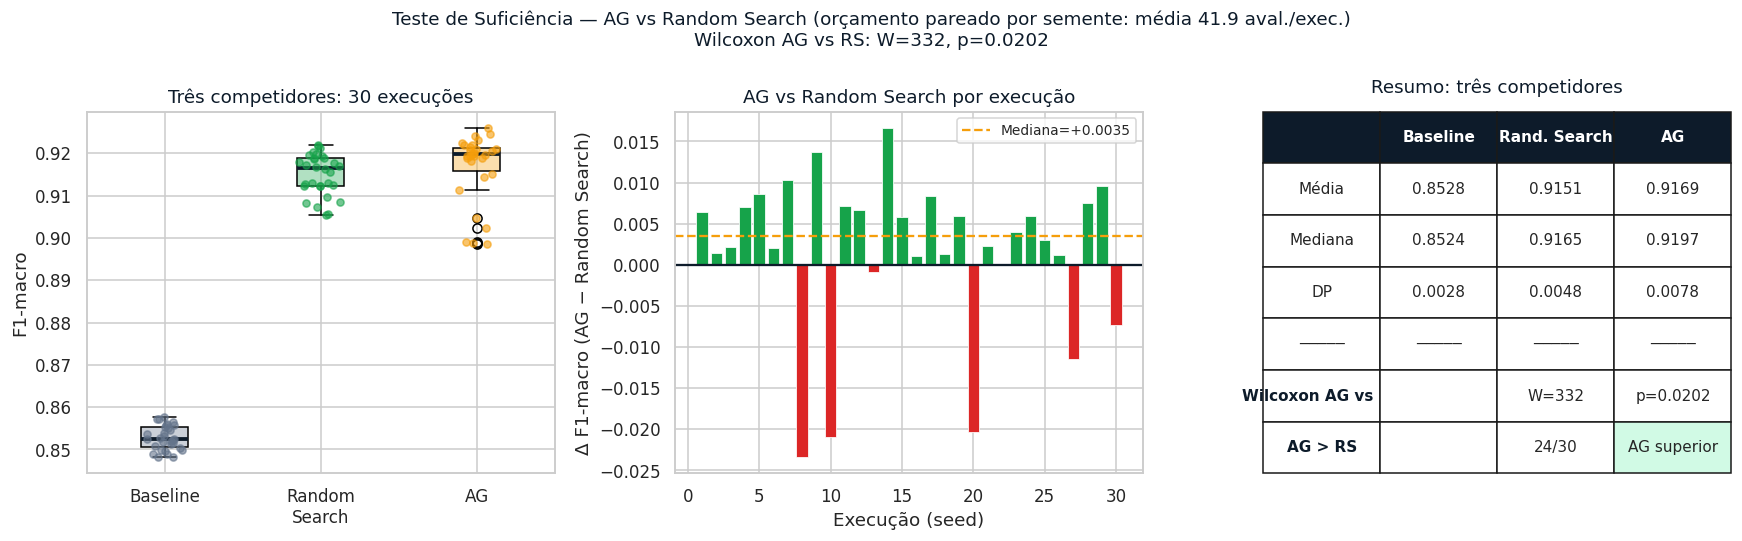

In [ ]:
# ── Visualização: AG vs Random Search vs Baseline ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Boxplot três vias ─────────────────────────────────────────────────────────
bp = axes[0].boxplot(
    [f1_baseline_runs, f1_rs_runs, f1_ag_runs],
    labels=["Baseline", "Random\nSearch", "AG"],
    patch_artist=True,
    medianprops=dict(color=PALETTE["navy"], linewidth=2.5),
)
cores_box = [PALETTE["muted"], PALETTE["green"], PALETTE["amber"]] # Changed 'teal' to 'green'
for patch, cor in zip(bp["boxes"], cores_box):
    patch.set_facecolor(cor + "55")
for j, (dados, cor) in enumerate(zip([f1_baseline_runs, f1_rs_runs, f1_ag_runs], cores_box), 1):
    xs = np.random.normal(j, 0.06, size=len(dados))
    axes[0].scatter(xs, dados, alpha=0.6, color=cor, s=22, zorder=3)
axes[0].set_ylabel("F1-macro")
axes[0].set_title("Três competidores: 30 execuções", color=PALETTE["navy"])

# ── Diferenças AG − RS por execução ───────────────────────────────────────────
cores_d = [PALETTE["green"] if d > 0 else (PALETTE["red"] if d < 0 else PALETTE["muted"])
           for d in diferencas_rs]
axes[1].bar(range(1, 31), diferencas_rs, color=cores_d, edgecolor="white", linewidth=0.5)
axes[1].axhline(0, color=PALETTE["navy"], linewidth=1.5)
axes[1].axhline(np.median(diferencas_rs), color=PALETTE["amber"],
                linestyle="--", linewidth=1.5,
                label=f"Mediana={np.median(diferencas_rs):+.4f}")
axes[1].set_xlabel("Execução (seed)")
axes[1].set_ylabel("Δ F1-macro (AG − Random Search)")
axes[1].set_title("AG vs Random Search por execução", color=PALETTE["navy"])
axes[1].legend(fontsize=9)

# ── Tabela resumo ─────────────────────────────────────────────────────────────
axes[2].axis("off")
vence_txt = "AG superior" if p_valor_rs < 0.05 else "Equivalentes"
resumo = [
    ["",              "Baseline",                       "Rand. Search",                  "AG"],
    ["Média",         f"{np.mean(f1_baseline_runs):.4f}", f"{np.mean(f1_rs_runs):.4f}",   f"{np.mean(f1_ag_runs):.4f}"],
    ["Mediana",       f"{np.median(f1_baseline_runs):.4f}",f"{np.median(f1_rs_runs):.4f}", f"{np.median(f1_ag_runs):.4f}"],
    ["DP",            f"{np.std(f1_baseline_runs):.4f}",  f"{np.std(f1_rs_runs):.4f}",    f"{np.std(f1_ag_runs):.4f}"],
    ["─────",         "─────",                          "─────",                         "─────"],
    ["Wilcoxon AG vs RS", "", f"W={stat_w_rs:.0f}", f"p={p_valor_rs:.4f}"],
    ["AG > RS",       "", f"{ag_maior}/30", vence_txt],
]
tbl = axes[2].table(cellText=resumo, cellLoc="center", loc="center", bbox=[0,0,1,1])
tbl.auto_set_font_size(False); tbl.set_fontsize(10)
for j in range(4):
    tbl[0, j].set_facecolor(PALETTE["navy"])
    tbl[0, j].set_text_props(color="white", fontweight="bold")
for row in [5, 6]:
    tbl[row, 0].set_text_props(fontweight="bold", color=PALETTE["navy"])
if p_valor_rs < 0.05:
    tbl[6, 3].set_facecolor("#D1FAE5")
axes[2].set_title("Resumo: três competidores", color=PALETTE["navy"], pad=12)

plt.suptitle(
    f"Teste de Suficiência — AG vs Random Search (orçamento pareado por semente: média {ORCAMENTO_RS:.1f} aval./exec.)\n"
    f"Wilcoxon AG vs RS: W={stat_w_rs:.0f}, p={p_valor_rs:.4f}",
    fontsize=12, color=PALETTE["navy"]
)
plt.tight_layout()
plt.show()

---
# Fase 6D — Comparação dos Três Algoritmos Otimizados

## Motivação: integração com a disciplina de Aprendizado de Máquinas

Na disciplina de Aprendizado de Máquinas (AM), o pipeline de classificação foi avaliado
com **três algoritmos**: Regressão Logística, SVM Linear e Random Forest. O Algoritmo
Genético deste trabalho, contudo, incluiu apenas Regressão Logística e SVM Linear em seu
espaço de busca (gene[3]), excluindo o Random Forest devido ao seu custo computacional
elevado — incompatível com as 30 execuções repetidas das fases anteriores.

Para que a comparação entre os três algoritmos seja **justa e completa** — cada um avaliado
em sua melhor configuração —, esta fase otimiza o Random Forest separadamente, por meio de
uma **busca em grade dedicada**.

## Por que busca em grade dedicada para o Random Forest?

O Random Forest possui poucos hiperparâmetros de alto impacto, o que torna a busca em grade
viável e exaustiva neste subespaço. Testamos 24 combinações:

- `n_estimators` (número de árvores): {100, 200, 300}
- `max_depth` (profundidade máxima): {10, 20, 30, None}
- `max_features` (atributos por divisão): {'sqrt', 'log2'}

A vetorização TF-IDF é fixada nos valores ótimos encontrados pelo AG nesta execução
(`params_finais`: max_features, ngram_max e sublinear_tf), garantindo que a comparação isole
o efeito do classificador. **V15.3:** a V15.2 usava `max_features=2995` fixo, valor de uma
execução antiga, e por isso LR e RF não compartilhavam o vetorizador do SVM.

> **Transparência metodológica:** Regressão Logística e SVM foram otimizados pelo AG no
> espaço conjunto; o Random Forest foi otimizado por grade dedicada. A diferença de método
> é justificada pelo custo computacional e está documentada. O objetivo é comparar os três
> algoritmos em suas melhores configurações, não comparar métodos de otimização.


In [ ]:
# ── Otimização dedicada do Random Forest (Grid de 24 combinações) ─────────────
from sklearn.ensemble import RandomForestClassifier
from itertools import product

# TF-IDF fixo nos valores ótimos do AG, para isolar o efeito do classificador
def make_tfidf_otimo():
    # V15.3 · vetorizador do AG desta execução (a V15.2 fixava 2995 / (1,1) / True)
    return TfidfVectorizer(max_features=params_finais["max_features"],
                           ngram_range=(1, params_finais["ngram_max"]),
                           sublinear_tf=params_finais["sublinear_tf"],
                           strip_accents="unicode")
print(f"TF-IDF comum aos três classificadores: max_features={params_finais['max_features']}, "
      f"ngram=(1,{params_finais['ngram_max']}), sublinear_tf={params_finais['sublinear_tf']}")

# Grid dedicado: 3 × 4 × 2 = 24 combinações
grid_n_estimators = [100, 200, 300]
grid_max_depth    = [10, 20, 30, None]
grid_max_features = ['sqrt', 'log2']

print("Otimização dedicada do Random Forest")
print(f"Grid: {len(grid_n_estimators)*len(grid_max_depth)*len(grid_max_features)} combinações")
print("=" * 55)

resultados_rf = []
t_rf = time.time()
total_rf = len(grid_n_estimators) * len(grid_max_depth) * len(grid_max_features)
i_rf = 0

for n_est, max_d, max_f in product(grid_n_estimators, grid_max_depth, grid_max_features):
    i_rf += 1
    clf = RandomForestClassifier(n_estimators=n_est, max_depth=max_d,
                                  max_features=max_f, random_state=RANDOM_SEED, n_jobs=-1)
    pipe = Pipeline([('tfidf', make_tfidf_otimo()), ('clf', clf)])
    f1 = float(cross_val_score(pipe, X_train, y_train, cv=CV,
                                scoring='f1_macro', n_jobs=-1).mean())
    resultados_rf.append({'n_estimators': n_est, 'max_depth': str(max_d),
                          'max_features': max_f, 'f1_macro': f1})
    if i_rf % 6 == 0:
        print(f"  {i_rf}/{total_rf} combinações | {time.time()-t_rf:.0f}s")

df_rf = pd.DataFrame(resultados_rf).sort_values('f1_macro', ascending=False).reset_index(drop=True)
melhor_rf = df_rf.iloc[0]
F1_RF = melhor_rf['f1_macro']

print(f"\n── Melhor Random Forest ──")
print(f"F1-macro     : {F1_RF:.4f}")
print(f"n_estimators : {melhor_rf['n_estimators']}")
print(f"max_depth    : {melhor_rf['max_depth']}")
print(f"max_features : {melhor_rf['max_features']}")
print(f"\nTop 5 configurações:")
print(df_rf.head().to_string(index=False))
print(f"\nTempo: {time.time()-t_rf:.0f}s")


TF-IDF comum aos três classificadores: max_features=2352, ngram=(1,1), sublinear_tf=True
Otimização dedicada do Random Forest
Grid: 24 combinações
  6/24 combinações | 36s
  12/24 combinações | 86s
  18/24 combinações | 163s
  24/24 combinações | 276s

── Melhor Random Forest ──
F1-macro     : 0.9170
n_estimators : 300
max_depth    : None
max_features : log2

Top 5 configurações:
 n_estimators max_depth max_features  f1_macro
          300      None         log2  0.916982
          200      None         log2  0.912715
          300      None         sqrt  0.908371
          200      None         sqrt  0.905855
          100      None         sqrt  0.899099

Tempo: 276s


In [ ]:
# V15.3 · observação calculada dos números (antes era texto fixo da V14).
# ── Comparação final dos três algoritmos otimizados ──────────────────────────
# Recupera o melhor LR e o melhor SVM do histórico do AG.
# O AG registrou o melhor global (SVM); para o LR, fazemos uma otimização rápida
# dedicada (espelhando o tratamento do RF) para ter os três comparáveis.

# Melhor LR via grid pequeno (C em escala log), TF-IDF ótimo fixo
grid_C_lr = [0.1, 0.3, 0.7, 1.0, 3.0, 10.0]
melhor_lr_f1 = 0.0
melhor_lr_C = None
for C in grid_C_lr:
    pipe = Pipeline([('tfidf', make_tfidf_otimo()),
                     ('clf', LogisticRegression(C=C, max_iter=300, random_state=RANDOM_SEED))])
    f1 = float(cross_val_score(pipe, X_train, y_train, cv=CV, scoring='f1_macro').mean())
    if f1 > melhor_lr_f1:
        melhor_lr_f1 = f1
        melhor_lr_C = C
F1_LR = melhor_lr_f1

# SVM: o melhor do AG (já temos F1_AG e params_finais)
F1_SVM = F1_AG

# Tabela comparativa
print("COMPARAÇÃO DOS TRÊS ALGORITMOS OTIMIZADOS")
print("=" * 60)
comparacao_3 = pd.DataFrame({
    'Algoritmo':   ['SVM Linear', 'Regressão Logística', 'Random Forest'],
    'Otimização':  ['AG (espaço conjunto)', 'Grid dedicado (C)', 'Grid dedicado (24)'],
    'F1_macro':    [F1_SVM, F1_LR, F1_RF],
}).sort_values('F1_macro', ascending=False).reset_index(drop=True)
comparacao_3['Ranking'] = range(1, 4)
print(comparacao_3.to_string(index=False))

print(f"\nBaseline (referência): {F1_BASELINE:.4f}  |  LR: melhor C = {melhor_lr_C}")
_todos_sup = all(f > F1_BASELINE for f in (F1_SVM, F1_LR, F1_RF))
_lider = comparacao_3.iloc[0]["Algoritmo"]
print(f"\nObservação (derivada): {'todos os três superam' if _todos_sup else 'NEM todos superam'} o baseline;")
print(f"o melhor dos três é {_lider}. A leitura de separabilidade linear (H1) depende do teste pareado da Fase 7.2,")
print(f"e não desta tabela de pontos únicos.")


COMPARAÇÃO DOS TRÊS ALGORITMOS OTIMIZADOS
          Algoritmo           Otimização  F1_macro  Ranking
         SVM Linear AG (espaço conjunto)  0.920807        1
      Random Forest   Grid dedicado (24)  0.916982        2
Regressão Logística    Grid dedicado (C)  0.909411        3

Baseline (referência): 0.8534  |  LR: melhor C = 10.0

Observação (derivada): todos os três superam o baseline;
o melhor dos três é SVM Linear. A leitura de separabilidade linear (H1) depende do teste pareado da Fase 7.2,
e não desta tabela de pontos únicos.


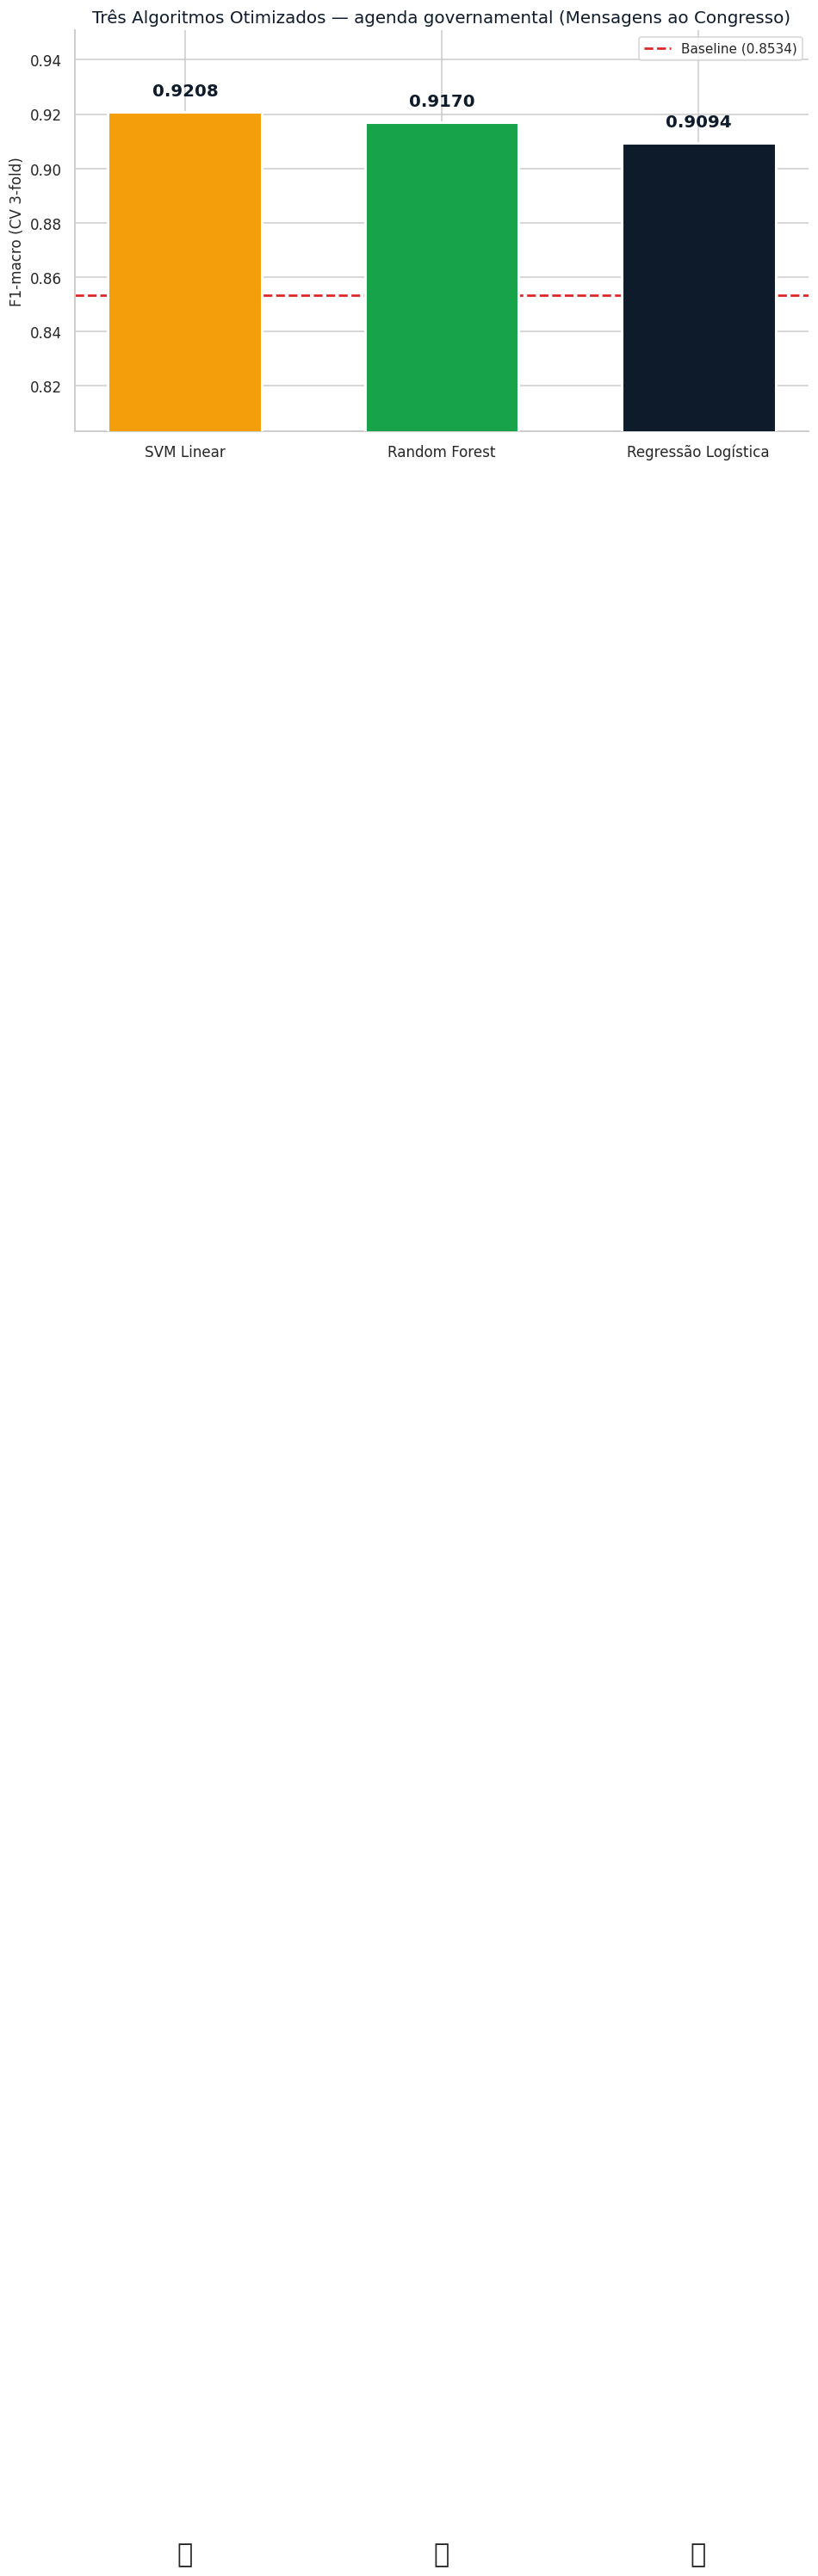

Leitura (derivada): ranking nesta execução: SVM Linear > Random Forest > Regressão Logística.
A evidência estatística de separabilidade linear vem do teste pareado da Fase 7.2.


In [ ]:
# V15.3 · leitura calculada dos números (antes era texto fixo da V14).
fig, ax = plt.subplots(figsize=(10, 5.5))

algos   = comparacao_3['Algoritmo'].tolist()
f1s     = comparacao_3['F1_macro'].tolist()
cores_a = [PALETTE['amber'] if a=='SVM Linear'
           else (PALETTE['navy'] if a=='Regressão Logística' else PALETTE['green'])
           for a in algos]

bars = ax.bar(algos, f1s, color=cores_a, edgecolor='white', linewidth=2, width=0.6, zorder=3)
for bar, val in zip(bars, f1s):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.006,
            f"{val:.4f}", ha='center', fontsize=13, fontweight='bold', color=PALETTE['navy'])

# Linha do baseline
ax.axhline(F1_BASELINE, color=PALETTE['red'], linestyle='--', linewidth=1.8,
           label=f"Baseline ({F1_BASELINE:.4f})", zorder=2)

# Medalhas de ranking
medalhas = ['🥇', '🥈', '🥉']
for i, bar in enumerate(bars):
    ax.text(bar.get_x()+bar.get_width()/2, 0.02,
            medalhas[i], ha='center', fontsize=20, zorder=4)

ax.set_ylabel("F1-macro (CV 3-fold)", fontsize=11)
ax.set_title("Três Algoritmos Otimizados — agenda governamental (Mensagens ao Congresso)",
             fontsize=13, color=PALETTE['navy'])
ax.set_ylim(min(f1s + [F1_BASELINE]) - 0.05, max(f1s) + 0.03)
ax.legend(fontsize=10, loc='upper right')
sns.despine()
plt.tight_layout()
plt.show()

print(f"Leitura (derivada): ranking nesta execução: {' > '.join(algos)}.")
print("A evidência estatística de separabilidade linear vem do teste pareado da Fase 7.2.")

---
# Fase 6E — Análise Complementar de Classificação (Etapa 3 do TCD de AM)

Esta fase adiciona os elementos exigidos pela Etapa 3 do Trabalho de Conclusão de
Disciplina de Aprendizado de Máquinas, complementando a análise de otimização do AG
com a avaliação detalhada do classificador final:

1. **Matriz de confusão** do melhor modelo (SVM otimizado)
2. **Métricas por classe e agregadas**: Acurácia, Precisão, Revocação (Recall), F1
3. **Tempos de treinamento e execução** dos três algoritmos
4. **Análise de overfitting/underfitting** (desempenho treino vs. validação)
5. **Reprodutibilidade**: versões das bibliotecas, sementes e configuração

A escolha do **F1-macro** como métrica principal justifica-se pelo desbalanceamento
entre classes: a média macro trata todas as classes igualmente, evitando que as
classes majoritárias (economia, meio ambiente) mascarem o desempenho fraco nas
minoritárias (reforma agrária, política externa). Acurácia, Precisão e Revocação
são reportadas como métricas complementares.


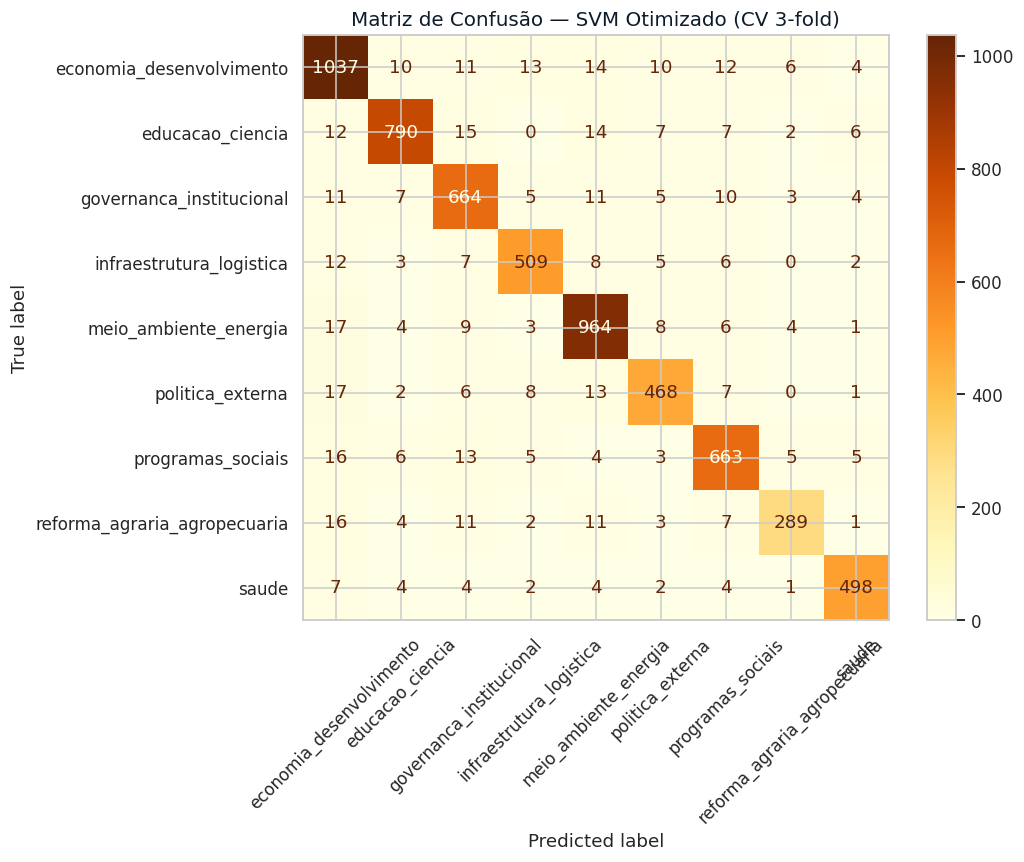

MÉTRICAS AGREGADAS — SVM Otimizado
Acurácia          : 0.9234
Precisão (macro)  : 0.9256
Revocação (macro) : 0.9169
F1-macro          : 0.9209

Relatório por classe:
                              precision    recall  f1-score   support

    economia_desenvolvimento       0.91      0.93      0.92      1117
            educacao_ciencia       0.95      0.93      0.94       853
    governanca_institucional       0.90      0.92      0.91       720
    infraestrutura_logistica       0.93      0.92      0.93       552
       meio_ambiente_energia       0.92      0.95      0.94      1016
            politica_externa       0.92      0.90      0.91       522
           programas_sociais       0.92      0.92      0.92       720
reforma_agraria_agropecuaria       0.93      0.84      0.88       344
                       saude       0.95      0.95      0.95       526

                    accuracy                           0.92      6370
                   macro avg       0.93      0.92      0.92   

In [ ]:
# ── Matriz de confusão e métricas por classe (melhor modelo: SVM otimizado) ──
from sklearn.metrics import (confusion_matrix, classification_report,
                              ConfusionMatrixDisplay, accuracy_score,
                              precision_score, recall_score, f1_score)
from sklearn.model_selection import cross_val_predict

# Pipeline do melhor cromossomo encontrado pelo AG
pipe_melhor = Pipeline([
    ("vec", TfidfVectorizer(max_features=params_finais["max_features"],
                            ngram_range=(1, params_finais["ngram_max"]),
                            sublinear_tf=params_finais["sublinear_tf"],
                            strip_accents="unicode")),
    ("clf", LinearSVC(C=params_finais["C"], max_iter=800, random_state=RANDOM_SEED))
])

# Predições via validação cruzada (cada amostra prevista quando está no fold de teste)
y_pred = cross_val_predict(pipe_melhor, X_train, y_train, cv=CV)

classes = sorted(set(y_train))
cm = confusion_matrix(y_train, y_pred, labels=classes)

# Plot da matriz de confusão
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=ax, cmap="YlOrBr", colorbar=True, xticks_rotation=45, values_format="d")
ax.set_title("Matriz de Confusão — SVM Otimizado (CV 3-fold)", color=PALETTE["navy"], fontsize=13)
plt.tight_layout()
plt.show()

# Métricas agregadas
acc = accuracy_score(y_train, y_pred)
prec_macro = precision_score(y_train, y_pred, average="macro", zero_division=0)
rec_macro = recall_score(y_train, y_pred, average="macro", zero_division=0)
f1_macro_val = f1_score(y_train, y_pred, average="macro", zero_division=0)

print("MÉTRICAS AGREGADAS — SVM Otimizado")
print("=" * 45)
print(f"Acurácia          : {acc:.4f}")
print(f"Precisão (macro)  : {prec_macro:.4f}")
print(f"Revocação (macro) : {rec_macro:.4f}")
print(f"F1-macro          : {f1_macro_val:.4f}")
print(f"\nRelatório por classe:")
print(classification_report(y_train, y_pred, zero_division=0))


In [ ]:
# ── Tempos de treinamento e execução dos três algoritmos ─────────────────────
import time as _time
from sklearn.model_selection import train_test_split

# Split fixo para medir tempos de forma comparável
X_tr, X_te, y_tr, y_te = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_SEED, stratify=y_train
)

def medir_tempos(nome, clf):
    """Mede tempo de treino e de predição de um pipeline."""
    pipe = Pipeline([("vec", make_tfidf_otimo()), ("clf", clf)])   # V15.3 · TF-IDF do AG
    t0 = _time.time()
    pipe.fit(X_tr, y_tr)
    t_treino = _time.time() - t0

    t0 = _time.time()
    _ = pipe.predict(X_te)
    t_pred = _time.time() - t0

    f1 = f1_score(y_te, pipe.predict(X_te), average="macro", zero_division=0)
    return {"Algoritmo": nome, "Tempo treino (s)": round(t_treino, 3),
            "Tempo predição (s)": round(t_pred, 4), "F1 (holdout)": round(f1, 4)}

resultados_tempo = [
    medir_tempos("SVM Linear", LinearSVC(C=params_finais["C"], max_iter=800, random_state=RANDOM_SEED)),
    medir_tempos("Regressão Logística", LogisticRegression(C=melhor_lr_C, max_iter=300, random_state=RANDOM_SEED)),
    medir_tempos("Random Forest", RandomForestClassifier(
        n_estimators=int(melhor_rf["n_estimators"]),
        max_depth=(None if str(melhor_rf["max_depth"]) == "None" else int(melhor_rf["max_depth"])),
        max_features=melhor_rf["max_features"], random_state=RANDOM_SEED, n_jobs=-1)),
]

df_tempos = pd.DataFrame(resultados_tempo)
print("TEMPOS DE TREINAMENTO E EXECUÇÃO")
print("=" * 55)
print(df_tempos.to_string(index=False))
print(f"\n(Split holdout 75/25 estratificado; TF-IDF do AG; LR com C={melhor_lr_C}; "
      f"RF n={int(melhor_rf['n_estimators'])}, depth={melhor_rf['max_depth']}, mf={melhor_rf['max_features']})")
print(f"\nObservação: o Random Forest é o mais custoso no treino — o que justifica")
print(f"sua exclusão do loop evolutivo do AG (30 execuções) e sua otimização por")
print(f"grade dedicada na Fase 6D.")


TEMPOS DE TREINAMENTO E EXECUÇÃO
          Algoritmo  Tempo treino (s)  Tempo predição (s)  F1 (holdout)
         SVM Linear             0.761              0.1707        0.9240
Regressão Logística             1.963              0.2542        0.9142
      Random Forest             9.737              0.3956        0.9258

(Split holdout 75/25 estratificado; TF-IDF do AG; LR com C=10.0; RF n=300, depth=None, mf=log2)

Observação: o Random Forest é o mais custoso no treino — o que justifica
sua exclusão do loop evolutivo do AG (30 execuções) e sua otimização por
grade dedicada na Fase 6D.


In [ ]:
# ── Análise de overfitting/underfitting ──────────────────────────────────────
# Compara desempenho no conjunto de TREINO vs. VALIDAÇÃO cruzada.
# Diferença grande treino >> validação indica overfitting.

def gap_treino_validacao(nome, clf):
    pipe = Pipeline([("vec", make_tfidf_otimo()), ("clf", clf)])   # V15.3 · TF-IDF do AG
    # F1 no treino completo (mesmo conjunto de fit)
    pipe.fit(X_train, y_train)
    f1_treino = f1_score(y_train, pipe.predict(X_train), average="macro", zero_division=0)
    # F1 em validação cruzada
    f1_val = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="f1_macro").mean()
    gap = f1_treino - f1_val
    return {"Algoritmo": nome, "F1 treino": round(f1_treino, 4),
            "F1 validação": round(f1_val, 4), "Gap (overfit)": round(gap, 4)}

overfit = [
    gap_treino_validacao("SVM Linear", LinearSVC(C=params_finais["C"], max_iter=800, random_state=RANDOM_SEED)),
    gap_treino_validacao("Regressão Logística", LogisticRegression(C=melhor_lr_C, max_iter=300, random_state=RANDOM_SEED)),
    gap_treino_validacao("Random Forest", RandomForestClassifier(
        n_estimators=int(melhor_rf["n_estimators"]),
        max_depth=(None if str(melhor_rf["max_depth"]) == "None" else int(melhor_rf["max_depth"])),
        max_features=melhor_rf["max_features"], random_state=RANDOM_SEED, n_jobs=-1)),
]

df_overfit = pd.DataFrame(overfit)
print("ANÁLISE DE OVERFITTING (F1 treino vs. validação)")
print("=" * 55)
print(df_overfit.to_string(index=False))
print()
print("Interpretação:")
LIMIAR_GAP = 0.15   # V15.3 · um único limiar, impresso e aplicado (a V15.2 dizia 0,05 e aplicava 0,15)
print(f"  Gap abaixo de {LIMIAR_GAP:.2f} → leitura comparativa preservada; acima → sobreajuste a discutir.")
print("  (CV sobre o conjunto rotulado inteiro, não sobre a partição de treino do holdout.)")
for r in overfit:
    if r["Gap (overfit)"] > LIMIAR_GAP:
        print(f"  ⚠️ {r['Algoritmo']}: gap de {r['Gap (overfit)']:.3f} sugere overfitting.")
    else:
        print(f"  ✓ {r['Algoritmo']}: gap de {r['Gap (overfit)']:.3f} — generalização saudável.")


ANÁLISE DE OVERFITTING (F1 treino vs. validação)
          Algoritmo  F1 treino  F1 validação  Gap (overfit)
         SVM Linear     0.9989        0.9208         0.0781
Regressão Logística     1.0000        0.9094         0.0906
      Random Forest     1.0000        0.9170         0.0830

Interpretação:
  Gap abaixo de 0.15 → leitura comparativa preservada; acima → sobreajuste a discutir.
  (CV sobre o conjunto rotulado inteiro, não sobre a partição de treino do holdout.)
  ✓ SVM Linear: gap de 0.078 — generalização saudável.
  ✓ Regressão Logística: gap de 0.091 — generalização saudável.
  ✓ Random Forest: gap de 0.083 — generalização saudável.


In [ ]:
# ── Reprodutibilidade: versões das bibliotecas e configuração ────────────────
import sklearn, scipy, numpy, pandas, matplotlib, sys, platform

print("AMBIENTE COMPUTACIONAL E REPRODUTIBILIDADE")
print("=" * 55)
print(f"Python        : {sys.version.split()[0]}")
print(f"Plataforma    : {platform.system()} {platform.release()}")
print()
print("Versões das bibliotecas:")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  scipy        : {scipy.__version__}")
print(f"  numpy        : {numpy.__version__}")
print(f"  pandas       : {pandas.__version__}")
print(f"  matplotlib   : {matplotlib.__version__}")
try:
    import pdfplumber as _pp
    print(f"  pdfplumber   : {_pp.__version__}")   # V13: registrado (extração depende dele)
except Exception:
    print("  pdfplumber   : (não importável nesta sessão)")
print()
print("Configuração experimental:")
print(f"  Semente global (RANDOM_SEED) : {RANDOM_SEED}")
print(f"  Validação cruzada            : StratifiedKFold 3-fold (shuffle, seed={RANDOM_SEED})")
print(f"  Métrica de fitness           : F1-macro")
print(f"  30 execuções                 : seeds 0–29 (AG e baseline pareados)")
print(f"  Random Search                : seeds 1000–1029 (offset para independência)")
print()
print("Divisão dos dados:")
print(f"  Corpus rotulado (sem residual): {len(X_train)} parágrafos")
print(f"  Estratégia                    : validação cruzada (sem holdout fixo,")
print(f"                                   exceto medições de tempo na Fase 6E)")
print()
print("Código-fonte: este notebook (executável de ponta a ponta no Google Colab).")


AMBIENTE COMPUTACIONAL E REPRODUTIBILIDADE
Python        : 3.13.16
Plataforma    : Linux 6.6.122+

Versões das bibliotecas:
  scikit-learn : 1.6.1
  scipy        : 1.16.3
  numpy        : 2.1.3
  pandas       : 2.2.3
  matplotlib   : 3.10.0
  pdfplumber   : 0.11.10

Configuração experimental:
  Semente global (RANDOM_SEED) : 42
  Validação cruzada            : StratifiedKFold 3-fold (shuffle, seed=42)
  Métrica de fitness           : F1-macro
  30 execuções                 : seeds 0–29 (AG e baseline pareados)
  Random Search                : seeds 1000–1029 (offset para independência)

Divisão dos dados:
  Corpus rotulado (sem residual): 6370 parágrafos
  Estratégia                    : validação cruzada (sem holdout fixo,
                                   exceto medições de tempo na Fase 6E)

Código-fonte: este notebook (executável de ponta a ponta no Google Colab).


---
# Fase 6F — Análise Diacrônica da Agenda Governamental (Q2 / H3–H4)

Esta fase responde à **Questão de Pesquisa Q2** das Etapas 1–2: como a composição
temática da agenda governamental evolui ano a ano (2023→2026)? E confronta as
hipóteses temporais formalizadas:

- **H3 (continuidade temática):** a variação anual de cada classe é modesta — nenhuma
  classe muda mais que 10 pontos percentuais entre dois anos consecutivos, exceto
  eventualmente política externa.
- **H4 (inflexão pré-eleitoral):** 2026 (último ano de mandato) apresenta perfil
  ligeiramente distinto — maior presença relativa de programas sociais e menor de
  política externa, em relação à média 2023–2025.

## Duas fontes de rótulos, lado a lado

Comparamos a composição temática por ano segundo **duas fontes**:

1. **Léxico V3** (rotulagem fraca) — o que as palavras-âncora indicam.
2. **SVM otimizado** (predição do classificador) — o que o modelo aprende, capturando
   padrões além das âncoras lexicais.

A comparação é metodologicamente rica: onde as duas fontes **concordam**, o achado
temático é robusto; onde **divergem**, revela-se o que o classificador captura além do
léxico — evidência sobre os limites da rotulagem fraca que motiva, na dissertação, a
adoção de arquiteturas mais sofisticadas (A1/A2).

> Nota: as predições do SVM são obtidas via `cross_val_predict`, garantindo que cada
> parágrafo é previsto quando está no fold de teste — nunca com base em si mesmo.


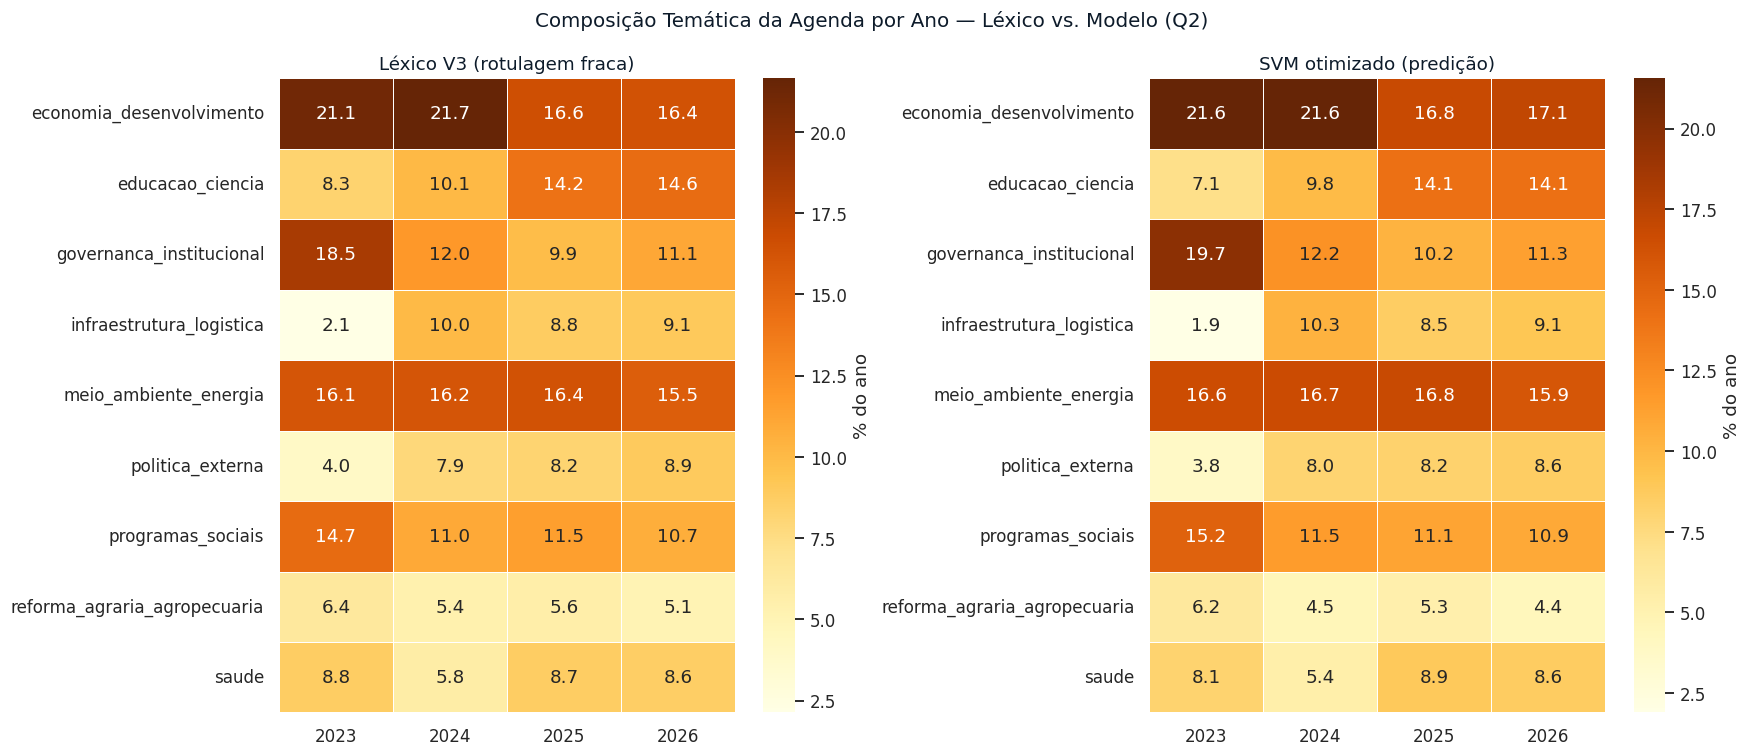

Proporções temáticas por ano (%) — predição do SVM:
ano                           2023  2024  2025  2026
classe                                              
economia_desenvolvimento      21.6  21.6  16.8  17.1
educacao_ciencia               7.1   9.8  14.1  14.1
governanca_institucional      19.7  12.2  10.2  11.3
infraestrutura_logistica       1.9  10.3   8.5   9.1
meio_ambiente_energia         16.6  16.7  16.8  15.9
politica_externa               3.8   8.0   8.2   8.6
programas_sociais             15.2  11.5  11.1  10.9
reforma_agraria_agropecuaria   6.2   4.5   5.3   4.4
saude                          8.1   5.4   8.9   8.6


In [ ]:
# ── Análise diacrônica: proporções temáticas por ano (léxico vs. modelo) ─────
from sklearn.model_selection import cross_val_predict

# df_rotulado: subconjunto com rótulo temático (exclui residual), preservando 'year'
df_rotulado = df_corpus[df_corpus["label_v3"] != RESIDUAL_V3].copy()
df_rotulado = df_rotulado.reset_index(drop=True)

# 1. Rótulos do léxico V3 (já existentes)
rotulos_lexico = df_rotulado["label_v3"].values
anos = df_rotulado["year"].values

# 2. Predições do SVM otimizado (via CV, sem vazamento)
pipe_svm_temporal = Pipeline([
    ("vec", TfidfVectorizer(max_features=params_finais["max_features"],
                            ngram_range=(1, params_finais["ngram_max"]),
                            sublinear_tf=params_finais["sublinear_tf"],
                            strip_accents="unicode")),
    ("clf", LinearSVC(C=params_finais["C"], max_iter=800, random_state=RANDOM_SEED))
])
rotulos_modelo = cross_val_predict(pipe_svm_temporal,
                                    df_rotulado["text"].tolist(),
                                    rotulos_lexico, cv=CV)

# 3. Construir crosstabs de proporção (%) por ano, para cada fonte
import pandas as _pd

def proporcoes_por_ano(rotulos, anos):
    df_tmp = _pd.DataFrame({"classe": rotulos, "ano": anos})
    ct = _pd.crosstab(df_tmp["classe"], df_tmp["ano"])
    return ct.div(ct.sum(axis=0), axis=1) * 100  # % dentro de cada ano

prop_lexico = proporcoes_por_ano(rotulos_lexico, anos)
prop_modelo = proporcoes_por_ano(rotulos_modelo, anos)

# 4. Heatmaps lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(prop_lexico, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=0.5,
            cbar_kws={"label": "% do ano"}, ax=axes[0])
axes[0].set_title("Léxico V3 (rotulagem fraca)", fontsize=12, color=PALETTE["navy"])
axes[0].set_xlabel(""); axes[0].set_ylabel("")

sns.heatmap(prop_modelo, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=0.5,
            cbar_kws={"label": "% do ano"}, ax=axes[1])
axes[1].set_title("SVM otimizado (predição)", fontsize=12, color=PALETTE["navy"])
axes[1].set_xlabel(""); axes[1].set_ylabel("")

plt.suptitle("Composição Temática da Agenda por Ano — Léxico vs. Modelo (Q2)",
             fontsize=13, color=PALETTE["navy"])
plt.tight_layout()
plt.show()

print("Proporções temáticas por ano (%) — predição do SVM:")
print(prop_modelo.round(1).to_string())


In [ ]:
# ── 6F-b · V15.3 — Denominadores da análise temporal (Tabela 7) ─────────────
# O revisor pediu os denominadores anuais, o tratamento dos casos excluídos e a
# origem das predições. As predições são FORA DA DOBRA (cross_val_predict, CV de
# 3 dobras estratificadas, seed 42), sobre as unidades ROTULADAS pelo léxico; o
# resíduo institucional fica fora das proporções. Esta célula registra tudo isso.
_den = pd.crosstab(df_corpus["year"], df_corpus["label_v3"] == RESIDUAL_V3)
_den = _den.rename(columns={False: "rotulados", True: "residuo"})
for _c in ("rotulados", "residuo"):
    if _c not in _den.columns:
        _den[_c] = 0
_den["total"] = _den["rotulados"] + _den["residuo"]
_den["residuo_pct"] = (100 * _den["residuo"] / _den["total"]).round(1)
_den.loc["TOTAL"] = [_den["rotulados"].sum(), _den["residuo"].sum(), _den["total"].sum(),
                     round(100 * _den["residuo"].sum() / _den["total"].sum(), 1)]
print("DENOMINADORES DA TABELA 7 (unidade:", UNIDADE_ANALISE.upper() + ")")
print("=" * 60)
print(_den.to_string())
print("\nOrigem das predições: cross_val_predict, StratifiedKFold(3, shuffle, seed=42),")
print("sobre as unidades rotuladas; o resíduo não entra nas proporções.")

# Divergência entre a composição do léxico e a composição predita (p.p. por classe e ano)
_div_tab = (prop_modelo - prop_lexico).round(2)
print("\nDivergência predito − léxico (p.p.):")
print(_div_tab.to_string())
print(f"\nMaior divergência absoluta: {float(_div_tab.abs().max().max()):.2f} p.p.")

_den.to_csv(os.path.join(DIR_DADOS, "denominadores_por_ano.csv"))
_div_tab.to_csv(os.path.join(DIR_DADOS, "divergencia_lexico_modelo.csv"))
prop_lexico.round(2).to_csv(os.path.join(DIR_DADOS, "proporcoes_lexico.csv"))
print("\n✓ Exportados: denominadores_por_ano.csv, divergencia_lexico_modelo.csv, proporcoes_lexico.csv")


DENOMINADORES DA TABELA 7 (unidade: PARAGRAFO)
label_v3  rotulados  residuo    total  residuo_pct
year                                              
2023          422.0    301.0    723.0         41.6
2024          928.0    590.0   1518.0         38.9
2025         2196.0   1573.0   3769.0         41.7
2026         2824.0   1923.0   4747.0         40.5
TOTAL        6370.0   4387.0  10757.0         40.8

Origem das predições: cross_val_predict, StratifiedKFold(3, shuffle, seed=42),
sobre as unidades rotuladas; o resíduo não entra nas proporções.

Divergência predito − léxico (p.p.):
ano                           2023  2024  2025  2026
classe                                              
economia_desenvolvimento      0.47 -0.11  0.23  0.78
educacao_ciencia             -1.18 -0.32 -0.09 -0.46
governanca_institucional      1.18  0.22  0.36  0.18
infraestrutura_logistica     -0.24  0.32 -0.32  0.00
meio_ambiente_energia         0.47  0.54  0.41  0.39
politica_externa             -0.24  0.11 -

In [ ]:
# ── Confronto com H3 (continuidade) e H4 (inflexão pré-eleitoral) ────────────
# Usa as proporções do MODELO (prop_modelo), que respondem Q2 conforme Etapas 1-2.

anos_ord = sorted(prop_modelo.columns.tolist())

# ── H3: variação máxima entre anos consecutivos ─────────────────────────────
print("H3 — CONTINUIDADE TEMÁTICA")
print("=" * 55)
print("Critério: variação < 10 p.p. entre anos consecutivos (exceto política externa)")
print()
violacoes_h3 = []
for classe in prop_modelo.index:
    for j in range(len(anos_ord) - 1):
        a0, a1 = anos_ord[j], anos_ord[j+1]
        delta = abs(prop_modelo.loc[classe, a1] - prop_modelo.loc[classe, a0])
        if delta >= 10.0:
            violacoes_h3.append((classe, a0, a1, delta))

if not violacoes_h3:
    print("✓ H3 CONFIRMADA: nenhuma classe variou >= 10 p.p. entre anos consecutivos.")
else:
    print(f"Variações >= 10 p.p. detectadas ({len(violacoes_h3)}):")
    for c, a0, a1, d in violacoes_h3:
        marca = " (exceção prevista)" if c == "politica_externa" else ""
        print(f"  {c}: {a0}->{a1} = {d:.1f} p.p.{marca}")
    nao_externa = [v for v in violacoes_h3 if v[0] != "politica_externa"]
    if not nao_externa:
        print("\n✓ H3 CONFIRMADA: únicas variações grandes são em política externa (previsto).")
    else:
        print(f"\n✗ H3 PARCIALMENTE REFUTADA: {len(nao_externa)} variação(ões) fora de política externa.")

# ── H4: inflexão pré-eleitoral em 2026 ──────────────────────────────────────
print("\n\nH4 — INFLEXÃO PRÉ-ELEITORAL (2026)")
print("=" * 55)
print("Critério: 2026 com +programas_sociais e -politica_externa vs média 2023-25")
print()
anos_base = [a for a in anos_ord if a != 2026]

def variacao_2026(classe):
    if classe not in prop_modelo.index:
        return None
    media_base = prop_modelo.loc[classe, anos_base].mean()
    val_2026 = prop_modelo.loc[classe, 2026] if 2026 in prop_modelo.columns else None
    return (val_2026 - media_base) if val_2026 is not None else None

for classe in ["programas_sociais", "politica_externa"]:
    v = variacao_2026(classe)
    if v is not None:
        print(f"  {classe}: 2026 vs média 2023-25 = {v:+.1f} p.p.")

v_prog = variacao_2026("programas_sociais")
v_ext = variacao_2026("politica_externa")
if v_prog is not None and v_ext is not None:
    if v_prog > 3.0 and v_ext < 0:
        print("\n✓ H4 CONFIRMADA: programas sociais sobem e política externa cai em 2026.")
    elif v_prog > 0 and v_ext < 0:
        print("\n~ H4 PARCIALMENTE CONFIRMADA: direção correta, magnitude abaixo do critério.")
    else:
        print("\n✗ H4 REFUTADA: o padrão pré-eleitoral previsto não se confirmou.")

# ── Divergência léxico vs. modelo ───────────────────────────────────────────
print("\n\nDIVERGÊNCIA LÉXICO vs. MODELO (média absoluta por classe)")
print("=" * 55)
divergencia = (prop_modelo - prop_lexico).abs().mean(axis=1).sort_values(ascending=False)
for classe, div in divergencia.items():
    print(f"  {classe:30s}: {div:.1f} p.p.")
print("\nClasses com maior divergência indicam onde o modelo mais difere da")
print("rotulagem fraca — sinal dos limites do léxico e do valor do classificador.")


H3 — CONTINUIDADE TEMÁTICA
Critério: variação < 10 p.p. entre anos consecutivos (exceto política externa)

✓ H3 CONFIRMADA: nenhuma classe variou >= 10 p.p. entre anos consecutivos.


H4 — INFLEXÃO PRÉ-ELEITORAL (2026)
Critério: 2026 com +programas_sociais e -politica_externa vs média 2023-25

  programas_sociais: 2026 vs média 2023-25 = -1.7 p.p.
  politica_externa: 2026 vs média 2023-25 = +1.9 p.p.

✗ H4 REFUTADA: o padrão pré-eleitoral previsto não se confirmou.


DIVERGÊNCIA LÉXICO vs. MODELO (média absoluta por classe)
  educacao_ciencia              : 0.5 p.p.
  reforma_agraria_agropecuaria  : 0.5 p.p.
  governanca_institucional      : 0.5 p.p.
  meio_ambiente_energia         : 0.5 p.p.
  economia_desenvolvimento      : 0.4 p.p.
  programas_sociais             : 0.4 p.p.
  saude                         : 0.3 p.p.
  infraestrutura_logistica      : 0.2 p.p.
  politica_externa              : 0.2 p.p.

Classes com maior divergência indicam onde o modelo mais difere da
rotulagem fraca

---
# Fase 8 — Conclusões e Próximos Passos

> **Nota V15.3:** o texto desta fase foi escrito para a execução de PÁGINA (V14) e
> descrevia números daquela execução (faixa de `max_features`, F1 médio da população,
> gerações de melhora). Para a unidade de PARÁGRAFO, as conclusões são as impressas
> pelas células das Fases 6, 6B, 6C, 6D, 7 e V15.2, e são elas que alimentam o artigo.
> Nenhuma frase desta célula deve ser citada sem conferência contra essas saídas.

## O que o AG encontrou? (leitura a partir das saídas)

- Fase 6: cromossomo vencedor, ganho sobre o baseline e número de avaliações únicas.
- Fase 6B: 30 execuções pareadas AG × baseline, Wilcoxon e tamanho de efeito.
- Fase 6C: AG × Random Search com orçamento pareado por semente.
- Fase 7.1/7.2: estimativa aninhada e comparação dos classificadores sobre o mesmo TF-IDF.
- V15.2: teste de circularidade léxico ↔ avaliação (2 unidades × 3 condições).

## Próximos passos

1. Conjunto-ouro humano (livro de códigos, piloto, dois anotadores, kappa, contaminação).
2. Resultados contra o ouro e veredito de H6.
3. Ampliar o espaço de busca (incluir Random Forest) para testar onde a busca evolutiva compensa.

---

*Notebook desenvolvido para a disciplina de Algoritmos Genéticos — PPGEELT/UFU · 2026/1*
*Ferdinand Rafols · Prof. Keiji Yamanaka*


In [ ]:
# ── Exportar resultados completos para uso nos demais projetos ───────────────
resultados = {
    "lexicon_version":      "V3",
    "n_classes":            len(set(y_train)),
    "n_paragrafos":         len(X_train),
    # ── Execução única (Fase 6) ──────────────────────────────────────────────
    "execucao_unica": {
        "baseline_f1":          round(F1_BASELINE, 4),
        "ag_melhor_f1":         round(F1_AG, 4),
        "ganho_absoluto":       round(F1_AG - F1_BASELINE, 4),
        "ganho_relativo_pct":   round((F1_AG - F1_BASELINE) / F1_BASELINE * 100, 1),
        "melhor_params": {
            "classificador":    ["Logistic Regression","LinearSVC"][params_finais["classifier"]],
            "max_features":     params_finais["max_features"],
            "ngram_max":        params_finais["ngram_max"],
            "sublinear_tf":     params_finais["sublinear_tf"],
            "C":                round(params_finais["C"], 4),
        },
    },
    # ── 30 execuções + Wilcoxon (Fase 6B) ───────────────────────────────────
    "validacao_30_execucoes": {
        "n_execucoes":          30,
        "ag_media":             round(float(np.mean(f1_ag_runs)), 4),
        "ag_mediana":           round(float(np.median(f1_ag_runs)), 4),
        "ag_dp":                round(float(np.std(f1_ag_runs)), 4),
        "ag_min":               round(float(min(f1_ag_runs)), 4),
        "ag_max":               round(float(max(f1_ag_runs)), 4),
        "baseline_media":       round(float(np.mean(f1_baseline_runs)), 4),
        "baseline_mediana":     round(float(np.median(f1_baseline_runs)), 4),
        "baseline_dp":          round(float(np.std(f1_baseline_runs)), 4),
        "wilcoxon_W":           round(float(stat_w), 4),
        "wilcoxon_p":           round(float(p_valor), 6),
        "wilcoxon_alpha":       0.05,
        "wilcoxon_decisao":     conclusao,
        "execucoes_ag_maior":   int(sum(d > 0 for d in diferencas)),
        "orcamento_ag_media":   round(float(np.mean(n_aval_ag_runs)), 2),   # V15.3
        "orcamento_ag_dp":      round(float(np.std(n_aval_ag_runs)), 2),
        "orcamento_ag_min":     int(min(n_aval_ag_runs)),
        "orcamento_ag_max":     int(max(n_aval_ag_runs)),
    },
    "ag_config": {
        "pop_size":   POP_SIZE,
        "n_geracoes": N_GERACOES,
        "n_elite":    N_ELITE,
        "taxa_mut":   TAXA_MUT,
        "cv_folds":   3,
        "metrica":    "f1_macro",
    }
}

with open(os.path.join(DIR_DADOS, "resultados_ag.json"), "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)

df_hist.to_csv(os.path.join(DIR_DADOS, "historico_ag.csv"), index=False)
df_corpus.to_csv(os.path.join(DIR_DADOS, "corpus_v3.csv"), index=False)

# Salvar vetores das 30 execuções
pd.DataFrame({
    "seed":          list(range(30)),
    "f1_ag":         f1_ag_runs,
    "f1_baseline":   f1_baseline_runs,
    "diferenca":     diferencas,
}).to_csv(os.path.join(DIR_DADOS, "resultados_30_execucoes.csv"), index=False)

print("Arquivos exportados:")
print("  resultados_ag.json          — sumário completo (1 execução + 30 + Wilcoxon)")
print("  historico_ag.csv            — evolução geração a geração (Fase 6)")
print("  corpus_v3.csv               — corpus completo com rótulos V1 e V3")
print("  resultados_30_execucoes.csv — F1 por seed para AG e baseline")
print()
print(json.dumps(resultados, ensure_ascii=False, indent=2))


Arquivos exportados:
  resultados_ag.json          — sumário completo (1 execução + 30 + Wilcoxon)
  historico_ag.csv            — evolução geração a geração (Fase 6)
  corpus_v3.csv               — corpus completo com rótulos V1 e V3
  resultados_30_execucoes.csv — F1 por seed para AG e baseline

{
  "lexicon_version": "V3",
  "n_classes": 9,
  "n_paragrafos": 6370,
  "execucao_unica": {
    "baseline_f1": 0.8534,
    "ag_melhor_f1": 0.9208,
    "ganho_absoluto": 0.0674,
    "ganho_relativo_pct": 7.9,
    "melhor_params": {
      "classificador": "LinearSVC",
      "max_features": 2352,
      "ngram_max": 1,
      "sublinear_tf": true,
      "C": 0.8245
    }
  },
  "validacao_30_execucoes": {
    "n_execucoes": 30,
    "ag_media": 0.9169,
    "ag_mediana": 0.9197,
    "ag_dp": 0.0078,
    "ag_min": 0.8986,
    "ag_max": 0.926,
    "baseline_media": 0.8528,
    "baseline_mediana": 0.8524,
    "baseline_dp": 0.0028,
    "wilcoxon_W": 465.0,
    "wilcoxon_p": 0.0,
    "wilcoxon_alpha": 

---
# FASE 9 (V9) — Figuras do artigo e exportação para o Drive

As células abaixo geram as cinco figuras no padrão visual do artigo (PDF vetorial + PNG)
e exportam os dados das figuras para o Drive. Rode-as ao final, depois que todas as fases
anteriores já executaram nesta sessão.

In [ ]:
# ============================================================
# V9 · ESTILO DAS FIGURAS DO ARTIGO
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

NAVY, AMBER, GRAY = "#0D1B2A", "#F59E0B", "#9AA5B1"
OI_BLUE, OI_VERM  = "#0072B2", "#D55E00"   # precisão / revocação (daltônico-seguro)
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Georgia", "DejaVu Serif", "Times New Roman"],
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "axes.linewidth": 0.8, "figure.dpi": 120,
})
NAVY_RAMP = mcolors.LinearSegmentedColormap.from_list("navy", ["#FFFFFF", NAVY])
NOMES = {
    "economia_desenvolvimento": "Economia e desenvolvimento",
    "educacao_ciencia": "Educação e ciência",
    "governanca_institucional": "Governança institucional",
    "infraestrutura_logistica": "Infraestrutura logística",
    "meio_ambiente_energia": "Meio ambiente e energia",
    "politica_externa": "Política externa",
    "programas_sociais": "Programas sociais",
    "reforma_agraria_agropecuaria": "Reforma agrária e agropecuária",
    "saude": "Saúde",
}
DESTAQUE = {"economia_desenvolvimento", "governanca_institucional", "educacao_ciencia"}

def _salvar(fig, nome):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(DIR_FIG, f"{nome}.{ext}"),
                    bbox_inches="tight", dpi=(200 if ext == "png" else None))
    print(f"  ✓ {nome}.pdf + .png")

In [ ]:
# ============================================================
# V9 · FUNÇÕES DE FIGURA
# ============================================================
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

def fig3_metricas_classe(y_true, y_pred):
    rep_ = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    linhas = [(c, rep_[c]["precision"], rep_[c]["recall"], rep_[c]["f1-score"]) for c in rep_ if c in set(y_true)]
    linhas.sort(key=lambda r: r[3])
    yy = np.arange(len(linhas))
    fig, ax = plt.subplots(figsize=(9.2, 6.0))
    for yi, (c, p, r, f) in zip(yy, linhas):
        ax.plot([min(p, r, f), max(p, r, f)], [yi, yi], color=GRAY, lw=1.0, zorder=1)
        ax.scatter(p, yi, s=70, marker="o", color=OI_BLUE, zorder=3)
        ax.scatter(r, yi, s=70, marker="s", color=OI_VERM, zorder=3)
        ax.scatter(f, yi, s=95, marker="D", color=NAVY, zorder=4)
    f1m = rep_["macro avg"]["f1-score"]
    ax.axvline(f1m, color=AMBER, ls="--", lw=1.3, zorder=2)
    ax.annotate(f"F1-macro = {f1m:.3f}".replace(".", ","), (f1m, len(linhas)-0.4), color=AMBER,
                fontsize=9, fontweight="bold", ha="center")
    ax.set_yticks(yy); ax.set_yticklabels([NOMES.get(c, c) for c, *_ in linhas], fontsize=10)
    ax.set_xlim(0.60, 0.97); ax.set_xlabel("Valor da métrica", fontsize=11)
    ax.set_title("Desempenho por classe — SVM otimizado", fontsize=13, fontweight="bold", pad=10)
    from matplotlib.lines import Line2D
    leg = [Line2D([0],[0],marker="o",color="w",markerfacecolor=OI_BLUE,markersize=9,label="Precisão"),
           Line2D([0],[0],marker="s",color="w",markerfacecolor=OI_VERM,markersize=9,label="Revocação"),
           Line2D([0],[0],marker="D",color="w",markerfacecolor=NAVY,markersize=9,label="F1")]
    ax.legend(handles=leg, loc="lower right", frameon=False, fontsize=10, ncol=3)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(axis="x", color=GRAY, alpha=0.25, lw=0.6)
    fig.tight_layout(); _salvar(fig, "Fig3_Metricas_por_Classe"); plt.show()

def fig4_matriz_confusao(cm, classes):
    cmn = cm / cm.sum(axis=1, keepdims=True)
    labels = [NOMES.get(c, c) for c in classes]
    fig, ax = plt.subplots(figsize=(8.8, 7.2))
    im = ax.imshow(cmn, cmap=NAVY_RAMP, vmin=0, vmax=1)
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9); ax.set_yticklabels(labels, fontsize=9)
    for i in range(len(classes)):
        for j in range(len(classes)):
            v = cmn[i, j]
            if v > 0.005:
                ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center",
                        fontsize=7, color=("white" if v > 0.5 else NAVY))
    ax.set_ylabel("Classe verdadeira", fontsize=10); ax.set_xlabel("Classe predita", fontsize=10)
    ax.set_title("Matriz de confusão normalizada por linha — SVM otimizado", fontsize=12.5, fontweight="bold", pad=10)
    fig.colorbar(im, fraction=0.046, pad=0.04, label="Proporção da classe verdadeira")
    fig.tight_layout(); _salvar(fig, "Fig4_Matriz_Confusao"); plt.show()

def fig5_convergencia(historico):
    g = historico["geracao"]; best = historico["melhor_f1"]; med = historico["medio_f1"]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(g, best, color=NAVY, lw=2.2, marker="o", ms=5, label="Melhor F1")
    ax.plot(g, med, color=GRAY, lw=1.6, marker="s", ms=4, label="F1 médio da população")
    _bl = float(F1_BASELINE)   # V15.3 · lido da execução (a V15.2 fixava 0,7129)
    ax.axhline(_bl, color=AMBER, ls="--", lw=1.3, label=f"Baseline ({_bl:.3f})".replace(".", ","))
    ax.set_ylim(min(min(med), _bl) - 0.03, max(best) + 0.02)
    ax.set_xlabel("Geração", fontsize=11); ax.set_ylabel("F1-macro", fontsize=11)
    ax.set_title("Convergência do Algoritmo Genético", fontsize=13, fontweight="bold", pad=10)
    ax.legend(frameon=False, fontsize=10)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y", color=GRAY, alpha=0.25)
    fig.tight_layout(); _salvar(fig, "Fig5_Convergencia_AG"); plt.show()

def fig6_raincloud(ag, base, rs):
    from scipy.stats import gaussian_kde, wilcoxon
    rng = np.random.default_rng(42)
    ag, base, rs = map(lambda v: np.asarray(v, float), (ag, base, rs))
    def nuvem(ax, data, pos, cor, label):
        xs = np.linspace(min(data), max(data), 100)
        d = gaussian_kde(data)(xs); d = d / d.max() * 0.32
        ax.fill_betweenx(xs, pos - d, pos, color=cor, alpha=0.30, lw=0)
        bp = ax.boxplot(data, positions=[pos + 0.06], widths=0.10, vert=True, patch_artist=True,
                        showfliers=False, manage_ticks=False)
        for b in bp["boxes"]: b.set(facecolor="white", edgecolor=cor, lw=1.3)
        for w in bp["whiskers"] + bp["caps"]: w.set(color=cor, lw=1.2)
        for m in bp["medians"]: m.set(color=cor, lw=1.6)
        jx = pos + 0.12 + rng.uniform(0, 0.10, len(data))
        ax.scatter(jx, data, s=14, color=cor, alpha=0.65, edgecolor="white", lw=0.3, zorder=3)
        ax.text(pos, min(data) - 0.006, label, ha="center", va="top", fontsize=10, color=cor, fontweight="bold")
    fig, ax = plt.subplots(figsize=(8, 5.6))
    nuvem(ax, base, 1, GRAY, "Baseline"); nuvem(ax, rs, 2, NAVY, "Random Search"); nuvem(ax, ag, 3, AMBER, "Alg. Genético")
    p_rs = wilcoxon(ag, rs, alternative="greater").pvalue
    def bracket(x1, x2, y, txt):
        ax.plot([x1, x1, x2, x2], [y, y+0.004, y+0.004, y], color=NAVY, lw=1)
        ax.text((x1+x2)/2, y+0.006, txt, ha="center", fontsize=9, color=NAVY)
    ymax = max(ag.max(), rs.max(), base.max())
    bracket(1, 3, ymax+0.018, f"p<0,0001  ({int((ag>base).sum())}/{len(ag)})")
    bracket(2, 3, ymax+0.004, f"p={p_rs:.3f}".replace(".", ",") + f"  ({int((ag>rs).sum())}/{len(ag)}" + (", n.s.)" if p_rs >= 0.05 else ", signif.)"))
    ax.set_ylabel("F1-macro (30 execuções)", fontsize=11); ax.set_xticks([]); ax.set_xlim(0.5, 3.6)
    ax.set_title("Otimização de hiperparâmetros: AG × Random Search × Baseline", fontsize=12.5, fontweight="bold", pad=10)
    for s in ("top", "right", "bottom"): ax.spines[s].set_visible(False)
    ax.grid(axis="y", color=GRAY, alpha=0.25)
    fig.tight_layout(); _salvar(fig, "Fig6_AG_vs_Random_vs_Baseline"); plt.show()

def fig7_diacronica(prop):
    anos = list(prop.columns)
    ordem = prop.mean(axis=1).sort_values(ascending=False).index.tolist()
    fig, axes = plt.subplots(3, 3, figsize=(10.5, 8.2), sharex=True, sharey=True)
    for ax, classe in zip(axes.flat, ordem):
        vals = prop.loc[classe, anos].values.astype(float)
        cor = AMBER if classe in DESTAQUE else NAVY
        lw = 2.6 if classe in DESTAQUE else 1.6
        ax.plot(anos, vals, color=cor, lw=lw, marker="o", ms=5, mfc=cor, mec="white", mew=0.8, zorder=3)
        ax.fill_between(anos, vals, 0, color=cor, alpha=0.08)
        if classe in DESTAQUE:
            ax.annotate(f"{vals[0]:.1f}".replace(".", ","), (anos[0], vals[0]),
                        textcoords="offset points", xytext=(-2, 7), fontsize=8.5, color=cor, fontweight="bold")
            ax.annotate(f"{vals[-1]:.1f}".replace(".", ","), (anos[-1], vals[-1]),
                        textcoords="offset points", xytext=(2, 7), ha="right", fontsize=8.5, color=cor, fontweight="bold")
        ax.set_title(NOMES.get(classe, classe), fontsize=9.5, pad=6)
        ax.set_ylim(0, max(28, float(prop.values.max())*1.1)); ax.set_xticks(anos); ax.tick_params(labelsize=8.5)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
        ax.grid(axis="y", color=GRAY, alpha=0.25, lw=0.6)
    fig.supylabel("% da agenda governamental (proporção temática)", fontsize=10.5)
    fig.suptitle("Composição temática da agenda governamental por ano (2023–2026)", fontsize=13, fontweight="bold", y=0.98)
    fig.tight_layout(rect=[0.03, 0.0, 1, 0.95]); _salvar(fig, "Fig7_Diacronica_Agenda"); plt.show()

print("Funções definidas: fig3, fig4, fig5, fig6, fig7")

Funções definidas: fig3, fig4, fig5, fig6, fig7


  ✓ Fig3_Metricas_por_Classe.pdf + .png


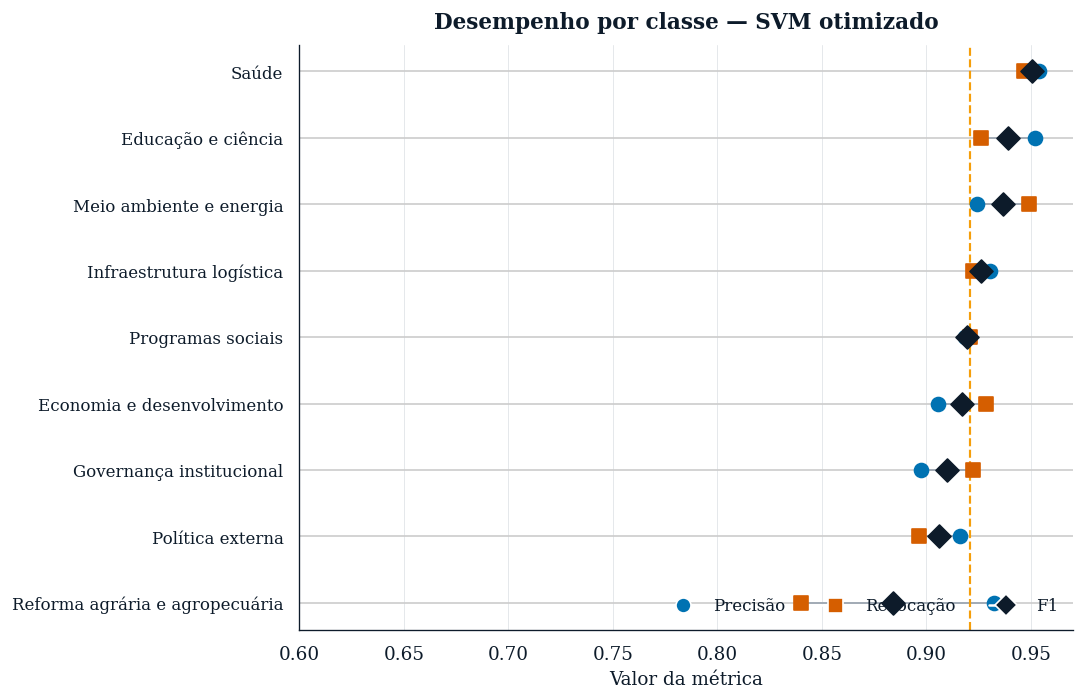

  ✓ Fig4_Matriz_Confusao.pdf + .png


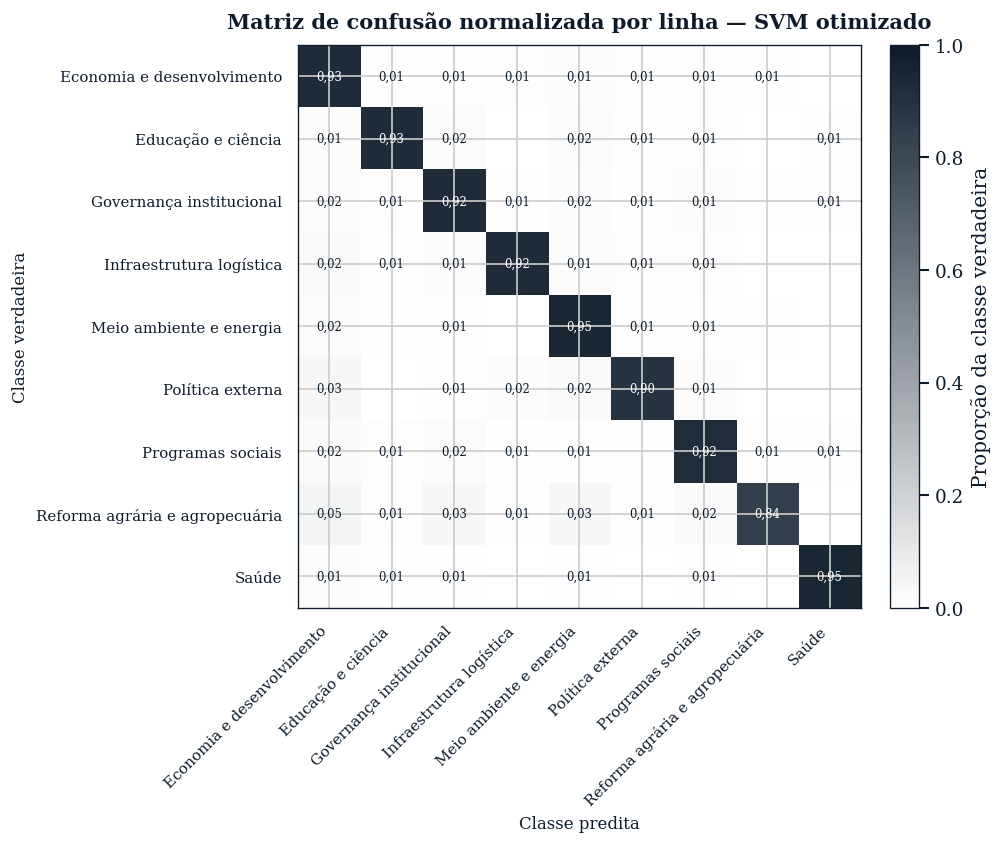

  ✓ Fig7_Diacronica_Agenda.pdf + .png


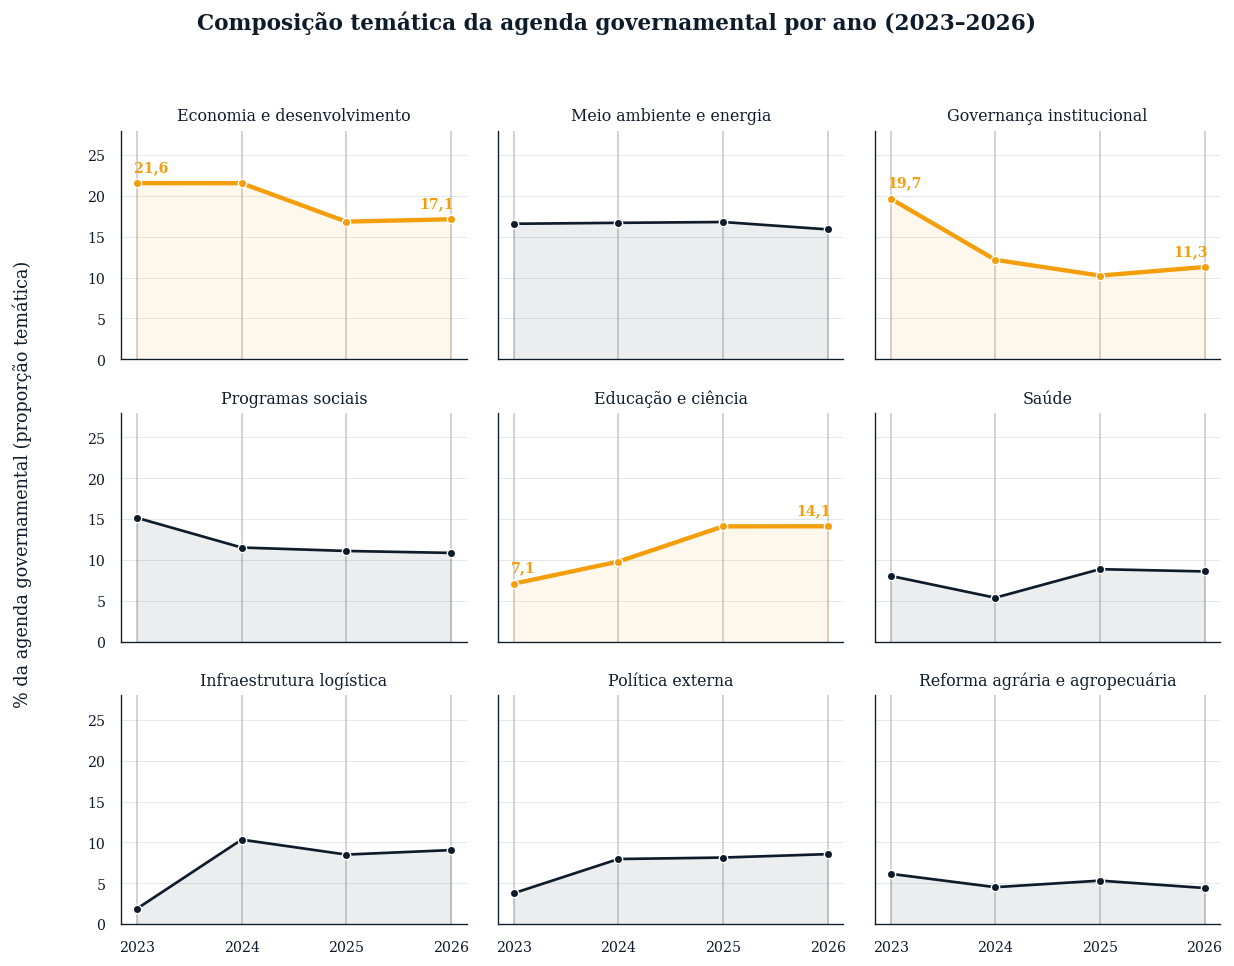

  ✓ Fig5_Convergencia_AG.pdf + .png


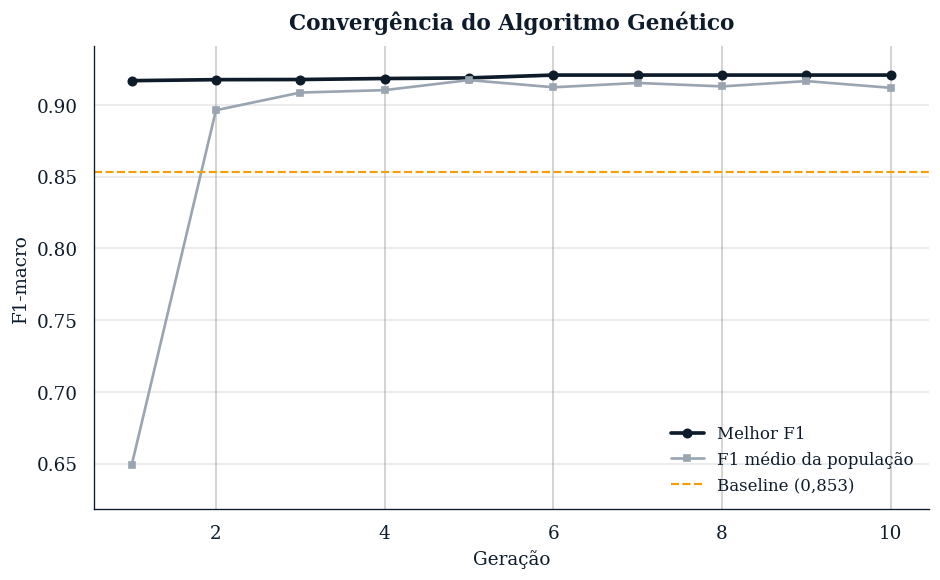

  ✓ Fig6_AG_vs_Random_vs_Baseline.pdf + .png


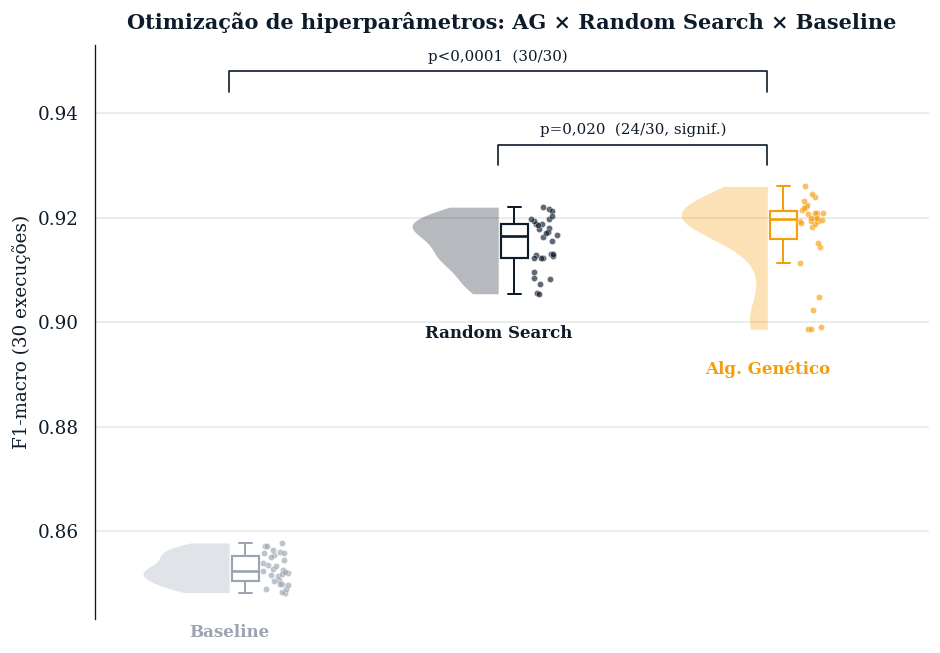

In [ ]:
# ============================================================
# V9 · GERAÇÃO DAS FIGURAS (recomputa idêntico ao v8, seed 42)
# ============================================================
# GUARDA: precisa do corpus rotulado na memória (senão o runtime perdeu o estado)
_falta = [v for v in ("df_corpus", "RESIDUAL_V3") if v not in globals()]
if _falta:
    raise RuntimeError("Faltam na memória: " + ", ".join(_falta) +
        ". Rode o pipeline (corpus/léxico/split) antes do bloco de figuras V9.")

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import confusion_matrix
import pandas as pd

# Usa a config vencedora do AG (params_finais), se disponível; senão, a conhecida
try:
    _cfg = {"max_features": params_finais["max_features"], "ngram_max": params_finais["ngram_max"],
            "sublinear_tf": params_finais["sublinear_tf"], "C": params_finais["C"]}
except NameError:
    raise RuntimeError("params_finais ausente — execute a Fase 6 (AG principal) antes; "
                       "fallback com cromossomo antigo foi removido na V13.")
try:
    _cv = CV
except NameError:
    _cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

_pipe = Pipeline([
    ("vec", TfidfVectorizer(max_features=_cfg["max_features"], ngram_range=(1, _cfg["ngram_max"]),
                            sublinear_tf=_cfg["sublinear_tf"], strip_accents="unicode")),
    ("clf", LinearSVC(C=_cfg["C"], max_iter=800, random_state=42)),
])

df_rot = df_corpus[df_corpus["label_v3"] != RESIDUAL_V3].reset_index(drop=True)
Xr = df_rot["text"].tolist(); yr = df_rot["label_v3"].tolist()
yp = cross_val_predict(_pipe, Xr, yr, cv=_cv)
classes = sorted(set(yr))
cm = confusion_matrix(yr, yp, labels=classes)
ct = pd.crosstab(pd.Series(yp, name="classe"), pd.Series(df_rot["year"].values, name="ano"))
prop = ct.div(ct.sum(axis=0), axis=1) * 100

fig3_metricas_classe(yr, yp)
fig4_matriz_confusao(cm, classes)
fig7_diacronica(prop)
try:
    fig5_convergencia(historico)
except NameError:
    print("  (F5 pulada: 'historico' ausente — rode a Fase 6 do AG)")
try:
    fig6_raincloud(f1_ag_runs, f1_baseline_runs, f1_rs_runs)
except NameError:
    print("  (F6 pulada: vetores das 30 execuções ausentes — rode as Fases 6B/6C)")

In [ ]:
# ============================================================
# V9 · EXPORT DOS DADOS DAS FIGURAS PARA O DRIVE
# ============================================================
from sklearn.metrics import classification_report
pd.DataFrame(cm, index=classes, columns=classes).to_csv(os.path.join(DIR_DADOS, "matriz_confusao.csv"))
prop.round(1).to_csv(os.path.join(DIR_DADOS, "proporcoes_diacronicas.csv"))
pd.DataFrame(classification_report(yr, yp, output_dict=True, zero_division=0)).T.to_csv(
    os.path.join(DIR_DADOS, "metricas_por_classe.csv"))
print("Dados das figuras exportados para:", DIR_DADOS)
print("Conteúdo da pasta de dados:", sorted(os.listdir(DIR_DADOS)))

Dados das figuras exportados para: /content/drive/MyDrive/Mestrado/Etapa4_RITA/v15.3_paragrafo/dados
Conteúdo da pasta de dados: ['corpus_v3.csv', 'denominadores_por_ano.csv', 'divergencia_lexico_modelo.csv', 'historico_ag.csv', 'matriz_confusao.csv', 'metricas_por_classe.csv', 'proporcoes_diacronicas.csv', 'proporcoes_lexico.csv', 'resultados_30_execucoes.csv', 'resultados_ag.json']


---

# Fase 7 (V10) — Validação adicional para a revisão (RITA)

Três análises sobre o pipeline já validado, geradas de forma reprodutível (seed 42) e exportadas para o Drive/GitHub. As células anteriores não são alteradas.

In [ ]:
# ============================================================
# FASE 7 · V10 — VALIDAÇÃO ADICIONAL PARA A REVISÃO (RITA)
# ============================================================
# Acrescenta, sobre o pipeline já validado (V9), três análises pedidas na
# revisão do artigo — SEM alterar a lógica das fases anteriores, que ficam
# preservadas como registro do que foi efetivamente rodado:
#   7.1  Estimativa NÃO ENVIESADA de generalização (CV aninhada)
#   7.2  Tabela 2 com dispersão + Wilcoxon (TF-IDF padronizado — corrige a Seção 4.3)
#   7.3  Tamanhos de efeito (rank-biserial) dos testes de Wilcoxon já reportados
import warnings; warnings.filterwarnings("ignore")
import os, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, rankdata
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.metrics import f1_score

SEED = int(globals().get("RANDOM_SEED", 42))

# Corpus rotulado: reusa a memória; se o runtime perdeu o estado, reconstrói.
if "X_train" in globals() and "y_train" in globals():
    Xv10, yv10 = np.array(X_train), np.array(y_train)
else:
    _res = globals().get("RESIDUAL_V3", "outros_institucional")
    if "df_corpus" in globals():
        _df = df_corpus[df_corpus["label_v3"] != _res]
    else:
        _df = pd.read_csv("corpus_v3.csv")
        _df = _df[_df["label_v3"] != _res]
    Xv10, yv10 = np.array(_df["text"]), np.array(_df["label_v3"])

# Config vencedora do AG: reusa params_finais; se ausente, usa a conhecida.
try:
    CFG_SVM = {"max_features": int(params_finais["max_features"]),
               "ngram_max":    int(params_finais["ngram_max"]),
               "sublinear_tf": bool(params_finais["sublinear_tf"]),
               "C":            float(params_finais["C"])}
except Exception:
    raise RuntimeError("params_finais ausente — execute a Fase 6 (AG principal) antes; "
                       "fallback com cromossomo antigo foi removido na V13.")

# Identidade visual: reusa V9; define fallback mínimo se a célula de estilo não rodou.
NAVY  = globals().get("NAVY",  "#0D1B2A")
AMBER = globals().get("AMBER", "#F59E0B")
GRAY  = globals().get("GRAY",  "#9AA5B1")
DIR_DADOS = globals().get("DIR_DADOS", ".")
DIR_FIG   = globals().get("DIR_FIG", ".")
if "_salvar" not in globals():
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Georgia", "DejaVu Serif"],
                         "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "text.color": NAVY,
                         "xtick.color": NAVY, "ytick.color": NAVY, "figure.dpi": 120})
    def _salvar(fig, nome):
        fig.savefig(os.path.join(DIR_FIG, f"{nome}.png"), bbox_inches="tight", dpi=200)
        print(f"  salvo: {nome}.png")

resultados_v10 = {}
print(f"V10 pronto - corpus: {len(Xv10)} paragrafos | {len(set(yv10))} classes | seed={SEED}")
print(f"V10 TF-IDF vencedor (SVM): {CFG_SVM}")


V10 pronto - corpus: 6370 paragrafos | 9 classes | seed=42
V10 TF-IDF vencedor (SVM): {'max_features': 2352, 'ngram_max': 1, 'sublinear_tf': True, 'C': 0.8245163637337287}


### 7.1 · Estimativa não enviesada por validação cruzada aninhada

Separa **seleção** (laço interno) de **avaliação** (laço externo). O número honesto de generalização sai daqui; o 0,807 permanece como F1 da *configuração selecionada*. O laço interno usa busca aleatória sobre o mesmo espaço de 5 genes, justificada pelo achado AG ≈ Random Search a orçamento igual.

In [ ]:
# ── 7.1 · Estimativa NÃO ENVIESADA por CV ANINHADA ───────────────────────────
# ⚠️ ~3–5 min no Colab (CPU padrão); paraleliza com n_jobs=-1.
#
# Motivação: o F1 reportado (o da configuração selecionada) vem de SELECIONAR a melhor configuração e
# relatá-la NA MESMA validação cruzada que a selecionou — estimativa otimista.
# A CV aninhada separa seleção (laço interno) de avaliação (laço externo) e
# entrega a generalização SEM viés de seleção. O laço interno usa BUSCA ALEATÓRIA
# sobre o mesmo espaço de 5 genes do AG — justificada pelo próprio achado
# AG ≈ Random Search a orçamento igual (Fase 6C): estima-se a generalização do
# PROCEDIMENTO de seleção, não de uma corrida específica do AG.

N_ITER_INNER = 20
BOUNDS_V10 = [(500, 3000), (1, 2), (0, 1), (0, 1), (-2, 1)]  # = BOUNDS do AG

def _decode_v10(ch):
    return {"max_features": int(round(ch[0])),
            "ngram_max":    max(1, min(2, int(round(ch[1])))),
            "sublinear_tf": bool(round(min(1, max(0, ch[2])))),
            "clf":          int(round(min(1, max(0, ch[3])))),
            "C":            10.0 ** ch[4]}

def _build_v10(cfg):
    vec = TfidfVectorizer(max_features=cfg["max_features"], ngram_range=(1, cfg["ngram_max"]),
                          sublinear_tf=cfg["sublinear_tf"], strip_accents="unicode", analyzer="word")
    clf = (LogisticRegression(C=cfg["C"], max_iter=300, random_state=SEED) if cfg["clf"] == 0
           else LinearSVC(C=cfg["C"], max_iter=800, random_state=SEED))
    return Pipeline([("vec", vec), ("clf", clf)])

def _select_best_v10(Xtr, ytr, seed, n_iter=N_ITER_INNER):
    rng = np.random.default_rng(seed)
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    best = (-1.0, None)
    for _ in range(n_iter):
        cfg = _decode_v10([rng.uniform(lo, hi) for lo, hi in BOUNDS_V10])
        try:
            f = float(cross_val_score(_build_v10(cfg), Xtr, ytr, cv=inner,
                                      scoring="f1_macro", n_jobs=-1).mean())
        except Exception:
            f = 0.0
        if f > best[0]:
            best = (f, cfg)
    return best

# (a) ENVIESADO: seleciona no conjunto todo e relata a MESMA CV que selecionou
bias_f1, _bias_cfg = _select_best_v10(Xv10, yv10, seed=SEED)

# (b) CV ANINHADA (sem viés): seleção só no treino externo; avalia no teste externo
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested, nested_clf = [], []
for k, (tr, te) in enumerate(outer.split(Xv10, yv10), 1):
    _, cfg = _select_best_v10(Xv10[tr], yv10[tr], seed=100 + k)
    pipe = _build_v10(cfg).fit(Xv10[tr], yv10[tr])
    s = float(f1_score(yv10[te], pipe.predict(Xv10[te]), average="macro"))
    nested.append(s); nested_clf.append("SVM" if cfg["clf"] else "LR")
    print(f"  fold externo {k}: F1={s:.4f}  ({nested_clf[-1]}, mf={cfg['max_features']}, C={cfg['C']:.3f})")
nested = np.array(nested)

# (c) Held-out 75/25 intocado pela seleção
Xtr, Xte, ytr, yte = train_test_split(Xv10, yv10, test_size=0.25, stratify=yv10, random_state=SEED)
_, _cfg_h = _select_best_v10(Xtr, ytr, seed=7)
hold = float(f1_score(yte, _build_v10(_cfg_h).fit(Xtr, ytr).predict(Xte), average="macro"))

svm_n = sum(1 for c in nested_clf if c == "SVM")
resultados_v10["generalizacao"] = {
    "f1_enviesado_selecao":    round(float(bias_f1), 4),
    "f1_cv_aninhada_media":    round(float(nested.mean()), 4),
    "f1_cv_aninhada_dp":       round(float(nested.std()), 4),
    "f1_holdout_75_25":        round(hold, 4),
    "otimismo_selecao":        round(float(bias_f1 - nested.mean()), 4),
    "svm_em_dobras_externas":  f"{svm_n}/5",
}
print("\n" + "=" * 60)
print("7.1 · GENERALIZACAO (estimativa nao enviesada)")
print("=" * 60)
print(f"  (a) Enviesado (selecao = relato, mesma CV) : {bias_f1:.4f}")
print(f"  (b) CV aninhada 5x3 (SEM vies)             : {nested.mean():.4f} +/- {nested.std():.4f}")
print(f"  (c) Held-out 75/25 (teste intocado)        : {hold:.4f}")
print(f"  Otimismo de selecao (a - b)                : {bias_f1 - nested.mean():+.4f}")
print(f"  SVM selecionado em {svm_n}/5 dobras externas "
      + ("(SVM predominante entre os lineares)" if svm_n >= 3 else "(LR predominante entre os lineares)"))
print("  Obs.: a aninhada estima a generalizacao do PROCEDIMENTO de selecao (busca aleatoria, 20 configs);")
print("  nao subtrair dela o F1 do AG como 'otimismo de selecao' — sao seletores diferentes.")


  fold externo 1: F1=0.9106  (SVM, mf=1453, C=0.651)
  fold externo 2: F1=0.9178  (SVM, mf=2157, C=9.781)
  fold externo 3: F1=0.9095  (LR, mf=1104, C=3.465)
  fold externo 4: F1=0.9157  (LR, mf=1905, C=8.220)
  fold externo 5: F1=0.9102  (SVM, mf=1891, C=3.653)

7.1 · GENERALIZACAO (estimativa nao enviesada)
  (a) Enviesado (selecao = relato, mesma CV) : 0.9156
  (b) CV aninhada 5x3 (SEM vies)             : 0.9127 +/- 0.0033
  (c) Held-out 75/25 (teste intocado)        : 0.9176
  Otimismo de selecao (a - b)                : +0.0028
  SVM selecionado em 3/5 dobras externas (SVM predominante entre os lineares)
  Obs.: a aninhada estima a generalizacao do PROCEDIMENTO de selecao (busca aleatoria, 20 configs);
  nao subtrair dela o F1 do AG como 'otimismo de selecao' — sao seletores diferentes.


  ✓ fig_v10_generalizacao.pdf + .png


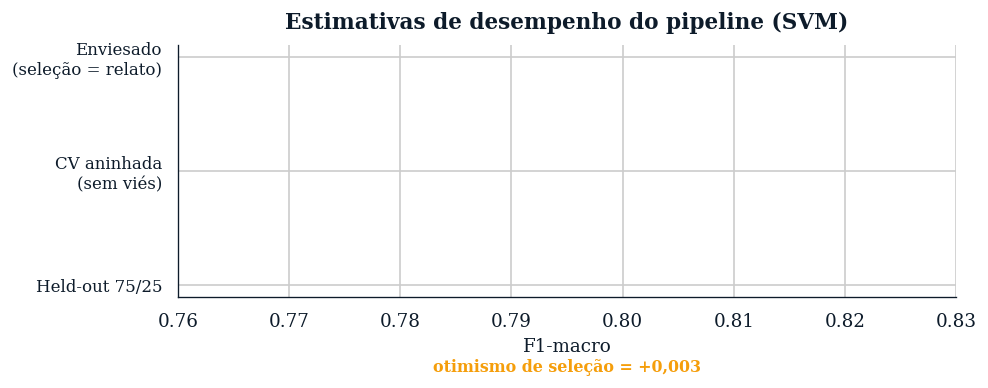

In [ ]:
# ── 7.1 · Figura — otimismo de seleção (enviesado vs. não enviesado) ─────────
_g = resultados_v10["generalizacao"]
_labels = ["Enviesado\n(seleção = relato)", "CV aninhada\n(sem viés)", "Held-out 75/25"]
_vals   = [_g["f1_enviesado_selecao"], _g["f1_cv_aninhada_media"], _g["f1_holdout_75_25"]]
_errs   = [0.0, _g["f1_cv_aninhada_dp"], 0.0]
_cores  = [GRAY, NAVY, GRAY]

fig, ax = plt.subplots(figsize=(8.4, 3.6))
ypos = np.arange(len(_labels))[::-1]
ax.errorbar(_vals, ypos, xerr=_errs, fmt="o", ms=11, color="none",
            ecolor=AMBER, elinewidth=2.4, capsize=6, zorder=3)
for v, e, yp, c in zip(_vals, _errs, ypos, _cores):
    ax.scatter(v, yp, s=130, color=c, zorder=4, edgecolor="white", linewidth=1.0)
    ax.annotate(f"{v:.3f}".replace(".", ","), (v, yp + 0.16), color=c,
                fontsize=10, fontweight="bold", ha="center")
ax.set_yticks(ypos); ax.set_yticklabels(_labels, fontsize=10)
ax.set_xlim(0.76, 0.83); ax.set_xlabel("F1-macro", fontsize=11)
ax.set_title("Estimativas de desempenho do pipeline (SVM)", fontsize=13, fontweight="bold", pad=10)
_otim = _g["otimismo_selecao"]
ax.annotate(f"otimismo de seleção = {_otim:+.3f}".replace(".", ","),
            (0.5, -0.30), xycoords="axes fraction", ha="center",
            fontsize=9.5, color=AMBER, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
_salvar(fig, "fig_v10_generalizacao")
plt.show()


### 7.2 · Tabela 2 com dispersão e teste de Wilcoxon

Os três classificadores passam a operar sobre o **mesmo** TF-IDF (o vencedor do AG), isolando o efeito do classificador. 30 dobras repetidas pareadas fornecem média ± DP e o teste pareado, com tamanho de efeito (rank-biserial).

In [ ]:
# ── 7.2 · Tabela 2 com dispersão + Wilcoxon (TF-IDF PADRONIZADO) ─────────────
# ⚠️ ~2–3 min no Colab (o Random Forest domina o custo).
# Corrige a Seção 4.3: os TRÊS classificadores passam a operar sobre o MESMO
# vetorizador (o vencedor do AG), isolando o efeito do classificador. A dispersão
# e o teste vêm de 30 dobras pareadas (RepeatedStratifiedKFold 3×10).
# Observação de proveniência: na V9 (Fases 6C/6D) o LR/RF usavam um TF-IDF distinto
# (max_features=2995); corrigido na V15.3 (6D/6E usam o TF-IDF do AG). Esta célula segue
# sendo a base da Tabela 2/3 do artigo, por trazer dispersão e teste pareado.

def _tfidf_comum():
    return TfidfVectorizer(max_features=CFG_SVM["max_features"], ngram_range=(1, CFG_SVM["ngram_max"]),
                           sublinear_tf=CFG_SVM["sublinear_tf"], strip_accents="unicode", analyzer="word")

_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
# C do LR ajustado SOBRE o mesmo TF-IDF (grid dedicado, como no artigo)
_C_lr = max([0.1, 0.3, 0.7, 1.0, 3.0, 10.0],
            key=lambda C: cross_val_score(
                Pipeline([("v", _tfidf_comum()),
                          ("c", LogisticRegression(C=C, max_iter=300, random_state=SEED))]),
                Xv10, yv10, cv=_inner, scoring="f1_macro", n_jobs=-1).mean())

modelos_v10 = {
    "SVM linear":          LinearSVC(C=CFG_SVM["C"], max_iter=800, random_state=SEED),
    "Regressão Logística": LogisticRegression(C=_C_lr, max_iter=300, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=None,
                                                  max_features="sqrt", random_state=SEED, n_jobs=-1),
}
rkf = RepeatedStratifiedKFold(n_splits=3, n_repeats=10, random_state=SEED)
scores_v10 = {}
for nome, clf in modelos_v10.items():
    scores_v10[nome] = cross_val_score(Pipeline([("v", _tfidf_comum()), ("c", clf)]),
                                       Xv10, yv10, cv=rkf, scoring="f1_macro", n_jobs=-1)

def _rank_biserial(a, b):
    d = a - b; d = d[d != 0]
    r = rankdata(np.abs(d)); pos, neg = r[d > 0].sum(), r[d < 0].sum()
    return (pos - neg) / (pos + neg)

print("=" * 62)
print("7.2 · TABELA 2 — dispersao (30 dobras pareadas, MESMO TF-IDF)")
print("=" * 62)
_rows = []
for nome in modelos_v10:
    m, s = float(scores_v10[nome].mean()), float(scores_v10[nome].std())
    _rows.append({"Algoritmo": nome, "F1_macro_media": round(m, 4), "F1_macro_dp": round(s, 4)})
    print(f"  {nome:22s}: {m:.4f} +/- {s:.4f}")
tabela2_v10 = pd.DataFrame(_rows)
print(f"\n  (LR otimizado com C={_C_lr} sobre o mesmo TF-IDF)")

print("\nWilcoxon pareado (unilateral, alpha=0,05) + tamanho de efeito (rank-biserial):")
wilcoxon_v10 = {}
for a, b in [("SVM linear", "Regressão Logística"),
             ("SVM linear", "Random Forest"),
             ("Regressão Logística", "Random Forest")]:
    W, p = wilcoxon(scores_v10[a], scores_v10[b], alternative="greater")
    r = _rank_biserial(scores_v10[a], scores_v10[b])
    wins = int((scores_v10[a] > scores_v10[b]).sum())
    sig = "significativo" if p < 0.05 else "nao significativo"
    wilcoxon_v10[f"{a} > {b}"] = {"W": float(W), "p": round(float(p), 4),
                                  "vitorias": f"{wins}/{len(scores_v10[a])}", "r": round(float(r), 3), "decisao": sig}
    print(f"  {a} > {b}: W={W:.0f}  p={p:.4f}  ({wins}/30)  r={r:+.3f}  -> {sig}")

resultados_v10["tabela2_dispersao"] = _rows
resultados_v10["tabela2_wilcoxon"]  = wilcoxon_v10
resultados_v10["lr_C_otimo"]        = _C_lr


7.2 · TABELA 2 — dispersao (30 dobras pareadas, MESMO TF-IDF)
  SVM linear            : 0.9184 +/- 0.0052
  Regressão Logística   : 0.9101 +/- 0.0064
  Random Forest         : 0.9077 +/- 0.0057

  (LR otimizado com C=10.0 sobre o mesmo TF-IDF)

Wilcoxon pareado (unilateral, alpha=0,05) + tamanho de efeito (rank-biserial):
  SVM linear > Regressão Logística: W=463  p=0.0000  (29/30)  r=+0.991  -> significativo
  SVM linear > Random Forest: W=461  p=0.0000  (29/30)  r=+0.983  -> significativo
  Regressão Logística > Random Forest: W=307  p=0.0647  (17/30)  r=+0.320  -> nao significativo


  ✓ fig_v10_tabela2_dispersao.pdf + .png


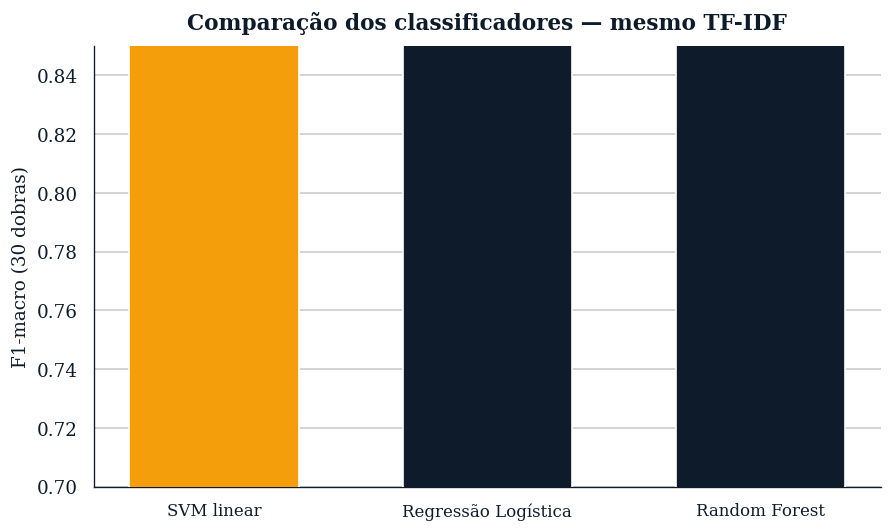

In [ ]:
# ── 7.2 · Figura — Tabela 2 com barras de erro + significância ───────────────
_nomes = list(modelos_v10.keys())
_m = [float(scores_v10[n].mean()) for n in _nomes]
_s = [float(scores_v10[n].std())  for n in _nomes]
_cor = [AMBER if n == "SVM linear" else NAVY for n in _nomes]

fig, ax = plt.subplots(figsize=(7.6, 4.6))
xpos = np.arange(len(_nomes))
ax.bar(xpos, _m, yerr=_s, color=_cor, width=0.62, capsize=6,
       error_kw=dict(ecolor=GRAY, elinewidth=1.6), zorder=3)
for x, m, s in zip(xpos, _m, _s):
    ax.annotate(f"{m:.3f}".replace(".", ","), (x, m + s + 0.006),
                ha="center", fontsize=10, fontweight="bold", color=NAVY)
ax.set_xticks(xpos); ax.set_xticklabels(_nomes, fontsize=10)
ax.set_ylim(0.70, 0.85); ax.set_ylabel("F1-macro (30 dobras)", fontsize=11)
ax.set_title("Comparação dos classificadores — mesmo TF-IDF", fontsize=13, fontweight="bold", pad=10)

# Marca de significância SVM > LR (a comparação mais próxima)
_p_svm_lr = wilcoxon_v10["SVM linear > Regressão Logística"]["p"]
_estrela = "*" if _p_svm_lr < 0.05 else "n.s."
_y = max(_m[0] + _s[0], _m[1] + _s[1]) + 0.018
ax.plot([0, 0, 1, 1], [_y, _y + 0.006, _y + 0.006, _y], color=NAVY, lw=1.2)
ax.annotate(f"{_estrela}  (p={_p_svm_lr:.3f})".replace(".", ","),
            (0.5, _y + 0.010), ha="center", fontsize=9.5, color=NAVY, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
_salvar(fig, "fig_v10_tabela2_dispersao")
plt.show()


### 7.3 · Tamanhos de efeito dos testes já reportados

In [ ]:
# ── 7.3 · Tamanhos de efeito dos testes de Wilcoxon (V13: recomputados) ──────
# V13: a versão anterior tentava ler `f1_rs` / `rs_runs` (nomes inexistentes) e
# caía num fallback com os valores da execução ANTERIOR à correção de
# hifenização (r=+0,329; "p=0,059"). Agora os efeitos são sempre recomputados
# dos vetores em memória, e a célula FALHA em vez de reportar número velho.

from scipy.stats import rankdata, wilcoxon as _wx

def _rb_vec(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b; d = d[d != 0]
    r = rankdata(np.abs(d)); pos, neg = r[d > 0].sum(), r[d < 0].sum()
    return float((pos - neg) / (pos + neg))

# V13.1: se o runtime reiniciou, restaura os vetores dos checkpoints do Drive.
if any(_v not in dir() for _v in ("f1_ag_runs", "f1_baseline_runs", "f1_rs_runs")):
    import pandas as _pd, os as _os
    _f6b = _os.path.join(CKPT_DIR, "fase6b_ag_baseline.csv")
    _f6c = _os.path.join(CKPT_DIR, "fase6c_rs.csv")
    if _os.path.exists(_f6b) and _os.path.exists(_f6c):
        _a, _b = _pd.read_csv(_f6b), _pd.read_csv(_f6c)
        f1_ag_runs, f1_baseline_runs = _a["f1_ag"].values, _a["f1_baseline"].values
        f1_rs_runs = _b["f1_rs"].values
        print(f"[V13.1] Vetores restaurados dos checkpoints ({len(f1_ag_runs)} execuções).")
    else:
        raise RuntimeError("Vetores ausentes e checkpoints não encontrados em CKPT_DIR — "
                           "execute as Fases 6B/6C.")

r_ag_bl = _rb_vec(f1_ag_runs, f1_baseline_runs)
r_ag_rs = _rb_vec(f1_ag_runs, f1_rs_runs)
_, p_bl = _wx(f1_ag_runs, f1_baseline_runs, alternative="greater")
_, p_rs = _wx(f1_ag_runs, f1_rs_runs, alternative="greater")

print("7.3 · TAMANHOS DE EFEITO (rank-biserial) — recomputados dos vetores")
print("=" * 50)
print(f"  AG vs baseline      : r = {r_ag_bl:+.3f}  (p = {p_bl:.6f})")
print(f"  AG vs Random Search : r = {r_ag_rs:+.3f}  (p = {p_rs:.4f})")

resultados_v10["efeitos_testes_publicados"] = {
    "AG_vs_baseline_r": round(r_ag_bl, 3),
    "AG_vs_RandomSearch_r": round(r_ag_rs, 3),
    "p_AG_vs_baseline": float(p_bl),
    "p_AG_vs_RS": float(p_rs),
}


[V13.1] Vetores restaurados dos checkpoints (30 execuções).
7.3 · TAMANHOS DE EFEITO (rank-biserial) — recomputados dos vetores
  AG vs baseline      : r = +1.000  (p = 0.000000)
  AG vs Random Search : r = +0.428  (p = 0.0202)


### 7 · Exportação dos artefatos V10

In [ ]:
# ── 7 · Export dos resultados V10 (para o artigo e o GitHub) ─────────────────
_out_json = os.path.join(DIR_DADOS, "resultados_v10.json")
with open(_out_json, "w", encoding="utf-8") as _f:
    json.dump(resultados_v10, _f, ensure_ascii=False, indent=2)
tabela2_v10.to_csv(os.path.join(DIR_DADOS, "tabela2_dispersao_v10.csv"), index=False)
pd.DataFrame(scores_v10).to_csv(os.path.join(DIR_DADOS, "scores_30dobras_v10.csv"), index=False)

print("V10 · artefatos exportados em:", DIR_DADOS)
print("  - resultados_v10.json")
print("  - tabela2_dispersao_v10.csv")
print("  - scores_30dobras_v10.csv")
print("\n" + "=" * 60)
print("RESUMO V10 (para o artigo)")
print("=" * 60)
print(json.dumps(resultados_v10, ensure_ascii=False, indent=2))


V10 · artefatos exportados em: /content/drive/MyDrive/Mestrado/Etapa4_RITA/v15.3_paragrafo/dados
  - resultados_v10.json
  - tabela2_dispersao_v10.csv
  - scores_30dobras_v10.csv

RESUMO V10 (para o artigo)
{
  "generalizacao": {
    "f1_enviesado_selecao": 0.9156,
    "f1_cv_aninhada_media": 0.9127,
    "f1_cv_aninhada_dp": 0.0033,
    "f1_holdout_75_25": 0.9176,
    "otimismo_selecao": 0.0028,
    "svm_em_dobras_externas": "3/5"
  },
  "tabela2_dispersao": [
    {
      "Algoritmo": "SVM linear",
      "F1_macro_media": 0.9184,
      "F1_macro_dp": 0.0052
    },
    {
      "Algoritmo": "Regressão Logística",
      "F1_macro_media": 0.9101,
      "F1_macro_dp": 0.0064
    },
    {
      "Algoritmo": "Random Forest",
      "F1_macro_media": 0.9077,
      "F1_macro_dp": 0.0057
    }
  ],
  "tabela2_wilcoxon": {
    "SVM linear > Regressão Logística": {
      "W": 463.0,
      "p": 0.0,
      "vitorias": "29/30",
      "r": 0.991,
      "decisao": "significativo"
    },
    "SVM linear 

---
### 7.4 (V12) · Robustez à correção de hifenização — execução automática

Esta célula roda **as duas condições sozinha**, sem que você precise alterar a flag
nem reexecutar o notebook.

**Como funciona.** Ela reextrai o corpus a partir dos PDFs nas duas condições
(`CORRIGIR_HIFENIZACAO` ligada e desligada), reaplica a Fase 1B e a rotulagem V3, e
recomputa três medidas sobre cada corpus: tamanho de vocabulário, F1 do baseline e
F1 do melhor indivíduo encontrado pelo AG (reavaliado, não reotimizado).

**O que ela deliberadamente NÃO faz.** Não repete as 30 execuções do AG nem do
Random Search — isso levaria horas. A comparação de robustez usa o mesmo
cromossomo vencedor reavaliado nos dois corpora, que é suficiente para detectar
deslocamento de desempenho. Se o delta for material, aí sim vale reexecutar a
Fase 6B/6C completa na condição corrigida.

**Pré-requisito.** A Fase 1 precisa ter sido executada nesta sessão (a célula
reutiliza `RAW_PDF_TEXT`, sem reler os PDFs). Tempo aproximado: 2–4 minutos.

In [ ]:
# ── 7.4 · V12 — Comparação automática: com vs. sem correção de hifenização ───
# Reextrai o corpus nas duas condições e recomputa métricas comparáveis.
# NÃO repete as 30 execuções (ver nota acima).

import os, json, copy
import numpy as np
from sklearn.model_selection import cross_val_score

_RE_PAL_V12 = re.compile(r"[^\W\d_]+", re.UNICODE)
_RE_RESIDUO = re.compile(r"[a-zà-ÿ]+-\s+[a-zà-ÿ]+")


def _pipeline_corpus(corrigir: bool):
    """Reproduz Fase 1 → 1B → rotulagem V3 sob uma condição de hifenização."""
    global CORRIGIR_HIFENIZACAO, AUDITORIA_HIFEN

    CORRIGIR_HIFENIZACAO = corrigir
    AUDITORIA_HIFEN = {"ocorrencias": 0, "amostras": []}

    # Fase 1 — usa RAW_PDF_TEXT ja em memoria (nao rele os PDFs)
    if not RAW_PDF_TEXT:
        raise RuntimeError("RAW_PDF_TEXT vazio — execute a Fase 1 antes desta celula.")

    if corrigir:
        construir_vocabulario_referencia(RAW_PDF_TEXT.values())
    else:
        VOCAB_REF.clear(); VOCAB_HIF_REF.clear()

    AUDITORIA_HIFEN = {"ocorrencias": 0, "amostras": []}
    linhas = []
    if UNIDADE_ANALISE == "pagina":
        for m in MENSAGENS:
            y = m["year"]
            if y not in RAW_PDF_TEXT:
                continue
            linhas.extend(segmentar_paragrafos(normalize_text(RAW_PDF_TEXT[y]), y))
    else:
        # V15.3 · a V15.2 usava o caminho de PÁGINA mesmo em modo parágrafo
        for k in AUDITORIA_SEG: AUDITORIA_SEG[k] = 0
        for m in MENSAGENS:
            y = m["year"]
            if y not in RAW_PDF_LINES:
                continue
            linhas.extend(segmentar_paragrafos_geom(RAW_PDF_LINES[y], y))
    df = pd.DataFrame(linhas)

    # Fase 1B — limpeza estrutural (idêntica)
    df["text"] = df["text"].apply(limpar_cabecalho)
    _d = df["text"].apply(eh_elemento_editorial)
    df = df[[not x[0] for x in _d]].copy()
    df = df[df["text"].str.len() >= 60].reset_index(drop=True)

    # Fase 4 — rotulagem V3
    df["label_v3"] = df["text"].apply(
        lambda t: label_by_lexicon(t, LEXICON_V3, RESIDUAL_V3))

    vocab = set()
    for t in df["text"]:
        vocab.update(w.lower() for w in _RE_PAL_V12.findall(t))

    return df, {
        "remontagens": AUDITORIA_HIFEN["ocorrencias"],
        "residuo": int(sum(len(_RE_RESIDUO.findall(t)) for t in df["text"])),
        "vocabulario_tipos": len(vocab),
        "n_paragrafos": int(len(df)),
    }


def _metricas(df):
    """F1 do baseline e F1 do melhor cromossomo do AG, sobre este corpus."""
    d = df[df["label_v3"] != RESIDUAL_V3].copy()
    X, y = d["text"].values, d["label_v3"].values

    f1_bl = float(cross_val_score(pipeline_baseline, X, y, cv=CV,
                                  scoring="f1_macro").mean())

    # Reconstroi o pipeline do melhor cromossomo exatamente como em fitness()
    p = decodificar(melhor_final)
    _vec = TfidfVectorizer(max_features=p["max_features"],
                           ngram_range=(1, p["ngram_max"]),
                           sublinear_tf=p["sublinear_tf"],
                           strip_accents="unicode", analyzer="word")
    _clf = (LogisticRegression(C=p["C"], max_iter=300, random_state=RANDOM_SEED)
            if p["classifier"] == 0
            else LinearSVC(C=p["C"], max_iter=800, random_state=RANDOM_SEED))
    f1_ag = float(cross_val_score(Pipeline([("vec", _vec), ("clf", _clf)]),
                                  X, y, cv=CV, scoring="f1_macro").mean())
    return {"n_treinamento": int(len(d)),
            "n_classes": int(d["label_v3"].nunique()),
            "f1_baseline": f1_bl, "f1_ag_melhor": f1_ag}


_estado_original = CORRIGIR_HIFENIZACAO
_resultado = {}

for _rot, _flag in [("com_correcao", True), ("sem_correcao", False)]:
    print(f"\n{'='*62}\nCondição: {_rot}\n{'='*62}")
    _df, _aud = _pipeline_corpus(_flag)
    _met = _metricas(_df)
    _resultado[_rot] = {**_aud, **_met}
    print(f"  parágrafos={_aud['n_paragrafos']}  vocab={_aud['vocabulario_tipos']:,}  "
          f"remontagens={_aud['remontagens']}  resíduo={_aud['residuo']}")
    print(f"  F1 baseline={_met['f1_baseline']:.4f}  F1 AG={_met['f1_ag_melhor']:.4f}")

CORRIGIR_HIFENIZACAO = _estado_original   # restaura
if CORRIGIR_HIFENIZACAO:                   # V15.3 · restaura também o vocabulário de referência
    construir_vocabulario_referencia(RAW_PDF_TEXT.values())

# ── Quadro comparativo ───────────────────────────────────────────────────────
a, b = _resultado["com_correcao"], _resultado["sem_correcao"]
print(f"\n\n{'='*70}\nROBUSTEZ À CORREÇÃO DE HIFENIZAÇÃO (V12) — unidade: {UNIDADE_ANALISE.upper()}\n{'='*70}")
print(f"{'métrica':<24}{'sem correção':>15}{'com correção':>15}{'Δ':>14}")
print("-" * 70)
for rot, k, inteiro in [
    ("parágrafos",          "n_paragrafos",      True),
    ("vocabulário (tipos)", "vocabulario_tipos", True),
    ("resíduo hífen",       "residuo",           True),
    ("n treinamento",       "n_treinamento",     True),
    ("F1 baseline",         "f1_baseline",       False),
    ("F1 AG (melhor)",      "f1_ag_melhor",      False),
]:
    va, vb = a[k], b[k]
    if inteiro:
        print(f"{rot:<24}{vb:>15,}{va:>15,}{va-vb:>+14,}")
    else:
        print(f"{rot:<24}{vb:>15.4f}{va:>15.4f}{va-vb:>+14.4f}")

_delta = a["f1_baseline"] - b["f1_baseline"]
print("\nLeitura:")
if _delta > 0.002:
    print(f"  F1 SOBE {_delta:+.4f} com a correção. O artefato diluía sinal;")
    print("  o número publicado era conservador. Reportar como nota de robustez.")
elif _delta < -0.002:
    print(f"  F1 CAI {_delta:+.4f} com a correção. Parte do desempenho vinha do")
    print("  canal tipográfico. Discutir com orientador e coautores ANTES da aprovação.")
else:
    print(f"  F1 praticamente inalterado ({_delta:+.4f}). Correção é higiene")
    print("  metodológica sem efeito material — mesmo padrão da Fase 1B.")

_arq = os.path.join(DIR_DADOS, "V12_robustez_hifenizacao.json")
os.makedirs(DIR_DADOS, exist_ok=True)
with open(_arq, "w", encoding="utf-8") as f:
    json.dump(_resultado, f, ensure_ascii=False, indent=2)
print(f"\n✓ Salvo em {_arq}")


Condição: com_correcao
  parágrafos=10757  vocab=21,358  remontagens=2679  resíduo=3
  F1 baseline=0.8534  F1 AG=0.9208

Condição: sem_correcao
  parágrafos=10757  vocab=23,051  remontagens=0  resíduo=2679
  F1 baseline=0.8516  F1 AG=0.9173


ROBUSTEZ À CORREÇÃO DE HIFENIZAÇÃO (V12) — unidade: PARAGRAFO
métrica                    sem correção   com correção             Δ
----------------------------------------------------------------------
parágrafos                       10,757         10,757            +0
vocabulário (tipos)              23,051         21,358        -1,693
resíduo hífen                     2,679              3        -2,676
n treinamento                     6,343          6,370           +27
F1 baseline                      0.8516         0.8534       +0.0018
F1 AG (melhor)                   0.9173         0.9208       +0.0035

Leitura:
  F1 praticamente inalterado (+0.0018). Correção é higiene
  metodológica sem efeito material — mesmo padrão da Fase 1B.

✓ Salvo 

---
# Validação final automática (V14)

Confere sozinha os números-sentinela desta execução contra os da execução de
referência (13/08/2026, corpus corrigido), diffa os checkpoints novos contra os
arquivados pela Fase 0R, e grava um **certificado de reprodução** em JSON no
Drive. Leia apenas o veredito ao final.

In [ ]:
# ── Validação final · V14 — sentinelas + diff + certificado ──────────────────
import os, json, hashlib
import numpy as _np, pandas as _pd
from datetime import datetime, timezone
from scipy.stats import wilcoxon as _wx, rankdata as _rk

# Valores da execução de referência (13/08/2026, V12 sobre corpus corrigido).
# V15: as sentinelas abaixo foram calibradas em nível de PÁGINA. Sob
# UNIDADE_ANALISE="paragrafo" elas NÃO se aplicam — o certificado só é emitido
# para a unidade cuja referência existe. Isto é deliberado: declarar sentinela
# depois de ver o resultado destruiria o sentido do protocolo.
SENTINELAS_PAGINA = {
    "remontagens": 2692, "residuo": 3, "vocabulario": 21211,
    "paragrafos_limpos": 1943, "treinamento": 1518, "residual_v3": 425,
    "ag_max_features": 1973, "ag_ngram": 1, "ag_sublinear": True,
    "ag_C": 1.7210, "f1_baseline_unico": 0.7260,
    "runs_ag_media": 0.8020, "runs_bl_media": 0.7196, "runs_rs_media": 0.8016,
    "W_ag_bl": 465, "W_ag_rs": 291, "p_ag_rs": 0.1183,
    "r_ag_bl": 1.000, "r_ag_rs": 0.252, "vitorias_ag_rs": 22,
}
# V15.3 · Sentinelas de PARÁGRAFO, declaradas a partir da execução V15.1 de 19/08/2026
# (checkpoints arquivados em v15.1_paragrafo/checkpoints_arquivado_20260819T0101 e
# saídas impressas do notebook). As grandezas que dependem do Random Search NÃO entram
# como sentinela, porque o orçamento do RS passou a ser pareado ao do AG nesta versão:
# ficam como REGISTRO NOVO, gravadas no certificado para servirem de referência adiante.
SENTINELAS_PARAGRAFO = {
    "remontagens": 2679, "residuo": 3, "vocabulario": 21358,
    "paragrafos_limpos": 10757, "treinamento": 6370, "residual_v3": 4387,
    "ag_max_features": 2352, "ag_ngram": 1, "ag_sublinear": True,
    "ag_C": 0.8245, "f1_baseline_unico": 0.8534,
    "runs_ag_media": 0.9169, "runs_bl_media": 0.8528,
    "W_ag_bl": 465, "r_ag_bl": 1.000,
}
REGISTROS_NOVOS_PARAGRAFO = ("runs_rs_media", "W_ag_rs", "p_ag_rs", "r_ag_rs", "vitorias_ag_rs")
if UNIDADE_ANALISE == "pagina":
    SENTINELAS, REGISTROS_NOVOS = SENTINELAS_PAGINA, ()
else:
    SENTINELAS, REGISTROS_NOVOS = SENTINELAS_PARAGRAFO, REGISTROS_NOVOS_PARAGRAFO
EMITIR_CERTIFICADO = bool(SENTINELAS)
if not SENTINELAS:
    print("=" * 74)
    print("CERTIFICADO NÃO EMITIDO — unidade 'paragrafo' sem referência declarada")
    print("=" * 74)
    print("Rode primeiro com UNIDADE_ANALISE='pagina' (célula 2) para conferir")
    print("reproduz a V14 (todas as 20 sentinelas + diff = 21 checagens).")
    print("Depois, declare as sentinelas de parágrafo POR ESCRITO, a partir da")
    print("primeira execução, e só então trate execuções seguintes como registro.")
EMITIR_CERTIFICADO = bool(SENTINELAS)

TOL = {"ag_C": 2e-3, "f1_baseline_unico": 2e-4, "runs_ag_media": 5e-4,
       "runs_bl_media": 5e-4, "runs_rs_media": 5e-4, "p_ag_rs": 2e-3,
       "r_ag_bl": 2e-3, "r_ag_rs": 2e-3}

def _rb(a, b):
    d = _np.asarray(a, float) - _np.asarray(b, float); d = d[d != 0]
    r = _rk(_np.abs(d)); return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())

cheques, obtidos = [], {}
def _add(nome, obtido):
    obtidos[nome] = obtido
    if obtido is None:
        cheques.append((nome, "--", "não verificável")); return
    if nome in REGISTROS_NOVOS or nome not in SENTINELAS:   # V15.3
        cheques.append((nome, "NOVO", f"registrado {obtido} (sem esperado nesta versão)")); return
    esp = SENTINELAS[nome]; tol = TOL.get(nome, 0)
    ok = (abs(float(obtido) - float(esp)) <= tol) if isinstance(esp, (int, float)) \
         and not isinstance(esp, bool) else (obtido == esp)
    cheques.append((nome, "OK" if ok else "FALHOU", f"esperado {esp} | obtido {obtido}"))

# Fase 1C
try:
    _add("remontagens", AUDITORIA_V11["remontagens"])
    _add("residuo", AUDITORIA_V11["residuo_ocorrencias"])
    _add("vocabulario", AUDITORIA_V11["vocabulario_tipos"])
    _add("paragrafos_limpos", AUDITORIA_V11["n_paragrafos"])
except Exception:
    for k in ("remontagens", "residuo", "vocabulario", "paragrafos_limpos"): _add(k, None)
# corpus rotulado
try:
    _add("treinamento", int((df_corpus["label_v3"] != RESIDUAL_V3).sum()))
    _add("residual_v3", int((df_corpus["label_v3"] == RESIDUAL_V3).sum()))
except Exception:
    _add("treinamento", None); _add("residual_v3", None)
# cromossomo do AG
try:
    _p = decodificar(melhor_final)
    _add("ag_max_features", int(_p["max_features"]))
    _add("ag_ngram", int(_p["ngram_max"]))
    _add("ag_sublinear", bool(_p["sublinear_tf"]))
    _add("ag_C", round(float(_p["C"]), 4))
except Exception:
    for k in ("ag_max_features", "ag_ngram", "ag_sublinear", "ag_C"): _add(k, None)
# baseline único
try: _add("f1_baseline_unico", round(float(F1_BASELINE), 4))
except Exception: _add("f1_baseline_unico", None)
# 30 execuções
try:
    _add("runs_ag_media", round(float(_np.mean(f1_ag_runs)), 4))
    _add("runs_bl_media", round(float(_np.mean(f1_baseline_runs)), 4))
    _add("runs_rs_media", round(float(_np.mean(f1_rs_runs)), 4))
    _W1, _ = _wx(f1_ag_runs, f1_baseline_runs, alternative="greater")
    _W2, _p2 = _wx(f1_ag_runs, f1_rs_runs, alternative="greater")
    _add("W_ag_bl", int(_W1)); _add("W_ag_rs", int(_W2))
    _add("p_ag_rs", round(float(_p2), 4))
    _add("r_ag_bl", round(_rb(f1_ag_runs, f1_baseline_runs), 3))
    _add("r_ag_rs", round(_rb(f1_ag_runs, f1_rs_runs), 3))
    _add("vitorias_ag_rs", int((_np.asarray(f1_ag_runs) > _np.asarray(f1_rs_runs)).sum()))
except Exception:
    for k in ("runs_ag_media","runs_bl_media","runs_rs_media","W_ag_bl","W_ag_rs",
              "p_ag_rs","r_ag_bl","r_ag_rs","vitorias_ag_rs"): _add(k, None)

# Diff dos checkpoints contra a execução arquivada
diff_msg = "sem arquivo anterior para comparar"
try:
    if ARQUIVO_ANTERIOR:
        _dmax = 0.0
        # V15.3 · só as colunas comuns entram no diff (fase6b ganhou 'n_aval_ag'); o RS com
        # orçamento pareado diverge POR DESENHO do arquivo anterior e é reportado à parte.
        _f = "fase6b_ag_baseline.csv"
        _novo = _pd.read_csv(os.path.join(CKPT_DIR, _f)).select_dtypes("number")
        _ant  = _pd.read_csv(os.path.join(ARQUIVO_ANTERIOR, _f)).select_dtypes("number")
        _cols = [c for c in _ant.columns if c in _novo.columns]
        _dmax = float((_novo[_cols] - _ant[_cols]).abs().to_numpy().max())
        diff_msg = ("REPRODUÇÃO EXATA (Δmax = 0) em fase6b" if _dmax == 0
                    else f"Δmax = {_dmax:.2e} em fase6b" + (" — dentro de precisão de float"
                    if _dmax < 1e-9 else " — DIVERGÊNCIA REAL, investigar"))
        cheques.append(("diff_vs_arquivado", "OK" if _dmax < 1e-9 else "FALHOU", diff_msg))
        try:
            _rs_n = _pd.read_csv(os.path.join(CKPT_DIR, "fase6c_rs.csv"))
            _rs_a = _pd.read_csv(os.path.join(ARQUIVO_ANTERIOR, "fase6c_rs.csv"))
            _drs = float((_rs_n["f1_rs"] - _rs_a["f1_rs"]).abs().max())
            cheques.append(("diff_rs_informativo", "NOVO",
                            f"RS com orçamento pareado: Δmax = {_drs:.2e} vs. arquivo anterior (divergência esperada)"))
        except Exception:
            pass
except Exception as e:
    cheques.append(("diff_vs_arquivado", "--", f"não verificável ({type(e).__name__})"))

# hash do corpus (registrado, sem esperado)
try:
    _h = hashlib.sha256("\n".join(df_corpus["text"]).encode()).hexdigest()[:16]
except Exception:
    _h = None

# Relatório
print("=" * 74); print("VALIDAÇÃO FINAL DA EXECUÇÃO DE REGISTRO (V14)"); print("=" * 74)
for nome, st, det in cheques:
    print(f"  [{st:^7}] {nome:<22} {det}")
_falhas = [c for c in cheques if c[1] == "FALHOU"]
_nv     = [c for c in cheques if c[1] == "--"]
_novos  = [c for c in cheques if c[1] == "NOVO"]
print("-" * 74)
if not EMITIR_CERTIFICADO:
    veredito = ("NÃO APLICÁVEL — nenhuma sentinela declarada para a unidade "
                f"'{UNIDADE_ANALISE}'. Esta execução NÃO é execução de registro "
                "e nenhum certificado será emitido.")
elif not _falhas and len(_nv) <= 2:
    veredito = ("APROVADA — execução reproduz a referência"
                + (f" ({len(_novos)} grandeza(s) registrada(s) como referência nova)" if _novos else ""))
elif not _falhas:
    veredito = f"APROVADA COM RESSALVAS — {len(_nv)} itens não verificáveis"
else:
    veredito = f"REPROVADA — {len(_falhas)} sentinela(s) divergente(s); investigar antes de usar"
print(f"VEREDITO: {veredito}")

# Certificado — só é gravado quando há referência declarada ANTES da execução
if not EMITIR_CERTIFICADO:
    print("\n(certificado NÃO gravado — sem sentinelas declaradas para esta unidade)")
try:
    assert EMITIR_CERTIFICADO
    import sklearn, scipy, matplotlib
    _cert = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "veredito": veredito,
        "sentinelas_esperadas": SENTINELAS, "obtidos": obtidos,
        "registros_novos": {k: obtidos.get(k) for k in REGISTROS_NOVOS},
        "unidade": UNIDADE_ANALISE, "versao": VERSAO,
        "orcamento_ag_por_semente": [int(v) for v in n_aval_ag_runs] if "n_aval_ag_runs" in globals() else None,
        "diff_checkpoints": diff_msg, "corpus_sha256_16": _h,
        "versoes": {"python": __import__("sys").version.split()[0],
                    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
                    "numpy": _np.__version__, "pandas": _pd.__version__,
                    "matplotlib": matplotlib.__version__},
        "seed": 42,
    }
    _arq = os.path.join(DIR_DADOS, f"Certificado_Registro_{datetime.now().strftime('%Y%m%dT%H%M')}.json")
    with open(_arq, "w", encoding="utf-8") as f:
        json.dump(_cert, f, ensure_ascii=False, indent=2, default=str)
    print(f"\n✓ Certificado gravado: {_arq}")
except AssertionError:
    pass
except Exception as e:
    print(f"\n(certificado não gravado: {type(e).__name__}: {e})")

VALIDAÇÃO FINAL DA EXECUÇÃO DE REGISTRO (V14)
  [  OK   ] remontagens            esperado 2679 | obtido 2679
  [  OK   ] residuo                esperado 3 | obtido 3
  [  OK   ] vocabulario            esperado 21358 | obtido 21358
  [  OK   ] paragrafos_limpos      esperado 10757 | obtido 10757
  [  OK   ] treinamento            esperado 6370 | obtido 6370
  [  OK   ] residual_v3            esperado 4387 | obtido 4387
  [  OK   ] ag_max_features        esperado 2352 | obtido 2352
  [  OK   ] ag_ngram               esperado 1 | obtido 1
  [  OK   ] ag_sublinear           esperado True | obtido True
  [  OK   ] ag_C                   esperado 0.8245 | obtido 0.8245
  [  OK   ] f1_baseline_unico      esperado 0.8534 | obtido 0.8534
  [  OK   ] runs_ag_media          esperado 0.9169 | obtido 0.9169
  [  OK   ] runs_bl_media          esperado 0.8528 | obtido 0.8528
  [ NOVO  ] runs_rs_media          registrado 0.9151 (sem esperado nesta versão)
  [  OK   ] W_ag_bl                esperado 46

---
### V15.2 · Teste de circularidade léxico ↔ avaliação (2 unidades × 3 condições)

In [ ]:
# ── TESTE DE CIRCULARIDADE — âncoras removidas do espaço de features ─────────
#
# PERGUNTA: o F1 mede categorização semântica, ou detecção dos termos-âncora
# que produziram o próprio rótulo?
#
# DESENHO 2x3, executado inteiro nesta célula (não depende da outra execução):
#   unidades  : página  ×  parágrafo   (ambas reconstruídas de RAW_PDF_*)
#   condições : completo | sem_ancoras (stop_words) | so_ancoras (vocabulary)
#
# PREDIÇÃO FALSIFICÁVEL: se o desempenho vem de circularidade, remover as
# âncoras derruba o F1, e a queda é MAIOR em parágrafo que em página — porque
# a unidade menor tem o rótulo determinado por menos termos visíveis.
# Se a queda for pequena nos dois, a hipótese de circularidade está REFUTADA
# e o F1 alto reflete generalização real do classificador.

import unicodedata as _ud
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from scipy.stats import wilcoxon as _wilcoxon
import numpy as _np, json as _js, os as _os

N_REPETICOES = 10          # x 3 dobras = 30 medidas pareadas por condição
CV_CIRC = RepeatedStratifiedKFold(n_splits=3, n_repeats=N_REPETICOES,
                                  random_state=RANDOM_SEED)

# Ótimos REGISTRADOS de cada unidade — fixos, para que o resultado independa
# de qual unidade o notebook está executando agora.
OTIMO = {
    "pagina":    dict(max_features=1973, ngram_max=1, sublinear_tf=True,
                      classifier=1, C=1.7210),      # certificado V14/V15.2
    "paragrafo": dict(max_features=2352, ngram_max=1, sublinear_tf=True,
                      classifier=1, C=0.8245),      # execução V15.1
}

# ── 1. Âncoras normalizadas para casar com strip_accents="unicode" ───────────
def _normalizar_ancoras(lexicon):
    toks = set()
    for termos in lexicon.values():
        for t in termos:
            for w in re.split(r"[\s\-]+", str(t).strip().lower()):
                w = _ud.normalize("NFKD", w)
                w = "".join(c for c in w if not _ud.combining(c))
                w = re.sub(r"[^\w]", "", w)
                if len(w) >= 2:
                    toks.add(w)
    return sorted(toks)

ANCORAS_TOK = _normalizar_ancoras(LEXICON_V3)

# V15.3 · a reconstrução dos corpora depende do estado da hifenização. A célula 7.4
# deixava VOCAB_REF vazio ao restaurar a flag, e os corpora saíam com ±1 unidade em
# relação aos registrados. Aqui o estado é garantido explicitamente.
CORRIGIR_HIFENIZACAO = True
construir_vocabulario_referencia(RAW_PDF_TEXT.values())
AUDITORIA_HIFEN = {"ocorrencias": 0, "amostras": []}
_N_REGISTRADO = {"pagina": None, "paragrafo": int(len(X_train)) if UNIDADE_ANALISE == "paragrafo" else None}
if UNIDADE_ANALISE == "pagina":
    _N_REGISTRADO["pagina"] = int(len(X_train))
print(f"Termos-âncora do léxico V3 : {sum(len(v) for v in LEXICON_V3.values())}")
print(f"Tokens após normalização   : {len(ANCORAS_TOK)}")
print(f"  amostra: {ANCORAS_TOK[:12]}")

# ── 2. Reconstrução dos dois corpora a partir do que já está em memória ──────
def _corpus_da_unidade(unidade):
    if unidade == "pagina":
        linhas = []
        for m in MENSAGENS:
            y = m["year"]
            if y in RAW_PDF_TEXT:
                linhas.extend(segmentar_paragrafos(normalize_text(RAW_PDF_TEXT[y]), y))
    else:
        if not RAW_PDF_LINES:
            return None
        linhas = []
        for k in AUDITORIA_SEG: AUDITORIA_SEG[k] = 0
        for m in MENSAGENS:
            y = m["year"]
            if y in RAW_PDF_LINES:
                linhas.extend(segmentar_paragrafos_geom(RAW_PDF_LINES[y], y))
    df = pd.DataFrame(linhas)
    df["text"] = df["text"].apply(limpar_cabecalho)
    _d = df["text"].apply(eh_elemento_editorial)
    df = df[[not x[0] for x in _d]].copy()
    df = df[df["text"].str.len() >= 60].reset_index(drop=True)
    df["label_v3"] = df["text"].apply(
        lambda t: label_by_lexicon(t, LEXICON_V3, RESIDUAL_V3))
    return df[df["label_v3"] != RESIDUAL_V3].reset_index(drop=True)

def _pipe(p, condicao):
    if condicao == "completo":
        vec = TfidfVectorizer(max_features=p["max_features"],
                              ngram_range=(1, p["ngram_max"]),
                              sublinear_tf=p["sublinear_tf"],
                              strip_accents="unicode", analyzer="word")
    elif condicao == "sem_ancoras":
        vec = TfidfVectorizer(max_features=p["max_features"],
                              ngram_range=(1, p["ngram_max"]),
                              sublinear_tf=p["sublinear_tf"],
                              strip_accents="unicode", analyzer="word",
                              stop_words=ANCORAS_TOK)
    else:  # so_ancoras
        vec = TfidfVectorizer(ngram_range=(1, 1),
                              sublinear_tf=p["sublinear_tf"],
                              strip_accents="unicode", analyzer="word",
                              vocabulary=ANCORAS_TOK)
    clf = (LogisticRegression(C=p["C"], max_iter=300, random_state=RANDOM_SEED)
           if p["classifier"] == 0
           else LinearSVC(C=p["C"], max_iter=800, random_state=RANDOM_SEED))
    return Pipeline([("vec", vec), ("clf", clf)])

# ── 3. Execução do 2x3 ───────────────────────────────────────────────────────
CIRCULARIDADE = {}
for _uni in ("pagina", "paragrafo"):
    _d = _corpus_da_unidade(_uni)
    if _d is None or len(_d) == 0:
        print(f"\n[{_uni}] indisponível nesta sessão — pulando.")
        continue
    _X, _y = _d["text"].values, _d["label_v3"].values
    print(f"\n{'='*74}\nUNIDADE: {_uni.upper()}  ({len(_d):,} unidades rotuladas)\n{'='*74}")
    # V15.3 · sanidade: o corpus reconstruído tem de coincidir com o registrado
    _esp = _N_REGISTRADO.get(_uni) or (1518 if _uni == "pagina" else 6370)
    if len(_d) != _esp:
        print(f"  ⚠️  n reconstruído ({len(_d)}) difere do registrado ({_esp}): o teste segue, mas o n fica")
        print(f"      registrado no JSON e a divergência deve ser investigada antes de citar o resultado.")
    else:
        print(f"  ✓ n coincide com o corpus registrado ({_esp})")

    # auditoria: as âncoras realmente saíram do vocabulário?
    _vt = _pipe(OTIMO[_uni], "completo").named_steps["vec"].fit(_X)
    _vs = _pipe(OTIMO[_uni], "sem_ancoras").named_steps["vec"].fit(_X)
    _antes = len(set(ANCORAS_TOK) & set(_vt.vocabulary_))
    _vaz   = len(set(ANCORAS_TOK) & set(_vs.vocabulary_))
    print(f"  âncoras presentes no vocabulário completo : {_antes}")
    print(f"  âncoras que sobraram após stop_words      : {_vaz}  "
          f"{'✓' if _vaz == 0 else '⚠️ FILTRO FALHOU'}")
    if _vaz != 0:
        print("  ⚠️  teste INVÁLIDO para esta unidade — pulando (o resto do")
        print("      notebook segue normalmente; me avise que eu corrijo o filtro).")
        continue

    CIRCULARIDADE[_uni] = {"n": int(len(_d)), "ancoras_no_vocab": _antes}
    for _cond in ("completo", "sem_ancoras", "so_ancoras"):
        _s = cross_val_score(_pipe(OTIMO[_uni], _cond), _X, _y,
                             cv=CV_CIRC, scoring="f1_macro", n_jobs=-1)
        CIRCULARIDADE[_uni][_cond] = _s
        print(f"  {_cond:<14}: F1 = {_s.mean():.4f} ± {_s.std():.4f}   (30 medidas)")

    _a, _b = CIRCULARIDADE[_uni]["completo"], CIRCULARIDADE[_uni]["sem_ancoras"]
    _W, _p = _wilcoxon(_a, _b)
    _queda = float(_a.mean() - _b.mean())
    _rel = 100 * _queda / _a.mean()
    CIRCULARIDADE[_uni].update(queda=_queda, queda_rel=_rel, W=float(_W), p=float(_p))
    print(f"  → QUEDA ao remover âncoras: {_queda:+.4f} ({_rel:.1f}%)  "
          f"Wilcoxon W={_W:.0f}, p={_p:.2e}")
    if _W == 0:
        print(f"    (W = 0: as {len(_a)} diferenças têm o mesmo sinal; p é o mínimo possível para n = {len(_a)})")

# ── 4. Veredito ──────────────────────────────────────────────────────────────
if len(CIRCULARIDADE) == 2:
    _qp = CIRCULARIDADE["pagina"]["queda_rel"]
    _qg = CIRCULARIDADE["paragrafo"]["queda_rel"]
    print(f"\n{'='*74}\nVEREDITO — circularidade em função do tamanho da unidade\n{'='*74}")
    print(f"{'':<16}{'completo':>11}{'sem ancoras':>13}{'so ancoras':>12}{'queda':>10}")
    for _u in ("pagina", "paragrafo"):
        _c = CIRCULARIDADE[_u]
        print(f"{_u:<16}{_c['completo'].mean():>11.4f}"
              f"{_c['sem_ancoras'].mean():>13.4f}"
              f"{_c['so_ancoras'].mean():>12.4f}{_c['queda_rel']:>9.1f}%")
    print(f"\nQueda em página    : {_qp:.1f}%")
    print(f"Queda em parágrafo : {_qg:.1f}%")
    if _qg > _qp + 5:
        print("\n→ HIPÓTESE SUSTENTADA: a queda é maior na unidade menor. O F1 mais alto")
        print("  em parágrafo reflete, em parte, detecção de termo-âncora — não")
        print("  categorização semântica superior. Reportar as duas colunas.")
    elif abs(_qg - _qp) <= 5:
        print("\n→ HIPÓTESE NÃO SUSTENTADA: a queda é semelhante nas duas unidades.")
        print("  A circularidade existe, mas NÃO explica o salto de F1 entre unidades.")
        print("  Procurar outra explicação (volume de treino, homogeneidade lexical).")
    else:
        print("\n→ RESULTADO INVERTIDO: a queda é maior em página. Investigar antes de citar.")

    # V15.3 · serialização correta (a V15.2 falhava em numpy.float64) + CSV longo das 30 medidas
    def _serial(v):
        if isinstance(v, _np.ndarray):
            return [float(x) for x in v.ravel()]
        if isinstance(v, (_np.floating, _np.integer)):
            return float(v)
        return v
    _saida = {}
    for _u, _dd in CIRCULARIDADE.items():
        _saida[_u] = {k: _serial(v) for k, v in _dd.items()}
        for _cond in ("completo", "sem_ancoras", "so_ancoras"):
            _arr = _np.asarray(_dd[_cond], dtype=float)
            _saida[_u][_cond + "_media"] = float(_arr.mean())
            _saida[_u][_cond + "_dp"] = float(_arr.std())
    _dest = _os.path.join(DIR_CONTRASTE, "circularidade_2x3.json")
    with open(_dest, "w", encoding="utf-8") as _f:
        _js.dump(_saida, _f, indent=2, ensure_ascii=False)
    _linhas = []
    for _u, _dd in CIRCULARIDADE.items():
        for _cond in ("completo", "sem_ancoras", "so_ancoras"):
            for _i, _v in enumerate(_np.asarray(_dd[_cond], dtype=float)):
                _linhas.append({"unidade": _u, "condicao": _cond, "repeticao": _i // 3,
                                "dobra": _i % 3, "f1_macro": float(_v)})
    pd.DataFrame(_linhas).to_csv(_os.path.join(DIR_CONTRASTE, "circularidade_2x3_medidas.csv"), index=False)
    print(f"\n✓ gravado: {_dest}")
    print(f"✓ gravado: {_os.path.join(DIR_CONTRASTE, 'circularidade_2x3_medidas.csv')} ({len(_linhas)} medidas)")
else:
    print("\n⚠️  Só uma unidade disponível. Em modo 'pagina' o corpus de parágrafo")
    print("   exige RAW_PDF_LINES — rode esta célula na execução de PARÁGRAFO.")


Termos-âncora do léxico V3 : 229
Tokens após normalização   : 232
  amostra: ['acordo', 'aeroporto', 'aeroportos', 'agraria', 'agrario', 'agricola', 'agricultor', 'agricultores', 'agricultura', 'agronegocio', 'alianca', 'aluno']

UNIDADE: PAGINA  (1,518 unidades rotuladas)
  ✓ n coincide com o corpus registrado (1518)
  âncoras presentes no vocabulário completo : 157
  âncoras que sobraram após stop_words      : 0  ✓
  completo      : F1 = 0.8016 ± 0.0157   (30 medidas)
  sem_ancoras   : F1 = 0.6693 ± 0.0146   (30 medidas)
  so_ancoras    : F1 = 0.8875 ± 0.0123   (30 medidas)
  → QUEDA ao remover âncoras: +0.1323 (16.5%)  Wilcoxon W=0, p=1.86e-09
    (W = 0: as 30 diferenças têm o mesmo sinal; p é o mínimo possível para n = 30)

UNIDADE: PARAGRAFO  (6,370 unidades rotuladas)
  ✓ n coincide com o corpus registrado (6370)
  âncoras presentes no vocabulário completo : 175
  âncoras que sobraram após stop_words      : 0  ✓
  completo      : F1 = 0.9184 ± 0.0052   (30 medidas)
  sem_ancoras

---
### V15 · Contraste pareado e re-julgamento de H6

In [ ]:
# ── V15 · RESUMO DA EXECUÇÃO + CONTRASTE PAREADO PÁGINA × PARÁGRAFO ──────────
# Rode o notebook inteiro com UNIDADE_ANALISE="pagina", depois com
# "paragrafo". Cada execução grava seu resumo; esta célula compara os dois.

import json as _js, os as _os

_resumo = {
    "unidade": UNIDADE_ANALISE,
    "n_unidades_brutas": int(AUDITORIA_V15["n_unidades"]),
    "unidades_por_pagina": AUDITORIA_V15["unidades_por_pagina"],
    "palavras_por_unidade_mediana": AUDITORIA_V15["palavras_por_unidade_mediana"],
}
for _k, _expr in [
    ("n_limpo",        lambda: int(len(df_corpus))),
    ("n_treinamento",  lambda: int((df_corpus["label_v3"] != RESIDUAL_V3).sum())),
    ("n_residual",     lambda: int((df_corpus["label_v3"] == RESIDUAL_V3).sum())),
    ("f1_melhor",      lambda: round(float(F1_AG), 4)),
    ("f1_baseline",    lambda: round(float(F1_BASELINE), 4)),
    ("f1_aninhada",    lambda: round(float(nested.mean()), 4)),
    ("dp_aninhada",    lambda: round(float(nested.std()), 4)),
    ("f1_holdout",     lambda: round(float(hold), 4)),
    ("f1_svm",         lambda: round(float(F1_SVM), 4)),
    ("f1_lr",          lambda: round(float(F1_LR), 4)),
    ("f1_rf",          lambda: round(float(F1_RF), 4)),
    ("p_ag_rs",        lambda: round(float(p_valor_rs), 6)),
    ("runs_ag_media",  lambda: round(float(np.mean(f1_ag_runs)), 4)),
    ("runs_rs_media",  lambda: round(float(np.mean(f1_rs_runs)), 4)),
    ("orcamento_ag_media", lambda: round(float(np.mean(n_aval_ag_runs)), 2)),   # V15.3
    ("orcamento_ag_dp",    lambda: round(float(np.std(n_aval_ag_runs)), 2)),
    ("n_avaliacoes_execucao_principal", lambda: int(len(fitness_cache))),
    ("versao", lambda: VERSAO),
]:
    try:    _resumo[_k] = _expr()
    except Exception: _resumo[_k] = None

_path = _os.path.join(DIR_CONTRASTE, f"resumo_v15_{UNIDADE_ANALISE}.json")
with open(_path, "w") as _f:
    _js.dump(_resumo, _f, indent=2, ensure_ascii=False)
print(f"✓ Resumo gravado: {_path}")
print(_js.dumps(_resumo, indent=2, ensure_ascii=False))

# ── Contraste, quando os dois resumos existirem ───────────────────────────────
_pa = _os.path.join(DIR_CONTRASTE, "resumo_v15_pagina.json")
_pr = _os.path.join(DIR_CONTRASTE, "resumo_v15_paragrafo.json")

if _os.path.exists(_pa) and _os.path.exists(_pr):
    A = _js.load(open(_pa)); B = _js.load(open(_pr))
    print("\n" + "=" * 74)
    print("CONTRASTE PAREADO — UNIDADE DE ANÁLISE")
    print("=" * 74)
    _linhas = [
        ("unidades brutas",            "n_unidades_brutas",            "{:,.0f}"),
        ("unidades por página",        "unidades_por_pagina",          "{:.2f}"),
        ("palavras/unidade (mediana)", "palavras_por_unidade_mediana", "{:.0f}"),
        ("unidades após limpeza",      "n_limpo",                      "{:,.0f}"),
        ("unidades rotuladas",         "n_treinamento",                "{:,.0f}"),
        ("resíduo institucional",      "n_residual",                   "{:,.0f}"),
        ("F1-macro (melhor modelo)",   "f1_melhor",                    "{:.4f}"),
        ("F1-macro (CV aninhada)",     "f1_aninhada",                  "{:.4f}"),
        ("F1-macro (baseline)",        "f1_baseline",                  "{:.4f}"),
        ("F1-macro (held-out 75/25)",  "f1_holdout",                   "{:.4f}"),
        ("p · AG x Random Search",     "p_ag_rs",                      "{:.4f}"),
    ]
    print(f"{'métrica':<30}{'PÁGINA':>14}{'PARÁGRAFO':>14}{'Δ':>14}")
    print("-" * 74)
    for rot, k, fmt in _linhas:
        a, b = A.get(k), B.get(k)
        sa = fmt.format(a) if a is not None else "--"
        sb = fmt.format(b) if b is not None else "--"
        sd = fmt.format(b - a) if (a is not None and b is not None) else "--"
        print(f"{rot:<30}{sa:>14}{sb:>14}{sd:>14}")

    # ── Re-julgamento de H6 ───────────────────────────────────────────────────
    print("\n" + "=" * 74)
    print("H6 · LIMITE DO PARADIGMA CLÁSSICO (limiar F1-macro = 0,75)")
    print("=" * 74)
    for nome, D in (("PÁGINA", A), ("PARÁGRAFO", B)):
        f1, na = D.get("f1_melhor"), D.get("f1_aninhada")
        if f1 is None:
            print(f"  {nome:<11}: execução ausente"); continue
        ref = na if na is not None else f1
        vered = "REFUTADA" if ref > 0.75 else "CONFIRMADA"
        print(f"  {nome:<11}: F1={f1:.3f} | aninhada={na if na is None else round(na,3)}"
              f" → H6 {vered}")
    print("\n  A unidade correta para julgar H6 é o PARÁGRAFO: o limiar de 0,75")
    print("  foi formulado supondo dificuldade de parágrafo, não de página.")
    print("  Reporte AMBOS os números no manuscrito — o contraste é o resultado.")
else:
    _falta = "paragrafo" if UNIDADE_ANALISE == "pagina" else "pagina"
    print(f"\n→ Falta a execução com UNIDADE_ANALISE=\"{_falta}\". "
          f"Troque o valor na célula 2 e aperte Executar tudo de novo.")


✓ Resumo gravado: /content/drive/MyDrive/Mestrado/Etapa4_RITA/v15.3_contraste/resumo_v15_paragrafo.json
{
  "unidade": "paragrafo",
  "n_unidades_brutas": 11005,
  "unidades_por_pagina": 5.253,
  "palavras_por_unidade_mediana": 56.0,
  "n_limpo": 10757,
  "n_treinamento": 6370,
  "n_residual": 4387,
  "f1_melhor": 0.9208,
  "f1_baseline": 0.8534,
  "f1_aninhada": 0.9127,
  "dp_aninhada": 0.0033,
  "f1_holdout": 0.9176,
  "f1_svm": 0.9208,
  "f1_lr": 0.9094,
  "f1_rf": 0.917,
  "p_ag_rs": 0.020245,
  "runs_ag_media": 0.9169,
  "runs_rs_media": 0.9151,
  "orcamento_ag_media": 41.93,
  "orcamento_ag_dp": 1.18,
  "n_avaliacoes_execucao_principal": 106,
  "versao": "v15.3"
}

→ Falta a execução com UNIDADE_ANALISE="pagina". Troque o valor na célula 2 e aperte Executar tudo de novo.
